<a href="https://colab.research.google.com/github/GiannisPro153/thesis-sd-cross-attention/blob/main/thesis_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpreting Text-to-Image Diffusion Models

Code for the bachelor thesis (NKUA, Department of Informatics and
Telecommunications). It finds where Stable Diffusion v1.4 writes a concept
(Van Gogh, nighttime, red) in its cross-attention layers, and tests it by
adding, subtracting and deleting that direction.

- Runs on Colab with an A100. Sections follow Chapter 6 of the thesis.
- The concept directions are computed once (section 1.1) and saved in `DATA_DIR`.
- All results are saved in `DRIVE_DIR`.
- Outputs are from one full run with `diffusers` 0.41, so a few numbers differ
  slightly from the thesis.

## 0. Setup

In [ ]:
# ============================================================
# DiffusionPatchingPipeline - Minimal Working Example
# Google Colab Pro+ (A100), SD v1.4
# ============================================================

# Do NOT pin diffusers==0.27.2 any more: that release imports
# `cached_download` from huggingface_hub, which was removed in hub 0.26,
# so it raises ImportError on a current Colab image. Install an up-to-date
# stack instead; the pipeline below supports both old and new APIs.
# If the import still fails right after this, use Runtime > Restart session
# and run this cell again - pip cannot swap an already-imported package.
!pip install -q -U "diffusers>=0.31.0" "transformers>=4.45.0" accelerate safetensors
# torchao on the Colab image is older than what new diffusers expects
# (ImportError: FqnToConfig); diffusers does not need it, so remove it.
!pip uninstall -y -q torchao
import os
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "60"   # default is 10s
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"  # disable the fast transfer, it's flakier on bad days

import torch
import torch.nn.functional as F
from diffusers import StableDiffusionPipeline, DDIMScheduler
from transformers import CLIPProcessor, CLIPModel
from PIL import Image

import diffusers, transformers, huggingface_hub
print(f"diffusers {diffusers.__version__} | "
      f"transformers {transformers.__version__} | "
      f"huggingface_hub {huggingface_hub.__version__} | "
      f"torch {torch.__version__}")

DEVICE = "cuda"
DTYPE = torch.float16
MODEL_ID = "CompVis/stable-diffusion-v1-4"
NUM_STEPS = 50
GUIDANCE = 7.5
SEED = 0


class DiffusionPatchingPipeline:
    def __init__(self, model_id=MODEL_ID):
        self.pipe = StableDiffusionPipeline.from_pretrained(
            model_id, torch_dtype=DTYPE, safety_checker=None
        ).to(DEVICE)
        self.pipe.scheduler = DDIMScheduler.from_config(self.pipe.scheduler.config)
        self.unet = self.pipe.unet

        # Collect cross-attention modules: in SD1.4 these are attn2 in
        # every BasicTransformerBlock inside the UNet.
        self.xattn_layers = {}
        for name, module in self.unet.named_modules():
            if name.endswith("attn2"):
                self.xattn_layers[name] = module
        print(f"Found {len(self.xattn_layers)} cross-attention layers")

        # State for hooks
        self._cache = {}        # {(step, layer, type): tensor}
        self._inject = {}       # {(step, layer, type): tensor}
        self._mode = None       # "cache" | "inject" | None
        self._current_step = None
        self._hooks = []

    # -------- Hook installation --------
    def _make_hook(self, layer_name):
        """Capture or inject q, k, v, and output of a cross-attn layer."""
        def hook(module, inputs, output):
            step = self._current_step
            # `output` is the attention output tensor
            key = (step, layer_name, "out")
            if self._mode == "cache":
                self._cache[key] = output.detach().clone()
            elif self._mode == "inject" and key in self._inject:
                return self._inject[key].to(output.dtype).to(output.device)
            return output
        return hook

    def _install_hooks(self):
        self._remove_hooks()
        for name, module in self.xattn_layers.items():
            h = module.register_forward_hook(self._make_hook(name))
            self._hooks.append(h)

    def _remove_hooks(self):
        for h in self._hooks:
            h.remove()
        self._hooks = []

    # -------- Prompt encoding (diffusers version compatibility) --------
    def _encode_prompt_compat(self, prompt):
        """Return the [uncond; cond] text embedding across diffusers versions.

        Older diffusers exposed the private `_encode_prompt`, which already
        returned the two halves concatenated. Newer releases removed it in
        favour of the public `encode_prompt`, which returns the tuple
        (prompt_embeds, negative_prompt_embeds); the CFG batch has to be
        assembled here, uncond first, to match the `.chunk(2)` below.
        """
        pipe = self.pipe
        if hasattr(pipe, "encode_prompt"):
            out = pipe.encode_prompt(
                prompt, device=DEVICE, num_images_per_prompt=1,
                do_classifier_free_guidance=True, negative_prompt=None,
            )
            prompt_embeds, negative_prompt_embeds = out[0], out[1]
            return torch.cat([negative_prompt_embeds, prompt_embeds])
        return pipe._encode_prompt(
            prompt, device=DEVICE, num_images_per_prompt=1,
            do_classifier_free_guidance=True, negative_prompt=None,
        )

    # -------- Step tracking via scheduler wrapper --------
    def _run_unet_loop(self, prompt, generator):
        """Manual denoising loop so we know the current step index."""
        pipe = self.pipe
        # Encode prompt (with CFG) - see _encode_prompt_compat above
        text_emb = self._encode_prompt_compat(prompt)
        # Init latents
        latents = torch.randn(
            (1, pipe.unet.config.in_channels, 64, 64),
            generator=generator, device=DEVICE, dtype=DTYPE,
        ) * pipe.scheduler.init_noise_sigma

        pipe.scheduler.set_timesteps(NUM_STEPS, device=DEVICE)
        for i, t in enumerate(pipe.scheduler.timesteps):
            self._current_step = i
            latent_in = torch.cat([latents] * 2)
            latent_in = pipe.scheduler.scale_model_input(latent_in, t)
            with torch.no_grad():
                noise_pred = self.unet(latent_in, t, encoder_hidden_states=text_emb).sample
            uncond, cond = noise_pred.chunk(2)
            noise_pred = uncond + GUIDANCE * (cond - uncond)
            latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample

        # Decode
        with torch.no_grad():
            image = pipe.vae.decode(latents / pipe.vae.config.scaling_factor).sample
        image = (image / 2 + 0.5).clamp(0, 1)
        image = (image[0].permute(1, 2, 0).float().cpu().numpy() * 255).astype("uint8")
        return Image.fromarray(image)

    # -------- Public API --------
    def run_and_cache(self, prompt, seed=SEED):
        self._cache = {}
        self._mode = "cache"
        self._install_hooks()
        try:
            gen = torch.Generator(device=DEVICE).manual_seed(seed)
            img = self._run_unet_loop(prompt, gen)
        finally:
            self._remove_hooks()
            self._mode = None
        return img, self._cache

    def run_with_patch(self, patch_dict, seed=SEED, prompt=""):
        """patch_dict: {(step, layer_name, 'out'): tensor}"""
        self._inject = patch_dict
        self._mode = "inject"
        self._install_hooks()
        try:
            gen = torch.Generator(device=DEVICE).manual_seed(seed)
            img = self._run_unet_loop(prompt, gen)
        finally:
            self._remove_hooks()
            self._mode = None
            self._inject = {}
        return img


# ============================================================
# Test cell: one patching experiment
# ============================================================
pipeline = DiffusionPatchingPipeline()

source_prompt = "a photograph of a red sports car"
print("Caching activations from source run...")
source_img, cache = pipeline.run_and_cache(source_prompt, seed=SEED)

# Pick ONE (step, layer) to patch
target_step = 10
target_layer = list(pipeline.xattn_layers.keys())[5]  # arbitrary mid-network layer
print(f"Patching step={target_step}, layer={target_layer}")

patch = {(target_step, target_layer, "out"): cache[(target_step, target_layer, "out")]}
patched_img = pipeline.run_with_patch(patch, seed=SEED, prompt="")

# CLIP similarity between patched image and source prompt
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

with torch.no_grad():
    inputs = clip_proc(text=[source_prompt], images=[patched_img],
                       return_tensors="pt", padding=True).to(DEVICE)
    out = clip_model(**inputs)
    img_emb = F.normalize(out.image_embeds, dim=-1)
    txt_emb = F.normalize(out.text_embeds, dim=-1)
    sim = (img_emb @ txt_emb.T).item()

print(f"CLIP similarity (patched image ↔ source prompt): {sim:.4f}")
source_img.save("source.png")
patched_img.save("patched.png")

diffusers 0.41.0 | transformers 5.19.0 | huggingface_hub 1.33.0 | torch 2.11.0+cu130


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP similarity (patched image ↔ source prompt): 0.1472


In [ ]:
# ============================================================
# 0.2  Drive, artifact directory, and the shared sweep configuration
#
# The concept directions and diff-norm matrices are read from DATA_DIR;
# every result, figure and image of this run is written to DRIVE_DIR.
# The setup
# cell above already built `pipeline`, `clip_model` and `clip_proc` in this
# kernel, so the sanity check below is only a guard against running the
# cells out of order.
# ============================================================
import os
import time
import numpy as np
import matplotlib.pyplot as plt
# show figures inline as JPEG so the executed notebook stays small
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")
import torch
import torch.nn.functional as F

# --- Mount Google Drive so we can persist directions for later experiments ---
from google.colab import drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

DATA_DIR  = "/content/drive/MyDrive/thesis"             # directions (read)
DRIVE_DIR = "/content/drive/MyDrive/thesis_public_run"  # results (written)
os.makedirs(DRIVE_DIR, exist_ok=True)
print(f"Saving artifacts to: {DRIVE_DIR}")

# --- Sanity check: thesis.ipynb cell 0 must have been run ---
required_globals = ["pipeline", "clip_model", "clip_proc",
                    "DEVICE", "DTYPE", "NUM_STEPS"]
missing = [g for g in required_globals if g not in globals()]
if missing:
    raise RuntimeError(
        f"Missing globals: {missing}. Run section 0.1 (the "
        f"DiffusionPatchingPipeline + CLIP setup cell) before this one."
    )

layer_names_all = list(pipeline.xattn_layers.keys())
N_LAYERS = len(layer_names_all)
print(f"Using pipeline with {N_LAYERS} cross-attention layers, "
      f"{NUM_STEPS} denoising steps")

# --- Experiment config ---
SEEDS = [0, 1, 2, 3, 4]                       # 5 seeds for diff-of-means
N_SEEDS = len(SEEDS)
STEERING_SEED = 0                             # fixed seed for steering runs
EARLY_MAX_STEPS = [5, 10, 15, 20, 25, 50]     # 50 = no filter (full baseline)
ALPHAS = [0.0, 1.0, 2.0, 3.0, 5.0, 8.0]
TOP_K = 20                                    # cells used as the steering set

print(f"SEEDS={SEEDS}  EARLY_MAX_STEPS={EARLY_MAX_STEPS}  "
      f"ALPHAS={ALPHAS}  TOP_K={TOP_K}")

Mounted at /content/drive
Saving artifacts to: /content/drive/MyDrive/thesis_public_run
Using pipeline with 16 cross-attention layers, 50 denoising steps
SEEDS=[0, 1, 2, 3, 4]  EARLY_MAX_STEPS=[5, 10, 15, 20, 25, 50]  ALPHAS=[0.0, 1.0, 2.0, 3.0, 5.0, 8.0]  TOP_K=20


## 1. Concept directions

Difference of means over 20 prompt pairs and 5 seeds, for every layer and
step. Set `RECOMPUTE_DIRECTIONS = True` to compute them (about 30 minutes).

In [ ]:
# ============================================================
# 5-seed difference-of-means for all 3 concepts, saved to Drive
# Runtime: ~25-30 min on A100 (5 seeds * 20 pairs * 2 prompts * 3 concepts
# = 600 generations at ~2.3s each ~= 23 min, plus accumulator overhead).
# All sums are kept on CPU to avoid GPU OOM during the long run.
# ============================================================

# ---------- Prompt pairs (copied from thesis.ipynb cells 14, 10, 12) ----------
VG_PAIRS = [
    ("a van gogh painting of a cat",                "a photograph of a cat"),
    ("a van gogh painting of a dog",                "a photograph of a dog"),
    ("a van gogh painting of a sunflower",          "a photograph of a sunflower"),
    ("a van gogh painting of a wheat field",        "a photograph of a wheat field"),
    ("a van gogh painting of a cypress tree",       "a photograph of a cypress tree"),
    ("a van gogh painting of a starry night sky",   "a photograph of a starry night sky"),
    ("a van gogh painting of a village",            "a photograph of a village"),
    ("a van gogh painting of a bedroom",            "a photograph of a bedroom"),
    ("a van gogh painting of a chair",              "a photograph of a chair"),
    ("a van gogh painting of a cafe at night",      "a photograph of a cafe at night"),
    ("a van gogh painting of a self portrait",      "a photograph of a man"),
    ("a van gogh painting of a woman",              "a photograph of a woman"),
    ("a van gogh painting of a boat",               "a photograph of a boat"),
    ("a van gogh painting of a bridge",             "a photograph of a bridge"),
    ("a van gogh painting of a mountain landscape", "a photograph of a mountain landscape"),
    ("a van gogh painting of a vase of flowers",    "a photograph of a vase of flowers"),
    ("a van gogh painting of a road",               "a photograph of a road"),
    ("a van gogh painting of an olive grove",       "a photograph of an olive grove"),
    ("a van gogh painting of a church",             "a photograph of a church"),
    ("a van gogh painting of a harbor",             "a photograph of a harbor"),
]

NIGHT_PAIRS = [
    ("a photograph of a city street at night",   "a photograph of a city street during the day"),
    ("a photograph of a forest at night",        "a photograph of a forest during the day"),
    ("a photograph of a beach at night",         "a photograph of a beach during the day"),
    ("a photograph of a mountain at night",      "a photograph of a mountain during the day"),
    ("a photograph of a house at night",         "a photograph of a house during the day"),
    ("a photograph of a bridge at night",        "a photograph of a bridge during the day"),
    ("a photograph of a park at night",          "a photograph of a park during the day"),
    ("a photograph of a lake at night",          "a photograph of a lake during the day"),
    ("a photograph of a church at night",        "a photograph of a church during the day"),
    ("a photograph of a castle at night",        "a photograph of a castle during the day"),
    ("a photograph of a garden at night",        "a photograph of a garden during the day"),
    ("a photograph of a harbor at night",        "a photograph of a harbor during the day"),
    ("a photograph of a village at night",       "a photograph of a village during the day"),
    ("a photograph of a highway at night",       "a photograph of a highway during the day"),
    ("a photograph of a cathedral at night",     "a photograph of a cathedral during the day"),
    ("a photograph of a farm at night",          "a photograph of a farm during the day"),
    ("a photograph of a skyscraper at night",    "a photograph of a skyscraper during the day"),
    ("a photograph of a river at night",         "a photograph of a river during the day"),
    ("a photograph of a train station at night", "a photograph of a train station during the day"),
    ("a photograph of a town square at night",   "a photograph of a town square during the day"),
]

RED_PAIRS = [
    ("a photograph of a red car",       "a photograph of a car"),
    ("a photograph of a red flower",    "a photograph of a flower"),
    ("a photograph of a red dress",     "a photograph of a dress"),
    ("a photograph of a red house",     "a photograph of a house"),
    ("a photograph of a red bird",      "a photograph of a bird"),
    ("a photograph of a red ball",      "a photograph of a ball"),
    ("a photograph of a red door",      "a photograph of a door"),
    ("a photograph of a red boat",      "a photograph of a boat"),
    ("a photograph of a red umbrella",  "a photograph of an umbrella"),
    ("a photograph of a red bicycle",   "a photograph of a bicycle"),
    ("a photograph of a red chair",     "a photograph of a chair"),
    ("a photograph of a red shoe",      "a photograph of a shoe"),
    ("a photograph of a red hat",       "a photograph of a hat"),
    ("a photograph of a red butterfly", "a photograph of a butterfly"),
    ("a photograph of a red phone",     "a photograph of a phone"),
    ("a photograph of a red backpack",  "a photograph of a backpack"),
    ("a photograph of a red sofa",      "a photograph of a sofa"),
    ("a photograph of a red suitcase",  "a photograph of a suitcase"),
    ("a photograph of a red tent",      "a photograph of a tent"),
    ("a photograph of a red mug",       "a photograph of a mug"),
]


def compute_diff_of_means_5seeds(pairs, concept_name, save_prefix):
    """Compute difference-of-means concept direction over `SEEDS` × `pairs`.

    Activation sums are accumulated on CPU (the per-step tensors are small
    enough; this avoids OOM during the long sweep).

    Returns
    -------
    diff_matrix : (N_LAYERS, NUM_STEPS) float32 — ||mean_A - mean_B|| per cell
    concept_dirs : {(step, layer_name): cpu fp32 tensor of mean_A - mean_B}
    per_seed_norms : (N_SEEDS, N_LAYERS, NUM_STEPS) float32 — per-seed norm
                     of the within-seed diff (used for SNR/stability later)

    Side effects: saves
        <save_prefix>_diff_norm_matrix_5seeds.npy   (diff_matrix)
        <save_prefix>_concept_dirs_5seeds.pt        (concept_dirs)
        <save_prefix>_per_seed_norms_5seeds.npy     (per_seed_norms)
    to DATA_DIR.
    """
    print(f"\n{'='*70}\n[{concept_name}] 5-seed difference-of-means\n{'='*70}")
    N_PAIRS = len(pairs)
    N_TOTAL = N_PAIRS * N_SEEDS
    total_runs = 2 * N_PAIRS * N_SEEDS
    print(f"  {N_PAIRS} pairs * {N_SEEDS} seeds * 2 prompts = {total_runs} runs")
    print(f"  Estimated time: ~{total_runs * 2.3 / 60:.1f} min on A100")

    # CPU accumulators across all seeds + pairs
    sum_A = {}                                      # concept side
    sum_B = {}                                      # control side
    per_seed_norms = np.zeros((N_SEEDS, N_LAYERS, NUM_STEPS), dtype=np.float32)

    t0 = time.time()
    run_count = 0

    for s_idx, seed in enumerate(SEEDS):
        print(f"\n  --- seed {seed} ({s_idx+1}/{N_SEEDS}) ---")
        seed_sum_A = {}
        seed_sum_B = {}

        for i, (a_prompt, b_prompt) in enumerate(pairs):
            run_count += 2
            print(f"    [{run_count}/{total_runs}] '{a_prompt[:50]}'")

            _, a_cache = pipeline.run_and_cache(a_prompt, seed=seed)
            for key, tensor in a_cache.items():
                t_step, l_name, _ = key
                k = (t_step, l_name)
                t_cpu = tensor.float().cpu()
                sum_A[k]      = sum_A.get(k, 0)      + t_cpu
                seed_sum_A[k] = seed_sum_A.get(k, 0) + t_cpu
            del a_cache
            torch.cuda.empty_cache()

            _, b_cache = pipeline.run_and_cache(b_prompt, seed=seed)
            for key, tensor in b_cache.items():
                t_step, l_name, _ = key
                k = (t_step, l_name)
                t_cpu = tensor.float().cpu()
                sum_B[k]      = sum_B.get(k, 0)      + t_cpu
                seed_sum_B[k] = seed_sum_B.get(k, 0) + t_cpu
            del b_cache
            torch.cuda.empty_cache()

        # Per-seed diff norms (using only this seed's accumulator)
        for l_idx, l_name in enumerate(layer_names_all):
            for t_step in range(NUM_STEPS):
                k = (t_step, l_name)
                d = seed_sum_A[k] / N_PAIRS - seed_sum_B[k] / N_PAIRS
                per_seed_norms[s_idx, l_idx, t_step] = d.norm().item()

        del seed_sum_A, seed_sum_B
        elapsed = time.time() - t0
        print(f"    seed {seed} done. Elapsed: {elapsed:.1f}s")

    # Grand-mean direction over all seeds + pairs
    diff_matrix = np.zeros((N_LAYERS, NUM_STEPS), dtype=np.float32)
    concept_dirs = {}
    for l_idx, l_name in enumerate(layer_names_all):
        for t_step in range(NUM_STEPS):
            k = (t_step, l_name)
            mean_A = sum_A[k] / N_TOTAL
            mean_B = sum_B[k] / N_TOTAL
            d = mean_A - mean_B                         # CPU fp32
            concept_dirs[k] = d
            diff_matrix[l_idx, t_step] = d.norm().item()

    del sum_A, sum_B

    # ---- Save to Drive ----
    np.save(f"{DATA_DIR}/{save_prefix}_diff_norm_matrix_5seeds.npy",
            diff_matrix)
    torch.save(concept_dirs,
               f"{DATA_DIR}/{save_prefix}_concept_dirs_5seeds.pt")
    np.save(f"{DATA_DIR}/{save_prefix}_per_seed_norms_5seeds.npy",
            per_seed_norms)
    print(f"\n  Saved to {DATA_DIR}/:")
    print(f"    {save_prefix}_diff_norm_matrix_5seeds.npy")
    print(f"    {save_prefix}_concept_dirs_5seeds.pt")
    print(f"    {save_prefix}_per_seed_norms_5seeds.npy")
    print(f"  Total time: {(time.time()-t0)/60:.1f} min")
    return diff_matrix, concept_dirs, per_seed_norms


# ---------- Execution guard --------------------------------------------
# This is the reference implementation, kept in the notebook so the method
# is reproducible end to end. It is NOT executed: the run below took about
# 25-30 minutes on an A100 and its outputs are already in Drive. Section
# 1.2 loads them. Flip the flag only if you want to regenerate everything
# from scratch.
RECOMPUTE_DIRECTIONS = False

if RECOMPUTE_DIRECTIONS:
    vg_matrix,    vg_dirs,    vg_perseed    = compute_diff_of_means_5seeds(
        VG_PAIRS,    "Van Gogh",  "vg")
    night_matrix, night_dirs, night_perseed = compute_diff_of_means_5seeds(
        NIGHT_PAIRS, "Nighttime", "night")
    red_matrix,   red_dirs,   red_perseed   = compute_diff_of_means_5seeds(
        RED_PAIRS,   "Red",       "red")
else:
    print("RECOMPUTE_DIRECTIONS is False - using the cached 5-seed "
          "directions from Drive (loaded in the next cell).")
    print(f"  {len(VG_PAIRS)} Van Gogh pairs, {len(NIGHT_PAIRS)} Nighttime "
          f"pairs, {len(RED_PAIRS)} Red pairs are defined above for "
          f"reference.")

RECOMPUTE_DIRECTIONS is False - using the cached 5-seed directions from Drive (loaded in the next cell).
  20 Van Gogh pairs, 20 Nighttime pairs, 20 Red pairs are defined above for reference.


In [ ]:
# ============================================================
# 1.2  LOAD the precomputed 5-seed concept directions
#
# NOTHING IS RECOMPUTED HERE. The difference-of-means run described in the
# cell above took ~25-30 min on an A100 and was executed once; its outputs
# live in Google Drive and are simply read back:
#
#   <prefix>_diff_norm_matrix_5seeds.npy   (N_LAYERS, NUM_STEPS) float32
#   <prefix>_concept_dirs_5seeds.pt        {(step, layer_name): tensor}
#   <prefix>_per_seed_norms_5seeds.npy     (N_SEEDS, N_LAYERS, NUM_STEPS)
#
# The .pt files are ~4.6 GB each in float32. Reading three of them would
# need ~14 GB of RAM and several minutes of Drive I/O, so:
#
#   1. On first use a concept's directions are converted to float16 and
#      cached back to Drive as <prefix>_concept_dirs_5seeds_fp16.pt
#      (~2.3 GB). Every later run loads that instead. float16 is lossless
#      for our purposes: the directions are added to fp16 activations and
#      immediately cast back to fp16 by the pipeline.
#   2. Loading is LAZY. A concept's tensors are only pulled into RAM the
#      first time an experiment indexes into them. If you run only the
#      Van Gogh cells, the Night and Red files are never touched.
#
# Call e.g. `vg_dirs.free()` to drop a concept from RAM when you are done
# with it.
# ============================================================

import gc

CONCEPT_PREFIXES = {"vg": "Van Gogh", "night": "Nighttime", "red": "Red"}


def _dirs_paths(prefix):
    return (f"{DATA_DIR}/{prefix}_concept_dirs_5seeds_fp16.pt",
            f"{DATA_DIR}/{prefix}_concept_dirs_5seeds.pt")


def _load_dirs(prefix, name):
    """Load one concept's direction dict, preferring the fp16 cache."""
    p16, p32 = _dirs_paths(prefix)

    if os.path.exists(p16):
        t0 = time.time()
        print(f"[{name}] loading fp16 directions ...", flush=True)
        d = torch.load(p16, map_location="cpu")
        print(f"[{name}] loaded {len(d)} tensors in {time.time()-t0:.1f}s")
        return d

    if not os.path.exists(p32):
        raise FileNotFoundError(
            f"Neither {p16} nor {p32} exists.\n"
            f"The 5-seed directions for '{name}' have not been computed yet. "
            f"Set RECOMPUTE_DIRECTIONS = True in the previous cell and run it "
            f"(~25-30 min on an A100 for all three concepts)."
        )

    t0 = time.time()
    print(f"[{name}] no fp16 cache found. Loading the float32 file "
          f"(~4.6 GB, this takes a few minutes from Drive) ...", flush=True)
    d32 = torch.load(p32, map_location="cpu")
    d = {k: v.to(torch.float16) for k, v in d32.items()}
    del d32
    gc.collect()
    torch.save(d, p16)
    print(f"[{name}] converted to fp16 and cached as "
          f"{os.path.basename(p16)} ({time.time()-t0:.1f}s). "
          f"Future runs will load that file directly.")
    return d


class LazyConceptDirs:
    """Dict-like view over one concept's directions, loaded on first access.

    Behaves like {(step, layer_name): tensor} for every consumer in this
    notebook, but does no I/O until something actually indexes into it.
    """

    def __init__(self, prefix, name):
        self.prefix = prefix
        self.name = name
        self._d = None

    def _ensure(self):
        if self._d is None:
            self._d = _load_dirs(self.prefix, self.name)
        return self._d

    def __getitem__(self, key):
        return self._ensure()[key]

    def __contains__(self, key):
        return key in self._ensure()

    def __len__(self):
        return len(self._ensure())

    def keys(self):
        return self._ensure().keys()

    def items(self):
        return self._ensure().items()

    @property
    def loaded(self):
        return self._d is not None

    def free(self):
        """Drop this concept's tensors from RAM."""
        self._d = None
        gc.collect()
        print(f"[{self.name}] directions released from RAM")


def _load_matrix(prefix, suffix):
    path = f"{DATA_DIR}/{prefix}_{suffix}.npy"
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing precomputed artifact: {path}")
    return np.load(path)


# ---------- diff-norm matrices and per-seed norms (small, loaded eagerly) ----
vg_matrix    = _load_matrix("vg",    "diff_norm_matrix_5seeds")
night_matrix = _load_matrix("night", "diff_norm_matrix_5seeds")
red_matrix   = _load_matrix("red",   "diff_norm_matrix_5seeds")

vg_perseed    = _load_matrix("vg",    "per_seed_norms_5seeds")
night_perseed = _load_matrix("night", "per_seed_norms_5seeds")
red_perseed   = _load_matrix("red",   "per_seed_norms_5seeds")

for nm, m in [("Van Gogh", vg_matrix), ("Nighttime", night_matrix),
              ("Red", red_matrix)]:
    assert m.shape == (N_LAYERS, NUM_STEPS), \
        f"{nm}: expected {(N_LAYERS, NUM_STEPS)}, got {m.shape}"
print(f"Loaded diff-norm matrices for 3 concepts, shape "
      f"{(N_LAYERS, NUM_STEPS)} each.")

# ---------- direction tensors (large, loaded lazily) ------------------------
vg_dirs    = LazyConceptDirs("vg",    "Van Gogh")
night_dirs = LazyConceptDirs("night", "Nighttime")
red_dirs   = LazyConceptDirs("red",   "Red")


# ---------- rank every (layer, timestep) cell by diff norm ------------------
def rank_cells(matrix):
    """Flatten a diff-norm matrix into a list sorted by descending norm."""
    flat = []
    for l_idx in range(N_LAYERS):
        for t_step in range(NUM_STEPS):
            flat.append((float(matrix[l_idx, t_step]), l_idx, t_step))
    flat.sort(reverse=True)
    return flat


vg_flat    = rank_cells(vg_matrix)
night_flat = rank_cells(night_matrix)
red_flat   = rank_cells(red_matrix)

print("\nTop-5 cells per concept (by 5-seed diff-of-means norm):")
for name, flat in [("Van Gogh", vg_flat), ("Nighttime", night_flat),
                   ("Red", red_flat)]:
    top5 = ", ".join(f"L{l}/t{t}" for _, l, t in flat[:5])
    print(f"  {name:<10s}: {top5}")


# ---------- top layers per concept ------------------------------------------
# Summing the diff-norm matrix along time gives a per-layer "total concept
# presence". The top 2 are the intervention set used by sections 2.3, 4, 5.2,
# 6, 8.1, 8.2 and 8.4. Defined here so every later section can rely on them;
# section 4 recomputes the same thing for readability.
def top_layers(matrix, k=2):
    """Layer indices with the highest summed diff-norm, plus the raw scores."""
    per_layer = matrix.sum(axis=1)
    order = np.argsort(per_layer)[::-1]
    return [int(i) for i in order[:k]], per_layer


vg_top_layers,    vg_layer_scores    = top_layers(vg_matrix,    k=2)
night_top_layers, night_layer_scores = top_layers(night_matrix, k=2)
red_top_layers,   red_layer_scores   = top_layers(red_matrix,   k=2)

print("\nTop 2 layers per concept (by summed diff-norm over all steps):")
for name, ids, scores in [("Van Gogh",  vg_top_layers,    vg_layer_scores),
                          ("Nighttime", night_top_layers, night_layer_scores),
                          ("Red",       red_top_layers,   red_layer_scores)]:
    ranked = " | ".join(f"L{l} (sum={scores[l]:.2f})" for l in ids)
    print(f"  {name:<10s}: {ranked}")

Loaded diff-norm matrices for 3 concepts, shape (16, 50) each.

Top-5 cells per concept (by 5-seed diff-of-means norm):
  Van Gogh  : L8/t1, L8/t2, L8/t0, L8/t3, L8/t4
  Nighttime : L5/t0, L5/t1, L5/t2, L4/t0, L4/t1
  Red       : L8/t0, L8/t1, L4/t1, L4/t0, L4/t2

Top 2 layers per concept (by summed diff-norm over all steps):
  Van Gogh  : L8 (sum=10960.69) | L6 (sum=10231.09)
  Nighttime : L5 (sum=2725.16) | L4 (sum=2621.75)
  Red       : L15 (sum=1654.83) | L4 (sum=1592.53)


CLIP scores and helpers.

In [ ]:
# ============================================================
# Early-step-only steering: helpers
# - CLIP directional scorers for each concept (same axes as thesis cells 7/10/12)
# - Generic early-step steering loop: take top-K cells of a concept's
#   diff-of-means ranking, then INJECT (clean_act + alpha*direction) ONLY
#   at cells whose t_step < MAX_STEP.
# ============================================================

def make_clip_direction(prompt_pos, prompt_neg):
    """Build a normalized CLIP text-space direction vector."""
    with torch.no_grad():
        txt_in = clip_proc.tokenizer(
            [prompt_pos, prompt_neg],
            return_tensors="pt", padding=True
        ).to(DEVICE)
        text_out = clip_model.text_model(**txt_in)
        txt_feats = clip_model.text_projection(text_out.pooler_output)
        txt_embs = F.normalize(txt_feats, dim=-1)
        return F.normalize(txt_embs[0] - txt_embs[1], dim=-1)


def make_scorer(direction):
    """Return a function image -> directional CLIP score along `direction`."""
    @torch.no_grad()
    def scorer(image):
        img_in = clip_proc.image_processor(
            images=[image], return_tensors="pt"
        ).to(DEVICE)
        vision_out = clip_model.vision_model(**img_in)
        img_feats = clip_model.visual_projection(vision_out.pooler_output)
        img_emb = F.normalize(img_feats, dim=-1)[0]
        return (img_emb @ direction).item()
    return scorer


# CLIP axes — copy the prompts used in the thesis steering cells (7/10/12)
vg_clip_dir    = make_clip_direction("a van gogh painting", "a painting")
night_clip_dir = make_clip_direction("a photograph of a city at night",
                                     "a photograph of a city during the day")
red_clip_dir   = make_clip_direction("a photograph of a red object",
                                     "a photograph of an object")

vg_score    = make_scorer(vg_clip_dir)
night_score = make_scorer(night_clip_dir)
red_score   = make_scorer(red_clip_dir)


def run_early_step_steering(concept_name, save_prefix, flat_cells, concept_dirs,
                            steering_prompt, scorer, top_k=TOP_K,
                            alphas=ALPHAS, max_steps_list=EARLY_MAX_STEPS,
                            seed=STEERING_SEED):
    """Early-step-only activation steering sweep.

    For each MAX_STEP in `max_steps_list`, we take the top-`top_k` cells of
    the concept's ranking (`flat_cells`), but only inject the steered
    activation at cells where `t_step < MAX_STEP`. MAX_STEP=NUM_STEPS is the
    "no restriction" baseline (same as the standard steering experiment).

    Returns
    -------
    results : {max_step: {alpha: delta_score}}
    images  : {max_step: {alpha: PIL.Image}}

    Side effects: saves results dict to Drive as
        <save_prefix>_early_step_results.npy
    """
    print(f"\n{'='*70}\n[{concept_name}] early-step steering\n{'='*70}")
    print(f"  steering_prompt = '{steering_prompt}'")
    print(f"  top_k cells     = {top_k}")
    print(f"  alphas          = {alphas}")
    print(f"  max_steps_list  = {max_steps_list}")

    # Clean run + baseline score (shared across the sweep)
    clean_img, clean_cache = pipeline.run_and_cache(steering_prompt, seed=seed)
    baseline_score = scorer(clean_img)
    print(f"  baseline directional score = {baseline_score:+.4f}")

    top_cells = flat_cells[:top_k]              # [(diff_norm, l_idx, t_step), ...]

    results = {ms: {} for ms in max_steps_list}
    images  = {ms: {} for ms in max_steps_list}

    total = len(max_steps_list) * len(alphas)
    t0 = time.time()
    done = 0

    for max_step in max_steps_list:
        # Cells in the top-K whose t_step is in the "early" window
        early_cells = [(d, l, t) for (d, l, t) in top_cells if t < max_step]
        n_active = len(early_cells)
        for alpha in alphas:
            if alpha == 0.0 or n_active == 0:
                # alpha=0 OR nothing to patch -> clean image
                img = clean_img
            else:
                patch = {}
                for _, l_idx, t_step in early_cells:
                    l_name = layer_names_all[l_idx]
                    key = (t_step, l_name, "out")
                    clean_act = clean_cache[key].float()
                    dir_act = concept_dirs[(t_step, l_name)].to(DEVICE)
                    patch[key] = (clean_act + alpha * dir_act).to(DTYPE)
                img = pipeline.run_with_patch(patch, seed=seed,
                                              prompt=steering_prompt)
            score = scorer(img) - baseline_score
            results[max_step][alpha] = score
            images[max_step][alpha]  = img
            done += 1
            print(f"  [{done:2d}/{total}] max_step={max_step:>3d} "
                  f"n_active={n_active:>2d}  alpha={alpha:>4.1f}  "
                  f"delta={score:+.4f}  ({time.time()-t0:.1f}s)")

    np.save(f"{DRIVE_DIR}/{save_prefix}_early_step_results.npy",
            results, allow_pickle=True)
    return results, images, baseline_score

Helpers for the image figures.

In [ ]:
# ============================================================
# 1.4  HELPERS FOR THE IMAGE FIGURES  (used by sections 5, 7 and 11)
# ============================================================
import os, gc, time
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
from matplotlib import font_manager

_FONT = font_manager.findfont("DejaVu Sans")


def labeled_grid(rows, col_headers, row_labels, row_sublabels=None,
                 captions=None, size=320, gap=10, left=260, top=64, fs=28):
    """rows: list of lists of PIL images. captions: same shape, short text
    printed under each image (or None)."""
    n_r, n_c = len(rows), len(col_headers)
    cap_h = 34 if captions else 0
    W = left + n_c * size + (n_c - 1) * gap + 10
    H = top + n_r * (size + cap_h) + (n_r - 1) * gap + 10
    can = Image.new("RGB", (W, H), "white")
    d = ImageDraw.Draw(can)
    f = ImageFont.truetype(_FONT, fs)
    fsub = ImageFont.truetype(_FONT, int(fs * 0.78))
    for j, h in enumerate(col_headers):
        d.text((left + j * (size + gap) + size / 2, top - 14), h,
               font=f, fill="black", anchor="ms")
    for i, row in enumerate(rows):
        y0 = top + i * (size + cap_h + gap)
        d.text((left - 16, y0 + size / 2 - 4), row_labels[i], font=f,
               fill="black", anchor="rs")
        if row_sublabels and row_sublabels[i]:
            d.text((left - 16, y0 + size / 2 + 30), row_sublabels[i],
                   font=fsub, fill="#444", anchor="rs")
        for j, img in enumerate(row):
            if img is None:
                continue
            x0 = left + j * (size + gap)
            can.paste(img.resize((size, size), Image.LANCZOS), (x0, y0))
            if captions and captions[i][j]:
                d.text((x0 + size / 2, y0 + size + 26), captions[i][j],
                       font=fsub, fill="#333", anchor="ms")
    return can


def steer_patch(cache, dirs, layer_idxs, alpha, steps=None):
    """clean activation + alpha * direction at every step of the given layers."""
    steps = range(NUM_STEPS) if steps is None else steps
    patch = {}
    for l_idx in layer_idxs:
        l_name = layer_names_all[l_idx]
        for t_step in steps:
            key = (t_step, l_name, "out")
            patch[key] = (cache[key].float()
                          + alpha * dirs[(t_step, l_name)].to(DEVICE)).to(DTYPE)
    return patch


@torch.no_grad()
def clip_image_embed(image):
    inp = clip_proc.image_processor(images=[image], return_tensors="pt").to(DEVICE)
    out = clip_model.visual_projection(clip_model.vision_model(**inp).pooler_output)
    return F.normalize(out, dim=-1)[0]

print("Helpers ready.")

Helpers ready.


## 2. Where the concept is (thesis 6.1 and 6.2)

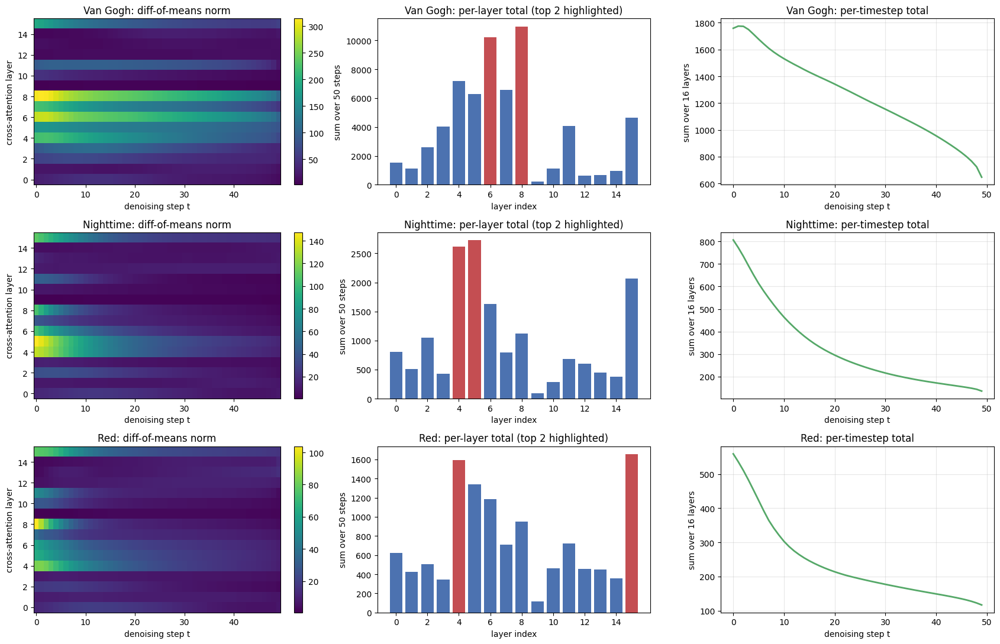


Concentration of each concept over layers
concept      top-2 layers     top-2 share  top-4 share
Van Gogh     L8, L6                33.7%        55.6%
Nighttime    L5, L4                32.9%        55.7%
Red          L15, L4               27.3%        48.5%

Seed stability of the per-layer ranking (5 seeds)
concept      mean SNR     top-2 SNR    rank agreement
Van Gogh          31.24        29.82           100%
Nighttime         20.43        16.61           100%
Red               19.15        21.19           100%


In [ ]:
# ============================================================
# 2.1  The concept map: where each concept sits in (layer x timestep)
#
# Pure plotting — no GPU work. Everything below is read off the matrices
# loaded in section 1.2, i.e. the 5-seed difference-of-means norms.
#
# Three panels per figure:
#   (a) layer x timestep heatmap of ||mean_concept - mean_control||
#   (b) per-layer totals (summed over all 50 denoising steps)
#   (c) per-timestep totals (summed over all 16 layers)
#
# Panel (b) is what the "top-2 layers" selection used everywhere later;
# panel (c) is the evidence for the claim that the layer axis carries far
# more structure than the timestep axis.
# ============================================================

CONCEPT_PANELS = [
    ("Van Gogh",  vg_matrix,    vg_perseed),
    ("Nighttime", night_matrix, night_perseed),
    ("Red",       red_matrix,   red_perseed),
]

fig, axes = plt.subplots(3, 3, figsize=(17, 11))

for row, (name, matrix, _) in enumerate(CONCEPT_PANELS):
    # (a) heatmap
    ax = axes[row, 0]
    im = ax.imshow(matrix, aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(f"{name}: diff-of-means norm")
    ax.set_xlabel("denoising step t")
    ax.set_ylabel("cross-attention layer")
    ax.set_yticks(range(0, N_LAYERS, 2))
    fig.colorbar(im, ax=ax, fraction=0.046)

    # (b) per-layer totals
    per_layer = matrix.sum(axis=1)
    ax = axes[row, 1]
    order = np.argsort(per_layer)[::-1]
    colors = ["#c44e52" if i in order[:2] else "#4c72b0"
              for i in range(N_LAYERS)]
    ax.bar(range(N_LAYERS), per_layer, color=colors)
    ax.set_title(f"{name}: per-layer total (top 2 highlighted)")
    ax.set_xlabel("layer index")
    ax.set_ylabel("sum over 50 steps")
    ax.set_xticks(range(0, N_LAYERS, 2))

    # (c) per-timestep totals
    per_step = matrix.sum(axis=0)
    ax = axes[row, 2]
    ax.plot(range(NUM_STEPS), per_step, color="#55a868", lw=2)
    ax.set_title(f"{name}: per-timestep total")
    ax.set_xlabel("denoising step t")
    ax.set_ylabel("sum over 16 layers")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_concept_maps.png", dpi=140,
            bbox_inches="tight")
plt.show()

# ---- numeric summary: how concentrated is each concept? --------------------
print("\nConcentration of each concept over layers")
print(f"{'concept':<12s} {'top-2 layers':<16s} {'top-2 share':<12s} "
      f"{'top-4 share'}")
for name, matrix, _ in CONCEPT_PANELS:
    per_layer = matrix.sum(axis=1)
    order = np.argsort(per_layer)[::-1]
    total = per_layer.sum()
    share2 = per_layer[order[:2]].sum() / total
    share4 = per_layer[order[:4]].sum() / total
    layers = ", ".join(f"L{int(i)}" for i in order[:2])
    print(f"{name:<12s} {layers:<16s} {share2:>10.1%}   {share4:>10.1%}")

# ---- seed stability: how reproducible is the localization? -----------------
# per_seed_norms is (N_SEEDS, N_LAYERS, NUM_STEPS) computed from each seed's
# own 20-pair average. A high mean/std ratio means the concept sits in the
# same place regardless of the noise sample.
print("\nSeed stability of the per-layer ranking (5 seeds)")
print(f"{'concept':<12s} {'mean SNR':<12s} {'top-2 SNR':<12s} "
      f"{'rank agreement'}")
for name, matrix, perseed in CONCEPT_PANELS:
    per_layer_seeds = perseed.sum(axis=2)                    # (N_SEEDS, N_LAYERS)
    mu = per_layer_seeds.mean(axis=0)
    sd = per_layer_seeds.std(axis=0) + 1e-8
    snr = mu / sd
    order = np.argsort(matrix.sum(axis=1))[::-1]
    top2 = order[:2]
    # fraction of seeds whose own top-2 equals the pooled top-2
    agree = np.mean([
        set(np.argsort(per_layer_seeds[s])[::-1][:2]) == set(top2)
        for s in range(per_layer_seeds.shape[0])
    ])
    print(f"{name:<12s} {snr.mean():>10.2f}   {snr[top2].mean():>10.2f}   "
          f"{agree:>12.0%}")

Steering each layer alone.

2.2  CAUSAL MAP — steering each layer alone
[Van Gogh] loading fp16 directions ...
[Van Gogh] loaded 800 tensors in 93.9s

[Van Gogh]  (192s)
  strongest CAUSAL layer  = L4 (+0.0573)
  strongest DIFF-NORM layer = L8 (+0.0299 causal effect)
  Spearman(diff-norm, causal effect) over 16 layers = +0.61  (p = 0.012)
  top-3 causal   : [4, 5, 8]
  top-3 diff-norm: [8, 6, 4]
  best time window at L4: (20, 30)
[Nighttime] loading fp16 directions ...
[Nighttime] loaded 800 tensors in 50.2s

[Nighttime]  (341s)
  strongest CAUSAL layer  = L5 (+0.1195)
  strongest DIFF-NORM layer = L5 (+0.1195 causal effect)
  Spearman(diff-norm, causal effect) over 16 layers = +0.42  (p = 0.105)
  top-3 causal   : [5, 15, 0]
  top-3 diff-norm: [5, 4, 15]
  best time window at L5: (0, 10)
[Red] loading fp16 directions ...
[Red] loaded 800 tensors in 70.6s

[Red]  (510s)
  strongest CAUSAL layer  = L4 (+0.0564)
  strongest DIFF-NORM layer = L15 (-0.0101 causal effect)
  Spearman(diff-norm, causal effect) over 16 l

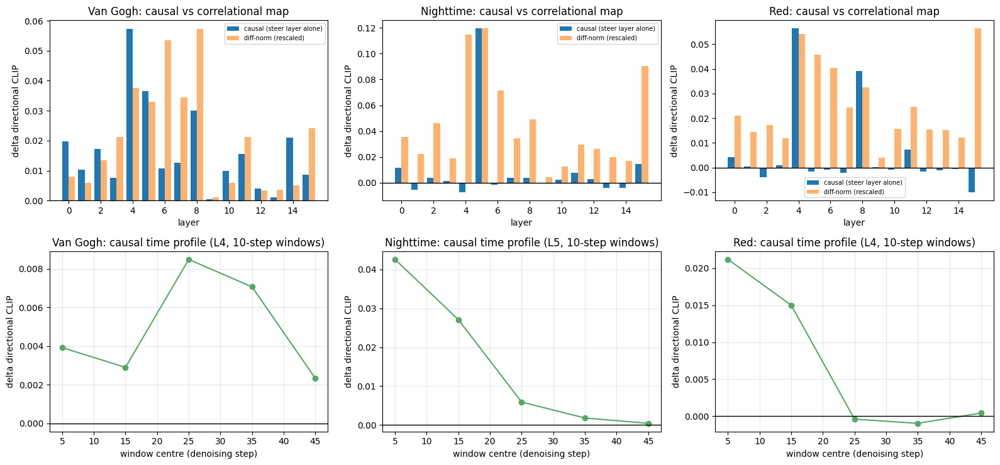


Done in 8.5 min.

Every later section selects layers from the DIFF-NORM map. Where the
two maps disagree, say so explicitly in the thesis and treat the
causal ranking as the authoritative one.


In [ ]:
# ============================================================
# 2.2  THE CAUSAL MAP
#
# The heatmap above is a CORRELATIONAL map: it shows where the two prompt
# populations differ, not where intervening changes the image. Those are
# different questions, and section 8.3 shows they give different answers -
# the greedy search picks layers the diff-norm map does not rank first.
#
# This cell builds the causal counterpart by brute force:
#   LAYER MAP : steer each of the 16 layers ALONE (alpha, t < WINDOW) and
#               record the delta directional CLIP score.
#   TIME MAP  : at each concept's strongest causal layer, steer only inside
#               a 10-step window and slide the window across the trajectory.
#
# The layer map is then rank-correlated against the diff-norm map. A low
# correlation is a methodological result in its own right: it means the
# standard difference-of-means localisation used throughout the literature
# does not predict where intervention works.
#
# Cost: ~110 generations, ~5 min on an A100.
# ============================================================

from scipy.stats import spearmanr

CMAP_PROMPT = "a photograph of a house"
CMAP_ALPHA  = 3.0
CMAP_WINDOW = 25          # layer map injects at t < 25
CMAP_SEEDS  = [0, 1]
TIME_WINDOWS = [(0, 10), (10, 20), (20, 30), (30, 40), (40, 50)]

CMAP_CONCEPTS = {
    "Van Gogh":  (vg_dirs,    vg_matrix,    vg_score),
    "Nighttime": (night_dirs, night_matrix, night_score),
    "Red":       (red_dirs,   red_matrix,   red_score),
}

print("=" * 70)
print("2.2  CAUSAL MAP — steering each layer alone")
print("=" * 70)
t0 = time.time()

causal_layer = {}    # concept -> (N_LAYERS,) mean delta
causal_time = {}     # concept -> (len(TIME_WINDOWS),) mean delta
best_causal_layer = {}


def _steer(cache, dirs, layer_idxs, lo, hi, alpha, prompt, seed):
    patch = {}
    for l_idx in layer_idxs:
        l_name = layer_names_all[l_idx]
        for t_step in range(lo, hi):
            key = (t_step, l_name, "out")
            patch[key] = (cache[key].float()
                          + alpha * dirs[(t_step, l_name)].to(DEVICE)).to(DTYPE)
    return pipeline.run_with_patch(patch, seed=seed, prompt=prompt)


for cname, (dirs, matrix, scorer) in CMAP_CONCEPTS.items():
    layer_eff = np.zeros((N_LAYERS, len(CMAP_SEEDS)), dtype=np.float32)
    cleans, bases = {}, {}
    for seed in CMAP_SEEDS:
        img, cache = pipeline.run_and_cache(CMAP_PROMPT, seed=seed)
        cleans[seed] = cache
        bases[seed] = scorer(img)

    for l_idx in range(N_LAYERS):
        for is_, seed in enumerate(CMAP_SEEDS):
            img = _steer(cleans[seed], dirs, [l_idx], 0, CMAP_WINDOW,
                         CMAP_ALPHA, CMAP_PROMPT, seed)
            layer_eff[l_idx, is_] = scorer(img) - bases[seed]
    causal_layer[cname] = layer_eff.mean(axis=1)

    best_l = int(np.argmax(causal_layer[cname]))
    best_causal_layer[cname] = best_l

    # ---- time map at the strongest causal layer ---------------------------
    time_eff = np.zeros((len(TIME_WINDOWS), len(CMAP_SEEDS)), dtype=np.float32)
    for iw, (lo, hi) in enumerate(TIME_WINDOWS):
        for is_, seed in enumerate(CMAP_SEEDS):
            img = _steer(cleans[seed], dirs, [best_l], lo, hi,
                         CMAP_ALPHA, CMAP_PROMPT, seed)
            time_eff[iw, is_] = scorer(img) - bases[seed]
    causal_time[cname] = time_eff.mean(axis=1)

    del cleans
    torch.cuda.empty_cache()

    rho, pval = spearmanr(matrix.sum(axis=1), causal_layer[cname])
    map_top = int(np.argmax(matrix.sum(axis=1)))
    print(f"\n[{cname}]  ({time.time()-t0:.0f}s)")
    print(f"  strongest CAUSAL layer  = L{best_l} "
          f"({causal_layer[cname][best_l]:+.4f})")
    print(f"  strongest DIFF-NORM layer = L{map_top} "
          f"({causal_layer[cname][map_top]:+.4f} causal effect)")
    print(f"  Spearman(diff-norm, causal effect) over {N_LAYERS} layers = "
          f"{rho:+.2f}  (p = {pval:.3f})")
    top3_causal = list(np.argsort(causal_layer[cname])[::-1][:3])
    top3_map = list(np.argsort(matrix.sum(axis=1))[::-1][:3])
    print(f"  top-3 causal   : {[int(x) for x in top3_causal]}")
    print(f"  top-3 diff-norm: {[int(x) for x in top3_map]}")
    print(f"  best time window at L{best_l}: "
          f"{TIME_WINDOWS[int(np.argmax(causal_time[cname]))]}")

# ---- plots -----------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for col, cname in enumerate(CMAP_CONCEPTS):
    matrix = CMAP_CONCEPTS[cname][1]
    ax = axes[0, col]
    norm = matrix.sum(axis=1)
    norm = norm / (norm.max() + 1e-9) * max(causal_layer[cname].max(), 1e-9)
    ax.bar(np.arange(N_LAYERS) - 0.2, causal_layer[cname], 0.4,
           label="causal (steer layer alone)")
    ax.bar(np.arange(N_LAYERS) + 0.2, norm, 0.4, alpha=0.6,
           label="diff-norm (rescaled)")
    ax.axhline(0, color="k", lw=1)
    ax.set_title(f"{cname}: causal vs correlational map")
    ax.set_xlabel("layer")
    ax.set_ylabel("delta directional CLIP")
    ax.set_xticks(range(0, N_LAYERS, 2))
    ax.legend(fontsize=7)

    ax = axes[1, col]
    centres = [(lo + hi) / 2 for lo, hi in TIME_WINDOWS]
    ax.plot(centres, causal_time[cname], "o-", color="#55a868")
    ax.axhline(0, color="k", lw=1)
    ax.set_title(f"{cname}: causal time profile "
                 f"(L{best_causal_layer[cname]}, 10-step windows)")
    ax.set_xlabel("window centre (denoising step)")
    ax.set_ylabel("delta directional CLIP")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_causal_map.png", dpi=140, bbox_inches="tight")
plt.show()

np.save(f"{DRIVE_DIR}/causal_maps.npy",
        {"layer": causal_layer, "time": causal_time,
         "best_layer": best_causal_layer}, allow_pickle=True)
print(f"\nDone in {(time.time()-t0)/60:.1f} min.")
print("\nEvery later section selects layers from the DIFF-NORM map. Where the")
print("two maps disagree, say so explicitly in the thesis and treat the")
print("causal ranking as the authoritative one.")

Negative controls: shuffled, Gaussian and other-concept directions.

2.3  NEGATIVE CONTROLS — is it the direction or just the perturbation?

[Van Gogh]  layers [8, 6]  cross-direction from Nighttime  (61s)
  mode           a=2.0     a=3.0     a=5.0
  real         +0.0835   +0.1288   +0.0884
  shuffled     +0.0085   +0.0274   +0.0296
  gaussian     +0.0125   +0.0246   +0.0238
  cross        +0.0598   +0.0491   +0.0442
  real peak +0.1288   |shuffled/gaussian| peak 0.0296   ratio 4.4x

[Nighttime]  layers [5, 4]  cross-direction from Red  (121s)
  mode           a=2.0     a=3.0     a=5.0
  real         +0.1448   +0.1127   +0.0421
  shuffled     +0.0081   +0.0084   +0.0085
  gaussian     +0.0013   +0.0050   +0.0176
  cross        +0.0152   +0.0292   +0.0671
  real peak +0.1448   |shuffled/gaussian| peak 0.0176   ratio 8.2x

[Red]  layers [15, 4]  cross-direction from Van Gogh  (181s)
  mode           a=2.0     a=3.0     a=5.0
  real         +0.0539   +0.0515   +0.0488
  shuffled     +0.0023   -0.0050   +0.0078
  gaussian     -0.0004   -0.0036   +0.0129
  c

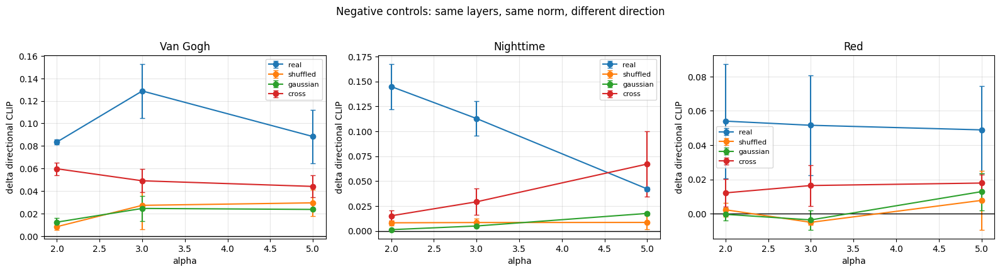

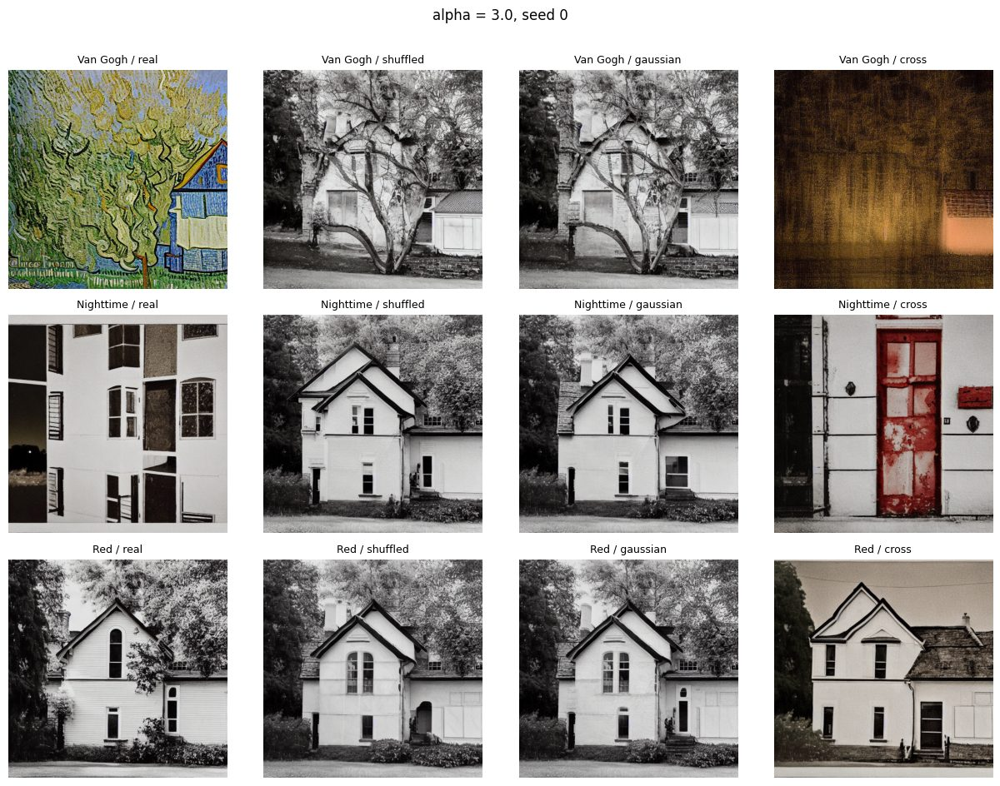


Done in 3.1 min.


In [ ]:
# ============================================================
# 2.3  NEGATIVE CONTROLS
#
# Every steering result in this notebook is compatible with a much weaker
# claim: "perturbing activations at these layers changes the image". This
# cell rules that out by holding the intervention fixed and swapping only
# the DIRECTION, at matched magnitude:
#
#   real      the concept direction                      (the experiment)
#   shuffled  the same tensor with its entries randomly permuted - identical
#             norm and identical value distribution, no structure
#   gaussian  white noise rescaled to the same per-cell norm
#   cross     ANOTHER concept's direction injected at THIS concept's layers -
#             separates "the layers do it" from "the direction does it"
#
# If real >> shuffled ~ gaussian, the effect is carried by the direction.
# If cross also scores high, the layers matter more than the direction and
# the concept-specific reading of the thesis weakens.
#
# The shuffled control is the strict one: matching the norm alone is easy,
# matching the whole value distribution is not.
#
# Cost: ~78 generations, ~4 min on an A100.
# ============================================================

CTRL_PROMPT = "a photograph of a house"
CTRL_ALPHAS = [2.0, 3.0, 5.0]
CTRL_SEEDS  = [0, 1]
CTRL_RNG    = torch.Generator(device="cpu").manual_seed(1234)

CTRL_CONCEPTS = {
    "Van Gogh":  dict(dirs=vg_dirs,    layers=vg_top_layers,    scorer=vg_score),
    "Nighttime": dict(dirs=night_dirs, layers=night_top_layers, scorer=night_score),
    "Red":       dict(dirs=red_dirs,   layers=red_top_layers,   scorer=red_score),
}
CTRL_CROSS = {"Van Gogh": "Nighttime", "Nighttime": "Red", "Red": "Van Gogh"}
CTRL_MODES = ["real", "shuffled", "gaussian", "cross"]


def control_vector(mode, d_real, d_cross):
    """Return the tensor to inject, matched in norm to `d_real`."""
    if mode == "real":
        return d_real
    if mode == "shuffled":
        flat = d_real.reshape(-1)
        perm = torch.randperm(flat.numel(), generator=CTRL_RNG).to(flat.device)
        return flat[perm].reshape(d_real.shape)
    if mode == "gaussian":
        g = torch.randn(d_real.shape, generator=CTRL_RNG,
                        dtype=torch.float32).to(d_real.device)
        return (g / (g.norm() + 1e-8) * d_real.float().norm()).to(d_real.dtype)
    if mode == "cross":
        return (d_cross.float() / (d_cross.float().norm() + 1e-8)
                * d_real.float().norm()).to(d_real.dtype)
    raise ValueError(mode)


print("=" * 70)
print("2.3  NEGATIVE CONTROLS — is it the direction or just the perturbation?")
print("=" * 70)
t0 = time.time()

ctrl_res = {c: np.zeros((len(CTRL_MODES), len(CTRL_ALPHAS), len(CTRL_SEEDS)),
                        dtype=np.float32) for c in CTRL_CONCEPTS}
ctrl_imgs = {}

for cname, cfg in CTRL_CONCEPTS.items():
    cross_dirs = CTRL_CONCEPTS[CTRL_CROSS[cname]]["dirs"]
    cells = [(t, layer_names_all[l]) for l in cfg["layers"]
             for t in range(NUM_STEPS)]

    # Build every control vector ONCE per concept. Rebuilding them inside the
    # alpha/seed loops would call randperm on ~1.5M elements thousands of
    # times; the shuffled and gaussian tensors do not depend on alpha or seed.
    vecs = {"real": {}, "shuffled": {}, "gaussian": {}, "cross": {}}
    for (t_step, l_name) in cells:
        d_real = cfg["dirs"][(t_step, l_name)]
        d_cross = cross_dirs[(t_step, l_name)]
        for mode in CTRL_MODES:
            vecs[mode][(t_step, l_name)] = control_vector(mode, d_real, d_cross)

    for is_, seed in enumerate(CTRL_SEEDS):
        clean_img, cache = pipeline.run_and_cache(CTRL_PROMPT, seed=seed)
        base = cfg["scorer"](clean_img)
        for im, mode in enumerate(CTRL_MODES):
            for ia, alpha in enumerate(CTRL_ALPHAS):
                patch = {}
                for (t_step, l_name) in cells:
                    key = (t_step, l_name, "out")
                    patch[key] = (cache[key].float()
                                  + alpha * vecs[mode][(t_step, l_name)]
                                  .to(DEVICE)).to(DTYPE)
                img = pipeline.run_with_patch(patch, seed=seed,
                                              prompt=CTRL_PROMPT)
                ctrl_res[cname][im, ia, is_] = cfg["scorer"](img) - base
                if seed == CTRL_SEEDS[0] and alpha == CTRL_ALPHAS[1]:
                    ctrl_imgs[(cname, mode)] = img
                del patch
        del cache
        torch.cuda.empty_cache()
    del vecs
    gc.collect()
    m = ctrl_res[cname].mean(axis=2)
    print(f"\n[{cname}]  layers {cfg['layers']}  "
          f"cross-direction from {CTRL_CROSS[cname]}  ({time.time()-t0:.0f}s)")
    print(f"  {'mode':<10s}" + "".join(f"{'a=' + str(a):>10s}"
                                       for a in CTRL_ALPHAS))
    for im, mode in enumerate(CTRL_MODES):
        print(f"  {mode:<10s}" + "".join(f"{m[im, ia]:>+10.4f}"
                                         for ia in range(len(CTRL_ALPHAS))))
    real_peak = float(np.max(m[0]))
    ctrl_peak = float(np.max(np.abs(m[1:3])))
    print(f"  real peak {real_peak:+.4f}   |shuffled/gaussian| peak "
          f"{ctrl_peak:.4f}   ratio {real_peak / (ctrl_peak + 1e-9):.1f}x")

np.save(f"{DRIVE_DIR}/negative_controls.npy", ctrl_res, allow_pickle=True)

# ---- plots -----------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, cname in zip(axes, CTRL_CONCEPTS):
    m = ctrl_res[cname].mean(axis=2)
    sd = ctrl_res[cname].std(axis=2)
    for im, mode in enumerate(CTRL_MODES):
        ax.errorbar(CTRL_ALPHAS, m[im], yerr=sd[im], fmt="o-", capsize=3,
                    label=mode)
    ax.axhline(0, color="k", lw=1)
    ax.set_title(cname)
    ax.set_xlabel("alpha")
    ax.set_ylabel("delta directional CLIP")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.suptitle("Negative controls: same layers, same norm, different direction",
             y=1.02)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_negative_controls.png", dpi=140,
            bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(len(CTRL_CONCEPTS), len(CTRL_MODES),
                         figsize=(3.1 * len(CTRL_MODES),
                                  3.1 * len(CTRL_CONCEPTS)))
for r, cname in enumerate(CTRL_CONCEPTS):
    for c, mode in enumerate(CTRL_MODES):
        ax = axes[r, c]
        ax.imshow(ctrl_imgs[(cname, mode)])
        ax.set_title(f"{cname} / {mode}", fontsize=9)
        ax.axis("off")
plt.suptitle(f"alpha = {CTRL_ALPHAS[1]}, seed {CTRL_SEEDS[0]}", y=1.01)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_negative_controls_images.png", dpi=130,
            bbox_inches="tight")
plt.show()
print(f"\nDone in {(time.time()-t0)/60:.1f} min.")

[Van Gogh] done (70s)
[Nighttime] done (139s)
[Red] done (207s)

Delta directional CLIP at alpha = 3.0  (real should be high, the other three near zero)

seed 0   ->  /content/drive/MyDrive/thesis_public_run/controls_rerun/controls_seed0.jpg
  Van Gogh   real=+0.153  shuffled=+0.049  gaussian=+0.036  cross=+0.059
  Nighttime  real=+0.095  shuffled=+0.004  gaussian=+0.005  cross=+0.043
  Red        real=+0.022  shuffled=-0.006  gaussian=+0.002  cross=+0.004

seed 1   ->  /content/drive/MyDrive/thesis_public_run/controls_rerun/controls_seed1.jpg
  Van Gogh   real=+0.105  shuffled=+0.006  gaussian=+0.013  cross=+0.039
  Nighttime  real=+0.130  shuffled=+0.013  gaussian=+0.005  cross=+0.016
  Red        real=+0.081  shuffled=-0.004  gaussian=-0.009  cross=+0.028

seed 2   ->  /content/drive/MyDrive/thesis_public_run/controls_rerun/controls_seed2.jpg
  Van Gogh   real=+0.106  shuffled=+0.028  gaussian=+0.021  cross=+0.009
  Nighttime  real=+0.144  shuffled=+0.006  gaussian=+0.006  cross=-0.

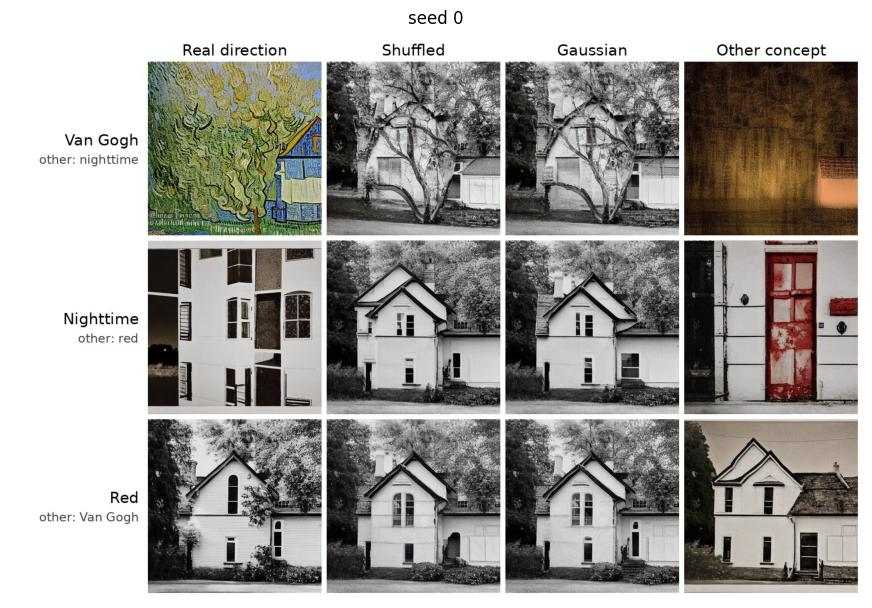

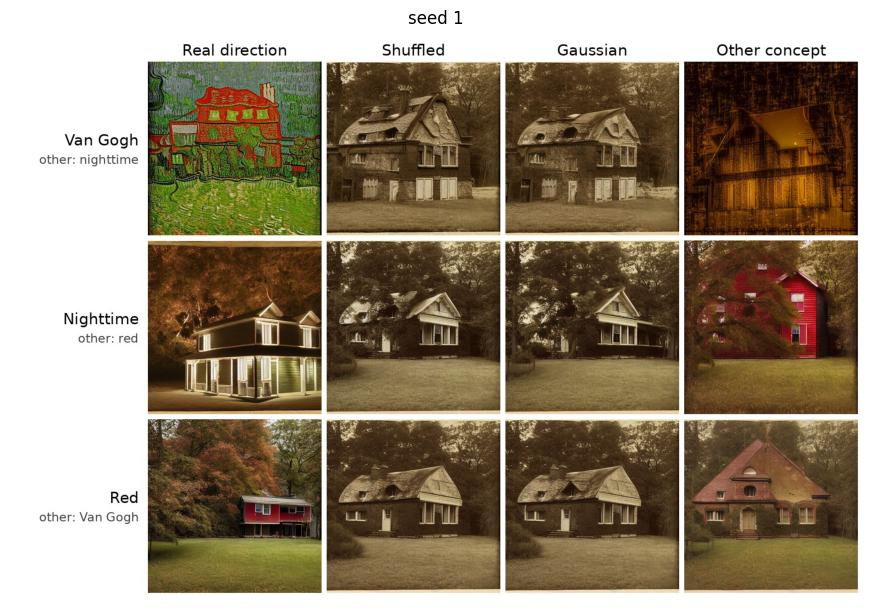

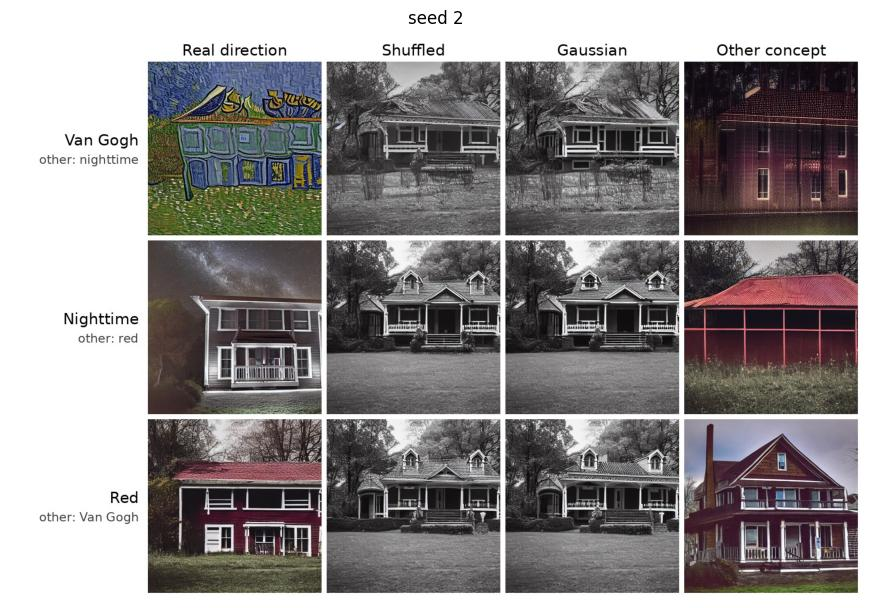

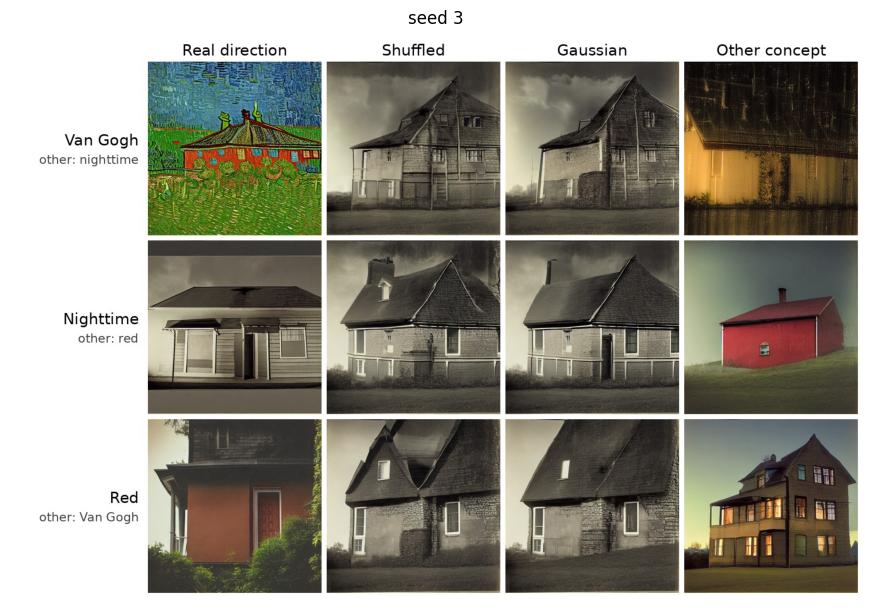

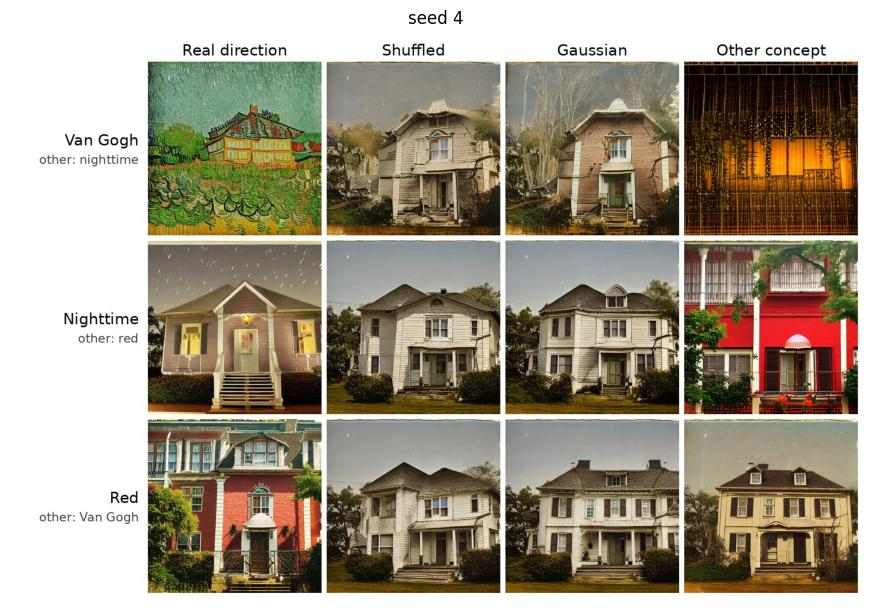

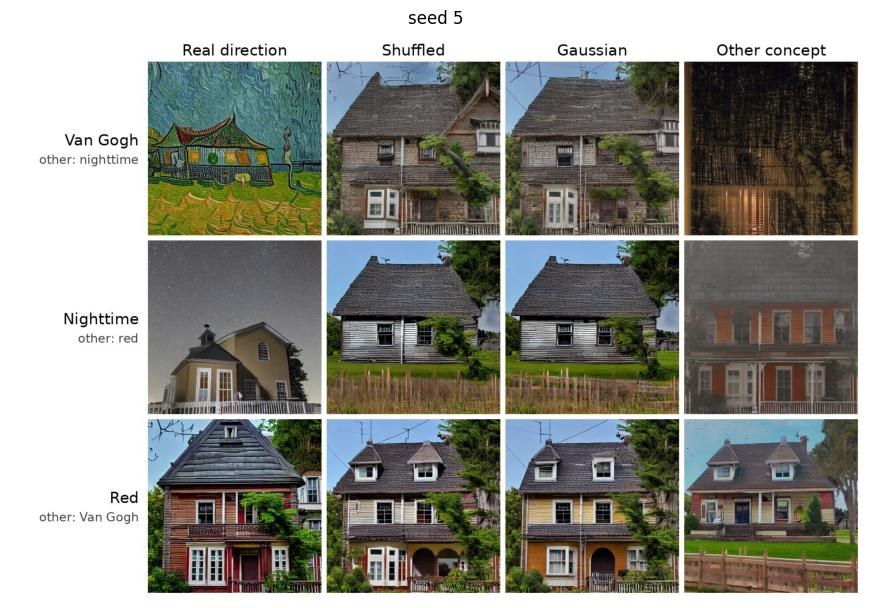


Done in 3.5 min.


In [ ]:
# ============================================================
# 2.3b  NEGATIVE CONTROLS - EXAMPLE IMAGES, SIX SEEDS
#
# Generates only the example images of the negative controls (cell 2.3) with
# more seeds, so that a clear example can be chosen for the thesis figure
# (seed 4). The numbers of cell 2.3 (negative_controls.npy) are not touched.
#
# Same prompt, same layers, same norm matching, same alpha (3.0) as cell 2.3.
# For every seed it saves one ready-made grid (3 concepts x 4 directions)
# with clean labels:
#     <DRIVE_DIR>/controls_rerun/controls_seed<k>.jpg
# and prints the score change of every image, so you can pick the seed where
# the real direction visibly produces each concept.
#
# Needs (run first): cell 2 (pipeline), cell 4 (Drive/config),
#                    cell 8 (directions + top layers), cell 10 (CLIP scorers).
# Cost: 6 seeds x 3 concepts x 5 generations = 90 generations, ~5 min on A100.
# ============================================================

import os, gc, time
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont
from matplotlib import font_manager

RERUN_PROMPT = "a photograph of a house"       # same as CTRL_PROMPT
RERUN_ALPHA  = 3.0                              # same as the figure
RERUN_SEEDS  = [0, 1, 2, 3, 4, 5]
OUT_DIR      = f"{DRIVE_DIR}/controls_rerun"
os.makedirs(OUT_DIR, exist_ok=True)

RERUN_CONCEPTS = {
    "Van Gogh":  dict(dirs=vg_dirs,    layers=vg_top_layers,    scorer=vg_score),
    "Nighttime": dict(dirs=night_dirs, layers=night_top_layers, scorer=night_score),
    "Red":       dict(dirs=red_dirs,   layers=red_top_layers,   scorer=red_score),
}
RERUN_CROSS = {"Van Gogh": "Nighttime", "Nighttime": "Red", "Red": "Van Gogh"}
RERUN_MODES = ["real", "shuffled", "gaussian", "cross"]
RERUN_RNG   = torch.Generator(device="cpu").manual_seed(1234)


def _control_vector(mode, d_real, d_cross):
    """Same definition as control_vector() in cell 2.3."""
    if mode == "real":
        return d_real
    if mode == "shuffled":
        flat = d_real.reshape(-1)
        perm = torch.randperm(flat.numel(), generator=RERUN_RNG).to(flat.device)
        return flat[perm].reshape(d_real.shape)
    if mode == "gaussian":
        g = torch.randn(d_real.shape, generator=RERUN_RNG,
                        dtype=torch.float32).to(d_real.device)
        return (g / (g.norm() + 1e-8) * d_real.float().norm()).to(d_real.dtype)
    if mode == "cross":
        return (d_cross.float() / (d_cross.float().norm() + 1e-8)
                * d_real.float().norm()).to(d_real.dtype)
    raise ValueError(mode)


# images[(seed, concept, mode)] -> PIL image ; scores[...] -> delta score
images, scores = {}, {}
t0 = time.time()

for cname, cfg in RERUN_CONCEPTS.items():
    cross_dirs = RERUN_CONCEPTS[RERUN_CROSS[cname]]["dirs"]
    cells = [(t, layer_names_all[l]) for l in cfg["layers"]
             for t in range(NUM_STEPS)]
    vecs = {m: {} for m in RERUN_MODES}
    for (t_step, l_name) in cells:
        d_real = cfg["dirs"][(t_step, l_name)]
        d_cross = cross_dirs[(t_step, l_name)]
        for mode in RERUN_MODES:
            vecs[mode][(t_step, l_name)] = _control_vector(mode, d_real, d_cross)

    for seed in RERUN_SEEDS:
        clean_img, cache = pipeline.run_and_cache(RERUN_PROMPT, seed=seed)
        base = cfg["scorer"](clean_img)
        for mode in RERUN_MODES:
            patch = {}
            for (t_step, l_name) in cells:
                key = (t_step, l_name, "out")
                patch[key] = (cache[key].float()
                              + RERUN_ALPHA * vecs[mode][(t_step, l_name)]
                              .to(DEVICE)).to(DTYPE)
            img = pipeline.run_with_patch(patch, seed=seed, prompt=RERUN_PROMPT)
            images[(seed, cname, mode)] = img
            scores[(seed, cname, mode)] = cfg["scorer"](img) - base
            del patch
        del cache
        torch.cuda.empty_cache()
    del vecs
    gc.collect()
    print(f"[{cname}] done ({time.time() - t0:.0f}s)")


# ---- one labelled grid per seed --------------------------------------------
FONT = font_manager.findfont("DejaVu Sans")
COL_HDR = ["Real direction", "Shuffled", "Gaussian", "Other concept"]
ROW_SUB = {"Van Gogh": "other: nighttime", "Nighttime": "other: red",
           "Red": "other: Van Gogh"}


def make_grid(seed, size=340, gap=10, left=270, top=60, fs=30):
    rows = list(RERUN_CONCEPTS)
    W = left + 4 * size + 3 * gap + 10
    H = top + len(rows) * size + (len(rows) - 1) * gap + 10
    can = Image.new("RGB", (W, H), "white")
    d = ImageDraw.Draw(can)
    f = ImageFont.truetype(FONT, fs)
    fsub = ImageFont.truetype(FONT, int(fs * 0.8))
    for j, h in enumerate(COL_HDR):
        d.text((left + j * (size + gap) + size / 2, top - 12), h,
               font=f, fill="black", anchor="ms")
    for i, cname in enumerate(rows):
        y = top + i * (size + gap) + size / 2
        d.text((left - 18, y - 6), cname, font=f, fill="black", anchor="rs")
        d.text((left - 18, y + 30), ROW_SUB[cname], font=fsub,
               fill="#444", anchor="rs")
        for j, mode in enumerate(RERUN_MODES):
            tile = images[(seed, cname, mode)].resize((size, size), Image.LANCZOS)
            can.paste(tile, (left + j * (size + gap), top + i * (size + gap)))
    return can


for seed in RERUN_SEEDS:
    path = f"{OUT_DIR}/controls_seed{seed}.jpg"
    make_grid(seed).save(path, quality=90)

# ---- score table: pick the seed where the REAL column is clearly highest ----
print(f"\nDelta directional CLIP at alpha = {RERUN_ALPHA}  "
      f"(real should be high, the other three near zero)")
for seed in RERUN_SEEDS:
    print(f"\nseed {seed}   ->  {OUT_DIR}/controls_seed{seed}.jpg")
    for cname in RERUN_CONCEPTS:
        row = "  ".join(f"{m}={scores[(seed, cname, m)]:+.3f}"
                        for m in RERUN_MODES)
        print(f"  {cname:<10s} {row}")

# show all grids in the notebook for a quick visual choice
import matplotlib.pyplot as plt
for seed in RERUN_SEEDS:
    plt.figure(figsize=(11, 8))
    plt.imshow(Image.open(f"{OUT_DIR}/controls_seed{seed}.jpg"))
    plt.title(f"seed {seed}")
    plt.axis("off")
    plt.show()

print(f"\nDone in {(time.time() - t0) / 60:.1f} min.")

## 3. Steering in windows of steps (thesis 6.3)

In [ ]:
# ============================================================
# NEW EXPERIMENT — 2 LAYERS PER CONCEPT × EARLY-STEP WINDOWS × 3 SEEDS
#
# Motivation: the existing sweep used top-K=20 cells scattered across many
# layers, and a single steering seed. Here we constrain steering to ONLY
# the 2 strongest layers per concept (selected by total diff-of-means norm
# summed across all 50 timesteps), so we can see how concentrated the
# effect can be when very few layers are touched.
#
# Sweep dimensions:
#   WINDOWS    : MAX_STEP in [5, 10, 15, 20, 25, 50]   (50 = full baseline)
#   ALPHAS     : [0.0, 1.0, 2.0, 3.0, 5.0, 8.0]        (matches cell 1)
#   SEEDS_STEER: [0, 1, 2]                              (3 images per cell)
#   LAYERS     : the top 2 layers of each concept
#
# Output per concept:
#   - results array of shape (windows, alphas, seeds) holding delta CLIP
#   - all generated PIL images, indexed by (window, alpha, seed)
#   - .npy file saved to Drive for later analysis
# ============================================================

# --- Rank layers per concept by summed diff-of-means norm ---
# Each diff matrix is (N_LAYERS, NUM_STEPS); summing along time gives a
# per-layer "total concept presence" score.
def top_layers(matrix, k=2):
    """Return the layer indices with the highest summed diff-norm."""
    per_layer = matrix.sum(axis=1)                       # (N_LAYERS,)
    order = np.argsort(per_layer)[::-1]                  # descending
    return [int(i) for i in order[:k]], per_layer


vg_top_layers,    vg_layer_scores    = top_layers(vg_matrix,    k=2)
night_top_layers, night_layer_scores = top_layers(night_matrix, k=2)
red_top_layers,   red_layer_scores   = top_layers(red_matrix,   k=2)

print("Top 2 layers per concept (by summed diff-norm over 50 steps):")
for name, ids, scores in [("Van Gogh",  vg_top_layers,    vg_layer_scores),
                          ("Nighttime", night_top_layers, night_layer_scores),
                          ("Red",       red_top_layers,   red_layer_scores)]:
    ranked = " | ".join(f"L{l} (sum={scores[l]:.2f})" for l in ids)
    print(f"  {name:<10s}: {ranked}")

# --- Sweep config ---
WINDOWS_2L  = [5, 10, 15, 20, 25, 50]    # MAX_STEP values (50 = full baseline)
ALPHAS_2L   = [0.0, 1.0, 2.0, 3.0, 5.0, 8.0]
SEEDS_STEER = [0, 1, 2]                  # 3 seeds per (window, alpha)


def run_2layer_steering(concept_name, save_prefix, top_layer_idxs,
                        concept_dirs, steering_prompt, scorer,
                        windows=WINDOWS_2L, alphas=ALPHAS_2L,
                        seeds=SEEDS_STEER):
    """2-layer / multi-seed early-step steering.

    For each seed: cache the clean image once, then for each (MAX_STEP, alpha)
    inject (clean_act + alpha * direction) at every cell whose
        layer_idx in `top_layer_idxs`  AND  t_step < MAX_STEP.

    Returns
    -------
    results : np.ndarray of shape (len(windows), len(alphas), len(seeds))
              holding delta directional CLIP score (score - baseline_seed).
    images  : nested dict images[(ms, alpha, seed)] -> PIL.Image
    baselines : {seed: baseline_score}
    """
    print(f"\n{'='*70}\n[{concept_name}] 2-layer / 3-seed early-step steering")
    print(f"  steering_prompt = '{steering_prompt}'")
    print(f"  layers          = {top_layer_idxs}")
    print(f"  windows         = {windows}")
    print(f"  alphas          = {alphas}")
    print(f"  seeds           = {seeds}\n{'='*70}")

    layer_name_set = {layer_names_all[l] for l in top_layer_idxs}

    results = np.zeros((len(windows), len(alphas), len(seeds)), dtype=np.float32)
    images  = {}
    baselines = {}

    total = len(windows) * len(alphas) * len(seeds)
    done = 0
    t0 = time.time()

    for s_idx, seed in enumerate(seeds):
        # Clean run + per-seed baseline + cache
        clean_img, clean_cache = pipeline.run_and_cache(steering_prompt, seed=seed)
        baseline = scorer(clean_img)
        baselines[seed] = baseline
        print(f"  seed {seed} clean baseline = {baseline:+.4f}")

        for w_idx, max_step in enumerate(windows):
            for a_idx, alpha in enumerate(alphas):
                if alpha == 0.0:
                    img = clean_img
                else:
                    patch = {}
                    for t_step in range(max_step):
                        for l_name in layer_name_set:
                            key = (t_step, l_name, "out")
                            if key not in clean_cache:
                                continue
                            clean_act = clean_cache[key].float()
                            dir_act = concept_dirs[(t_step, l_name)].to(DEVICE)
                            patch[key] = (clean_act + alpha * dir_act).to(DTYPE)
                    if patch:
                        img = pipeline.run_with_patch(patch, seed=seed,
                                                     prompt=steering_prompt)
                    else:
                        img = clean_img
                score = scorer(img) - baseline
                results[w_idx, a_idx, s_idx] = score
                images[(max_step, alpha, seed)] = img
                done += 1
                print(f"  [{done:3d}/{total}] seed={seed} max_step={max_step:>3d} "
                      f"alpha={alpha:>4.1f}  delta={score:+.4f}  "
                      f"({time.time()-t0:.1f}s)")

        # Free the cache so we don't accumulate across seeds
        del clean_cache
        torch.cuda.empty_cache()

    np.save(f"{DRIVE_DIR}/{save_prefix}_2layer_3seed_results.npy",
            results)
    np.save(f"{DRIVE_DIR}/{save_prefix}_2layer_3seed_baselines.npy",
            baselines, allow_pickle=True)
    print(f"\n  Saved: {save_prefix}_2layer_3seed_results.npy "
          f"(shape {results.shape}), baselines.npy")
    print(f"  Total time: {(time.time()-t0)/60:.1f} min")
    return results, images, baselines

Top 2 layers per concept (by summed diff-norm over 50 steps):
  Van Gogh  : L8 (sum=10960.69) | L6 (sum=10231.09)
  Nighttime : L5 (sum=2725.16) | L4 (sum=2621.75)
  Red       : L15 (sum=1654.83) | L4 (sum=1592.53)



[Van Gogh] 2-layer / 3-seed early-step steering
  steering_prompt = 'a photograph of a man'
  layers          = [8, 6]
  windows         = [5, 10, 15, 20, 25, 50]
  alphas          = [0.0, 1.0, 2.0, 3.0, 5.0, 8.0]
  seeds           = [0, 1, 2]
  seed 0 clean baseline = -0.0126
  [  1/108] seed=0 max_step=  5 alpha= 0.0  delta=+0.0000  (2.3s)
  [  2/108] seed=0 max_step=  5 alpha= 1.0  delta=+0.0099  (4.5s)
  [  3/108] seed=0 max_step=  5 alpha= 2.0  delta=+0.0245  (6.7s)
  [  4/108] seed=0 max_step=  5 alpha= 3.0  delta=+0.0032  (8.9s)
  [  5/108] seed=0 max_step=  5 alpha= 5.0  delta=+0.0157  (11.1s)
  [  6/108] seed=0 max_step=  5 alpha= 8.0  delta=-0.0349  (13.2s)
  [  7/108] seed=0 max_step= 10 alpha= 0.0  delta=+0.0000  (13.3s)
  [  8/108] seed=0 max_step= 10 alpha= 1.0  delta=+0.0302  (15.5s)
  [  9/108] seed=0 max_step= 10 alpha= 2.0  delta=+0.0349  (17.7s)
  [ 10/108] seed=0 max_step= 10 alpha= 3.0  delta=+0.0131  (19.8s)
  [ 11/108] seed=0 max_step= 10 alpha= 5.0  delta=+0.02

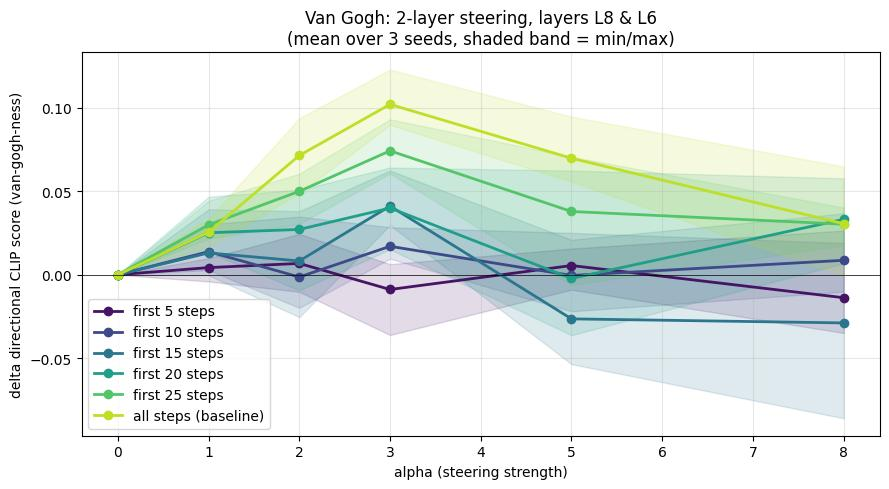

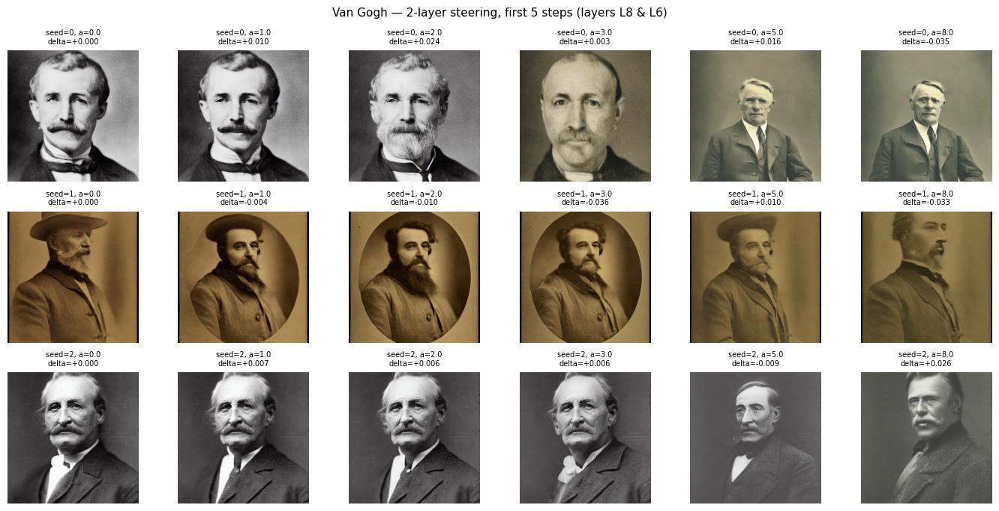

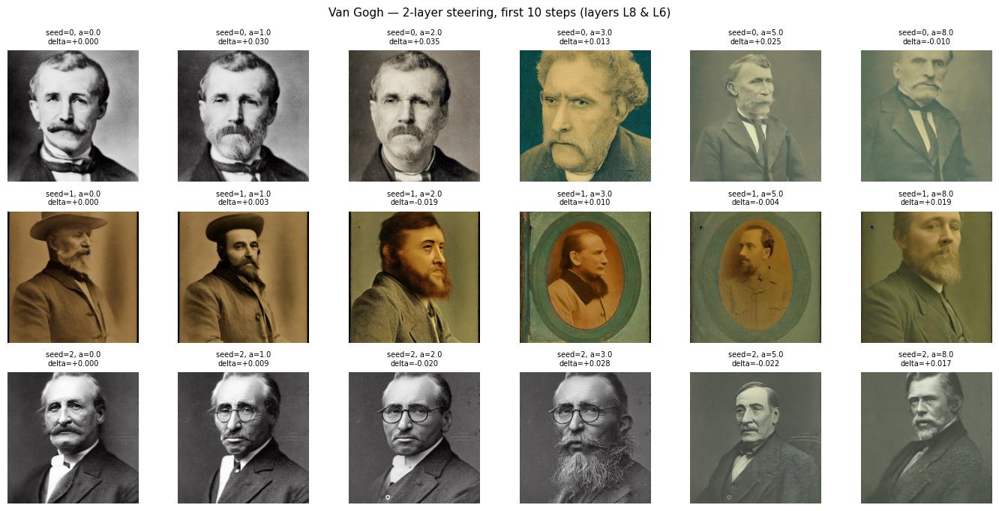

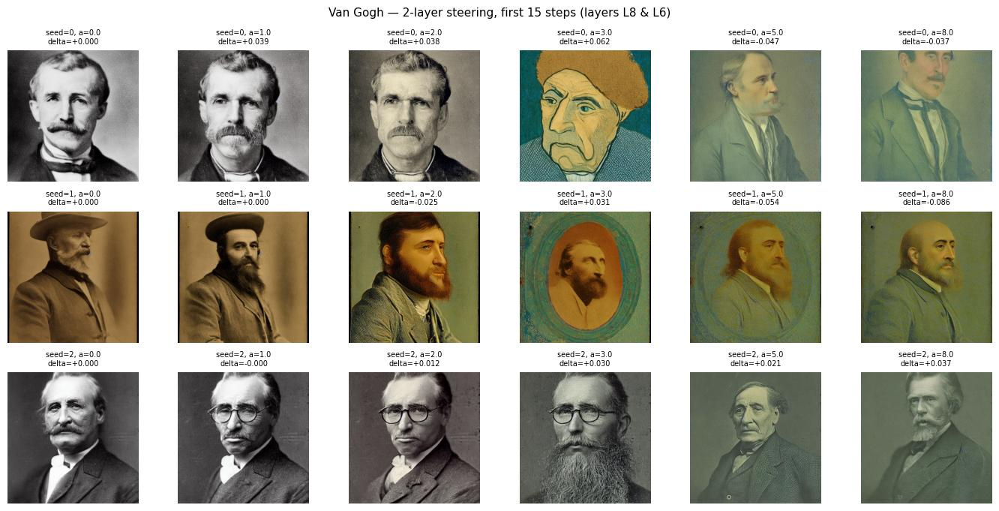

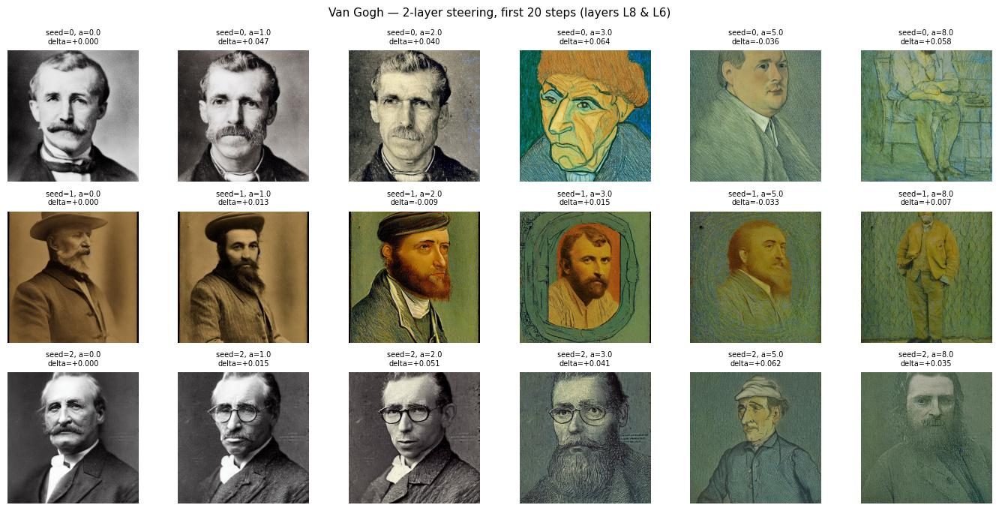

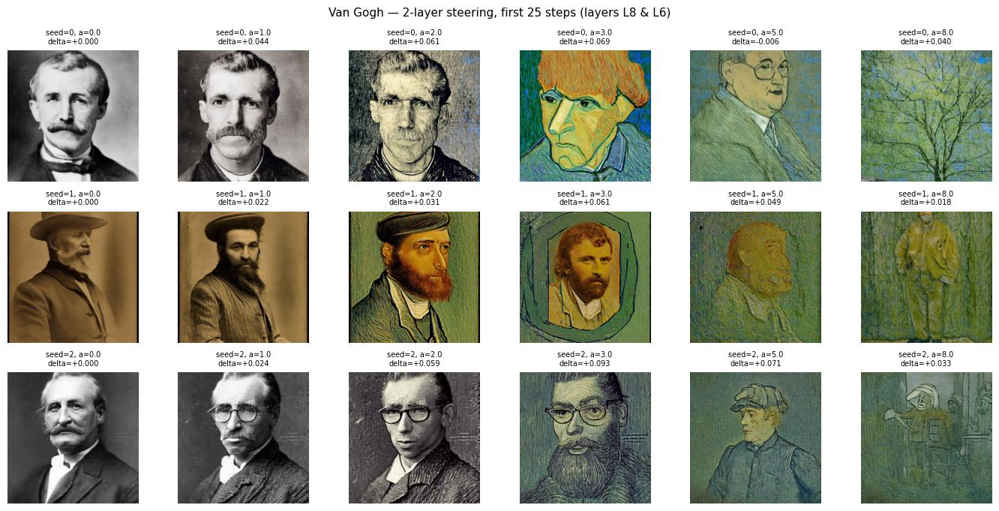

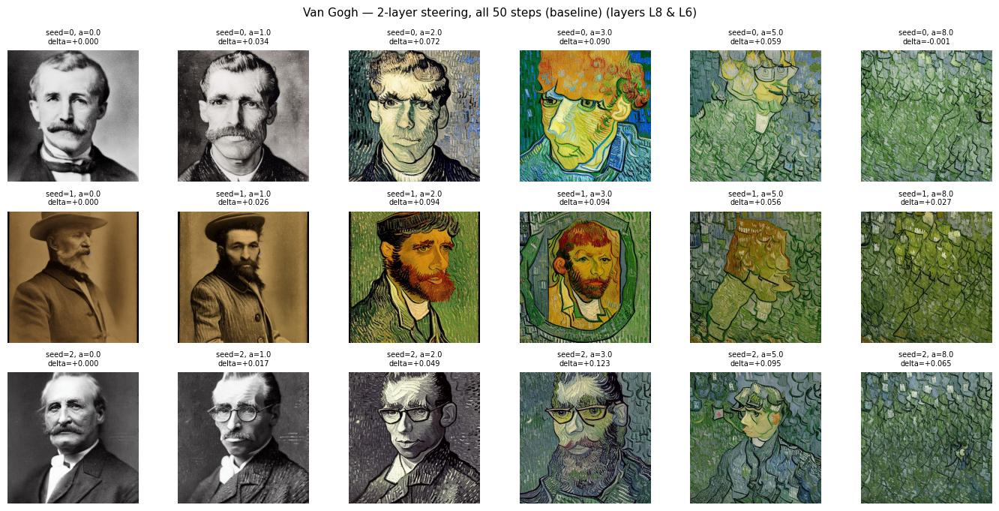

Saved: vg_2layer_3seed_curves.png + 6 per-window grids


In [ ]:
# ============================================================
# 2-layer / 3-seed early-step sweep — VAN GOGH
# ============================================================
vg_2l_results, vg_2l_images, vg_2l_baselines = run_2layer_steering(
    concept_name    = "Van Gogh",
    save_prefix     = "vg",
    top_layer_idxs  = vg_top_layers,
    concept_dirs    = vg_dirs,
    steering_prompt = "a photograph of a man",
    scorer          = vg_score,
)

# --- Figure 1: delta vs alpha curves (mean + min/max band over 3 seeds) ---
fig, ax = plt.subplots(figsize=(9, 5))
cmap = plt.cm.viridis(np.linspace(0.05, 0.9, len(WINDOWS_2L)))
for c, (w_idx, ms) in zip(cmap, list(enumerate(WINDOWS_2L))):
    per_alpha = vg_2l_results[w_idx]           # (alphas, seeds)
    mean_y    = per_alpha.mean(axis=1)
    lo, hi    = per_alpha.min(axis=1), per_alpha.max(axis=1)
    label = f"first {ms} steps" if ms < NUM_STEPS else "all steps (baseline)"
    ax.plot(ALPHAS_2L, mean_y, "o-", color=c, linewidth=2, label=label)
    ax.fill_between(ALPHAS_2L, lo, hi, color=c, alpha=0.15)
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlabel("alpha (steering strength)")
ax.set_ylabel("delta directional CLIP score (van-gogh-ness)")
ax.set_title(f"Van Gogh: 2-layer steering, layers L{vg_top_layers[0]} & L{vg_top_layers[1]}\n"
             f"(mean over 3 seeds, shaded band = min/max)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/vg_2layer_3seed_curves.png", dpi=120)
plt.show()

# --- Figure 2: per-window image grids (rows = seeds, cols = alphas) ---
# One figure per window so the grid stays readable.
for ms in WINDOWS_2L:
    fig, axes = plt.subplots(len(SEEDS_STEER), len(ALPHAS_2L),
                             figsize=(2.3 * len(ALPHAS_2L),
                                      2.3 * len(SEEDS_STEER)))
    if len(SEEDS_STEER) == 1:
        axes = np.array([axes])
    w_idx = WINDOWS_2L.index(ms)
    for s_idx, seed in enumerate(SEEDS_STEER):
        for a_idx, a in enumerate(ALPHAS_2L):
            ax = axes[s_idx, a_idx]
            ax.imshow(vg_2l_images[(ms, a, seed)])
            d = vg_2l_results[w_idx, a_idx, s_idx]
            ax.set_title(f"seed={seed}, a={a:.1f}\ndelta={d:+.3f}", fontsize=7)
            ax.axis("off")
    label = f"first {ms} steps" if ms < NUM_STEPS else "all 50 steps (baseline)"
    plt.suptitle(f"Van Gogh — 2-layer steering, {label} "
                 f"(layers L{vg_top_layers[0]} & L{vg_top_layers[1]})",
                 fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/vg_2layer_3seed_grid_ms{ms}.png", dpi=120)
    plt.show()

print(f"Saved: vg_2layer_3seed_curves.png + 6 per-window grids")


[Nighttime] 2-layer / 3-seed early-step steering
  steering_prompt = 'a photograph of a city street during the day'
  layers          = [5, 4]
  windows         = [5, 10, 15, 20, 25, 50]
  alphas          = [0.0, 1.0, 2.0, 3.0, 5.0, 8.0]
  seeds           = [0, 1, 2]
  seed 0 clean baseline = -0.0861
  [  1/108] seed=0 max_step=  5 alpha= 0.0  delta=+0.0000  (2.3s)
  [  2/108] seed=0 max_step=  5 alpha= 1.0  delta=-0.0012  (4.5s)
  [  3/108] seed=0 max_step=  5 alpha= 2.0  delta=+0.0048  (6.6s)
  [  4/108] seed=0 max_step=  5 alpha= 3.0  delta=+0.0122  (8.8s)
  [  5/108] seed=0 max_step=  5 alpha= 5.0  delta=+0.0008  (11.0s)
  [  6/108] seed=0 max_step=  5 alpha= 8.0  delta=+0.0007  (13.2s)
  [  7/108] seed=0 max_step= 10 alpha= 0.0  delta=+0.0000  (13.2s)
  [  8/108] seed=0 max_step= 10 alpha= 1.0  delta=+0.0153  (15.4s)
  [  9/108] seed=0 max_step= 10 alpha= 2.0  delta=+0.0094  (17.6s)
  [ 10/108] seed=0 max_step= 10 alpha= 3.0  delta=+0.0015  (19.8s)
  [ 11/108] seed=0 max_step= 10

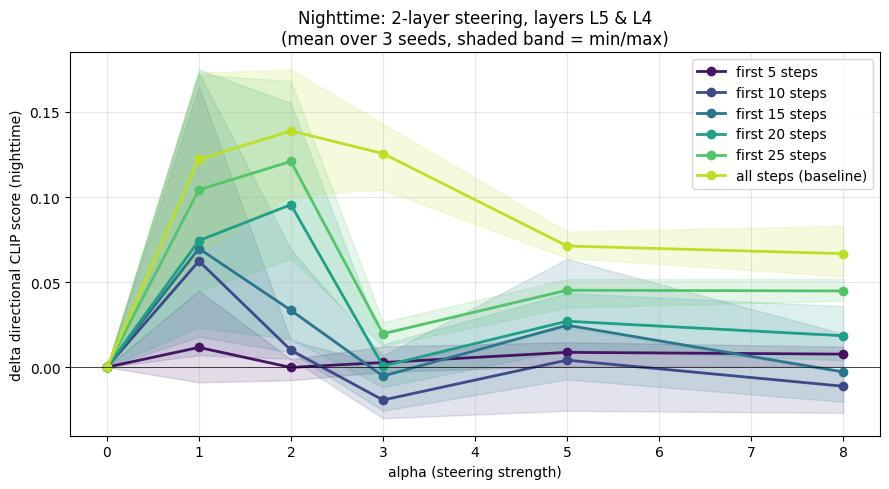

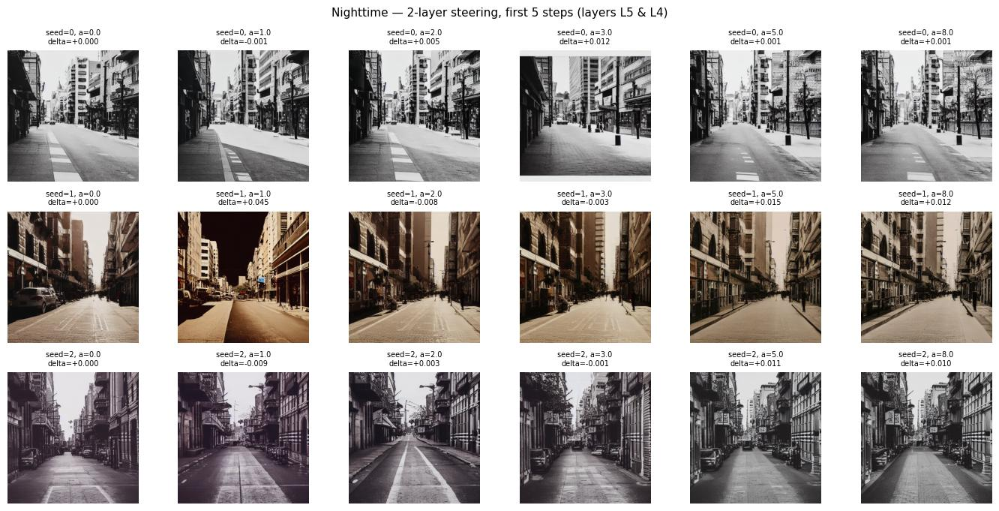

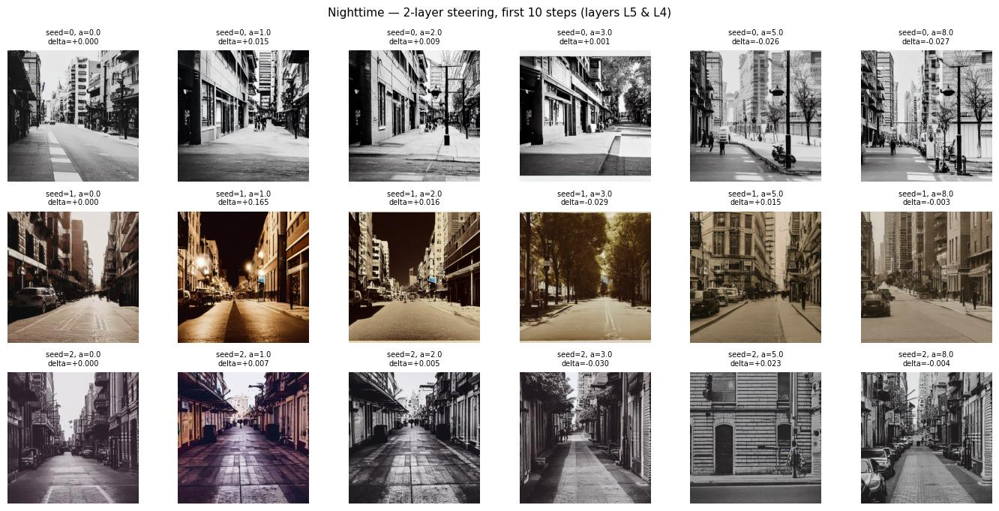

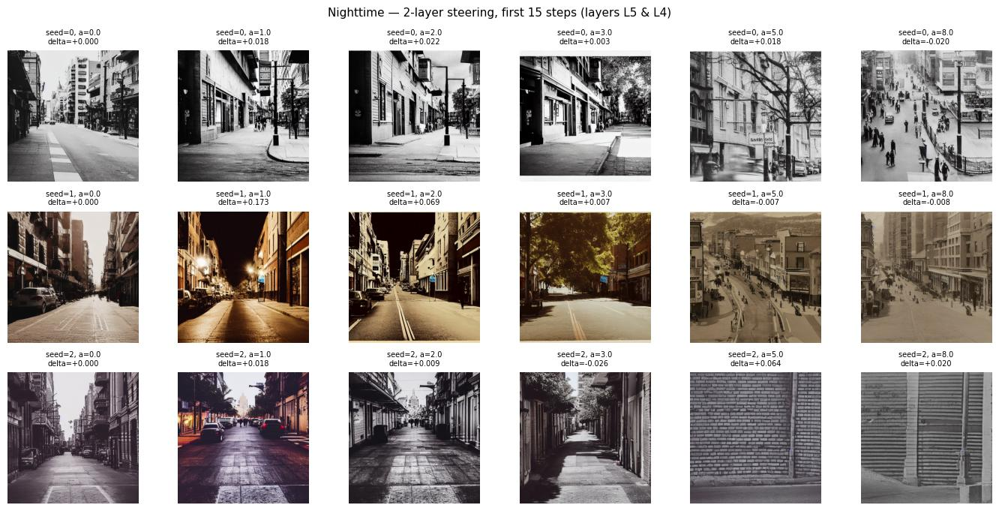

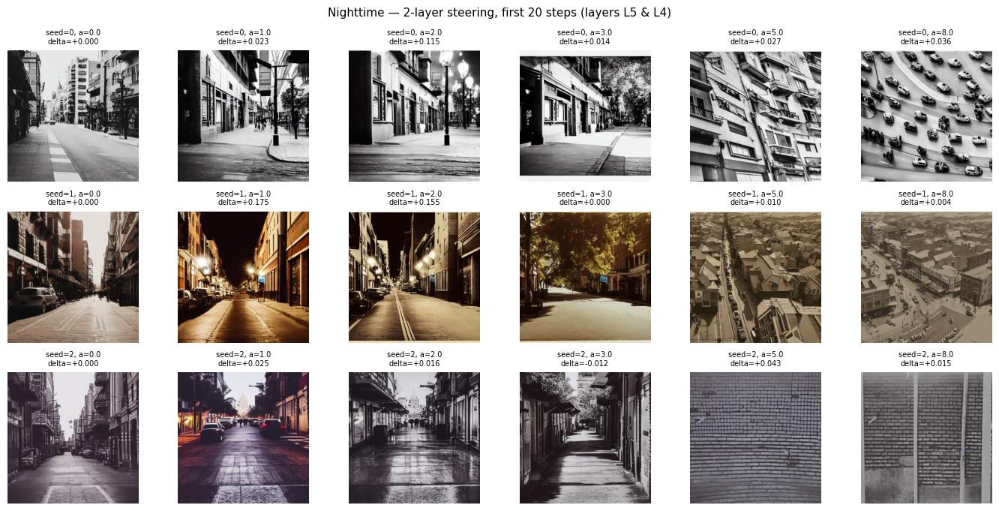

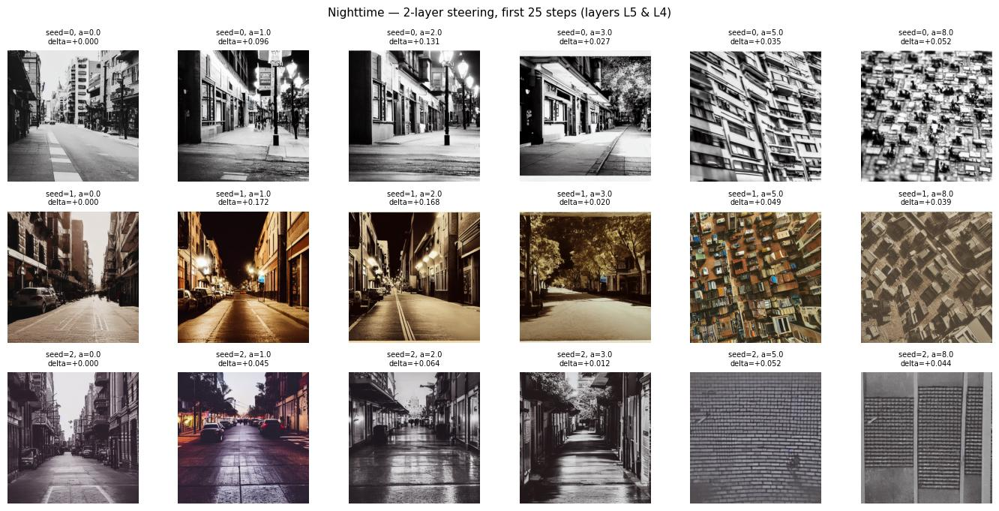

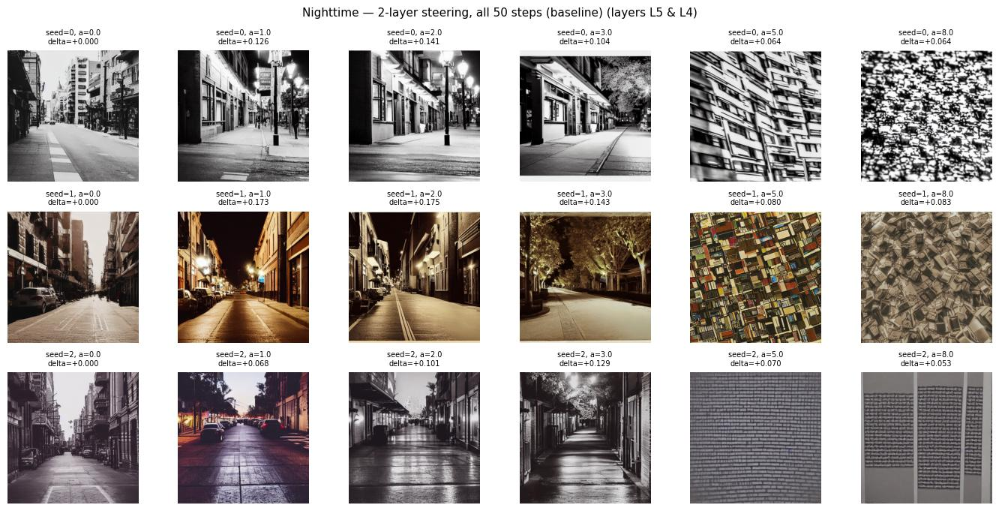

Saved: night_2layer_3seed_curves.png + 6 per-window grids


In [ ]:
# ============================================================
# 2-layer / 3-seed early-step sweep — NIGHTTIME
# ============================================================
night_2l_results, night_2l_images, night_2l_baselines = run_2layer_steering(
    concept_name    = "Nighttime",
    save_prefix     = "night",
    top_layer_idxs  = night_top_layers,
    concept_dirs    = night_dirs,
    steering_prompt = "a photograph of a city street during the day",
    scorer          = night_score,
)

# --- Figure 1: delta vs alpha curves ---
fig, ax = plt.subplots(figsize=(9, 5))
cmap = plt.cm.viridis(np.linspace(0.05, 0.9, len(WINDOWS_2L)))
for c, (w_idx, ms) in zip(cmap, list(enumerate(WINDOWS_2L))):
    per_alpha = night_2l_results[w_idx]
    mean_y    = per_alpha.mean(axis=1)
    lo, hi    = per_alpha.min(axis=1), per_alpha.max(axis=1)
    label = f"first {ms} steps" if ms < NUM_STEPS else "all steps (baseline)"
    ax.plot(ALPHAS_2L, mean_y, "o-", color=c, linewidth=2, label=label)
    ax.fill_between(ALPHAS_2L, lo, hi, color=c, alpha=0.15)
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlabel("alpha (steering strength)")
ax.set_ylabel("delta directional CLIP score (nighttime)")
ax.set_title(f"Nighttime: 2-layer steering, layers L{night_top_layers[0]} & L{night_top_layers[1]}\n"
             f"(mean over 3 seeds, shaded band = min/max)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/night_2layer_3seed_curves.png", dpi=120)
plt.show()

# --- Figure 2: per-window image grids ---
for ms in WINDOWS_2L:
    fig, axes = plt.subplots(len(SEEDS_STEER), len(ALPHAS_2L),
                             figsize=(2.3 * len(ALPHAS_2L),
                                      2.3 * len(SEEDS_STEER)))
    if len(SEEDS_STEER) == 1:
        axes = np.array([axes])
    w_idx = WINDOWS_2L.index(ms)
    for s_idx, seed in enumerate(SEEDS_STEER):
        for a_idx, a in enumerate(ALPHAS_2L):
            ax = axes[s_idx, a_idx]
            ax.imshow(night_2l_images[(ms, a, seed)])
            d = night_2l_results[w_idx, a_idx, s_idx]
            ax.set_title(f"seed={seed}, a={a:.1f}\ndelta={d:+.3f}", fontsize=7)
            ax.axis("off")
    label = f"first {ms} steps" if ms < NUM_STEPS else "all 50 steps (baseline)"
    plt.suptitle(f"Nighttime — 2-layer steering, {label} "
                 f"(layers L{night_top_layers[0]} & L{night_top_layers[1]})",
                 fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/night_2layer_3seed_grid_ms{ms}.png", dpi=120)
    plt.show()

print(f"Saved: night_2layer_3seed_curves.png + 6 per-window grids")


[Red] 2-layer / 3-seed early-step steering
  steering_prompt = 'a photograph of a car'
  layers          = [15, 4]
  windows         = [5, 10, 15, 20, 25, 50]
  alphas          = [0.0, 1.0, 2.0, 3.0, 5.0, 8.0]
  seeds           = [0, 1, 2]
  seed 0 clean baseline = -0.0777
  [  1/108] seed=0 max_step=  5 alpha= 0.0  delta=+0.0000  (2.3s)
  [  2/108] seed=0 max_step=  5 alpha= 1.0  delta=+0.0073  (4.5s)
  [  3/108] seed=0 max_step=  5 alpha= 2.0  delta=+0.0246  (6.6s)
  [  4/108] seed=0 max_step=  5 alpha= 3.0  delta=+0.0221  (8.8s)
  [  5/108] seed=0 max_step=  5 alpha= 5.0  delta=+0.0131  (11.0s)
  [  6/108] seed=0 max_step=  5 alpha= 8.0  delta=+0.0208  (13.2s)
  [  7/108] seed=0 max_step= 10 alpha= 0.0  delta=+0.0000  (13.2s)
  [  8/108] seed=0 max_step= 10 alpha= 1.0  delta=+0.0157  (15.4s)
  [  9/108] seed=0 max_step= 10 alpha= 2.0  delta=+0.0104  (17.6s)
  [ 10/108] seed=0 max_step= 10 alpha= 3.0  delta=+0.1075  (19.8s)
  [ 11/108] seed=0 max_step= 10 alpha= 5.0  delta=+0.0786  

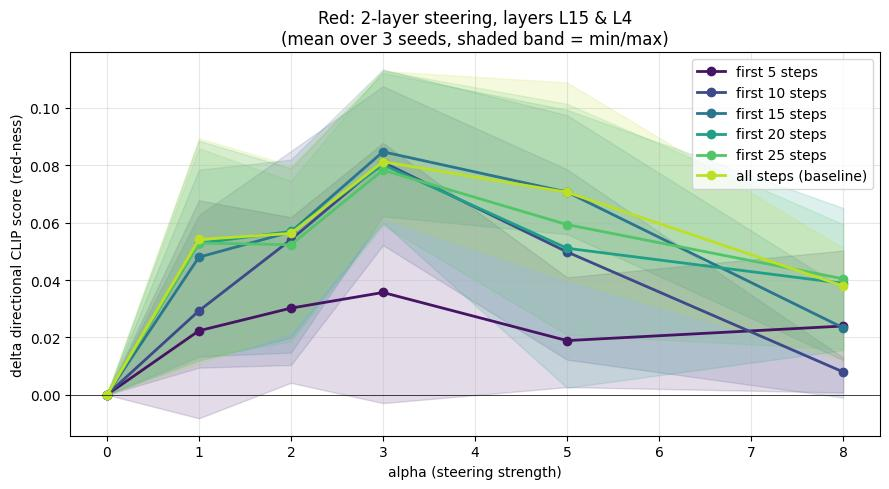

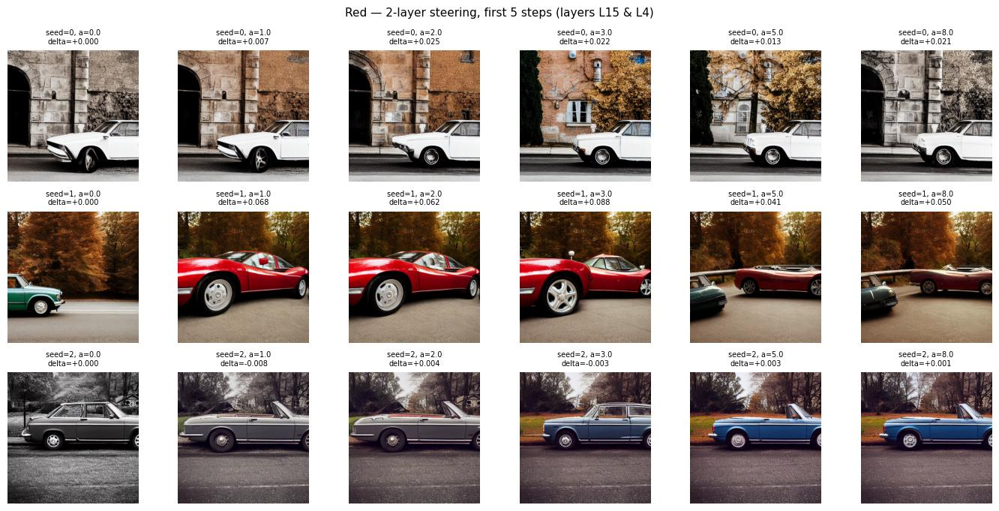

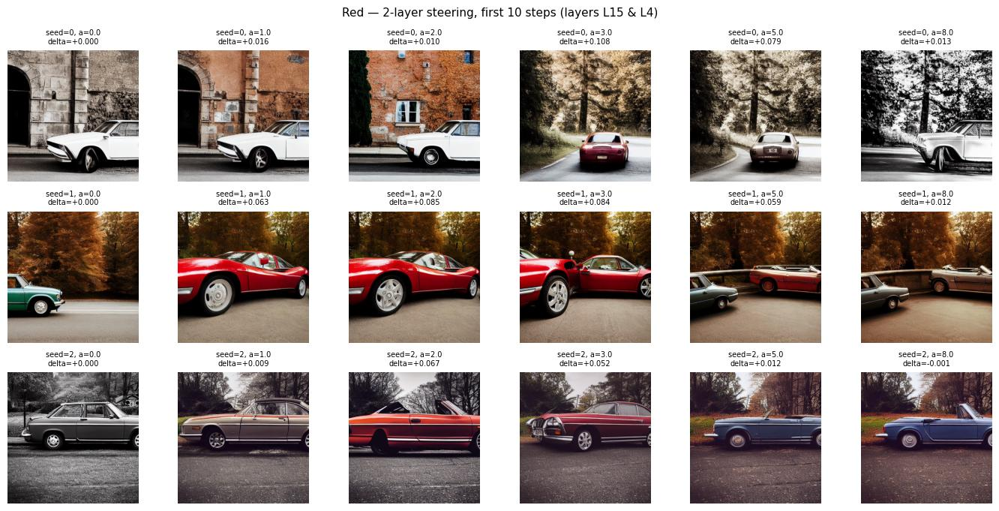

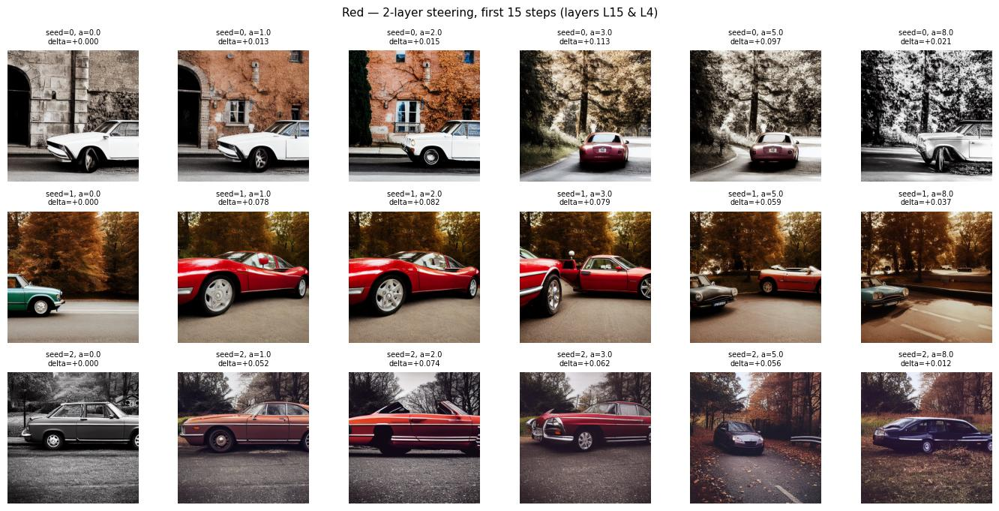

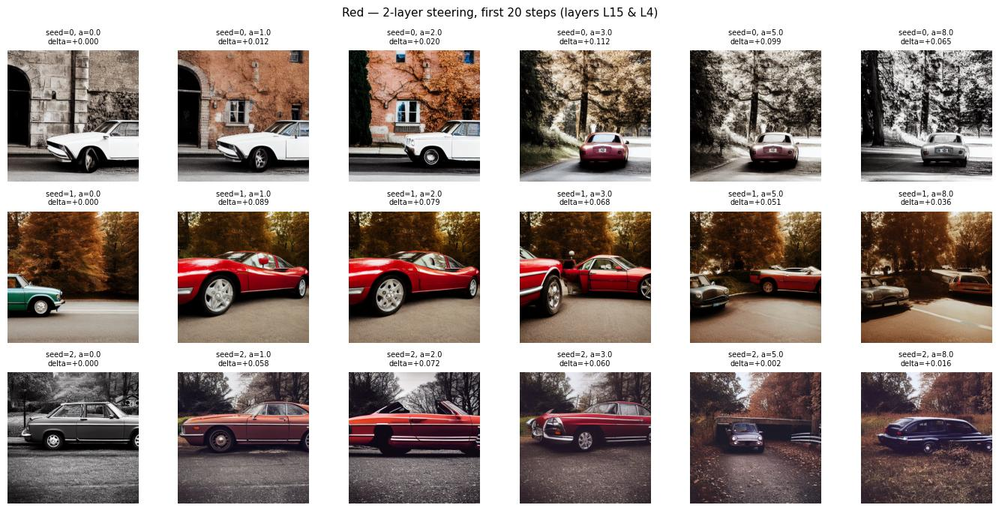

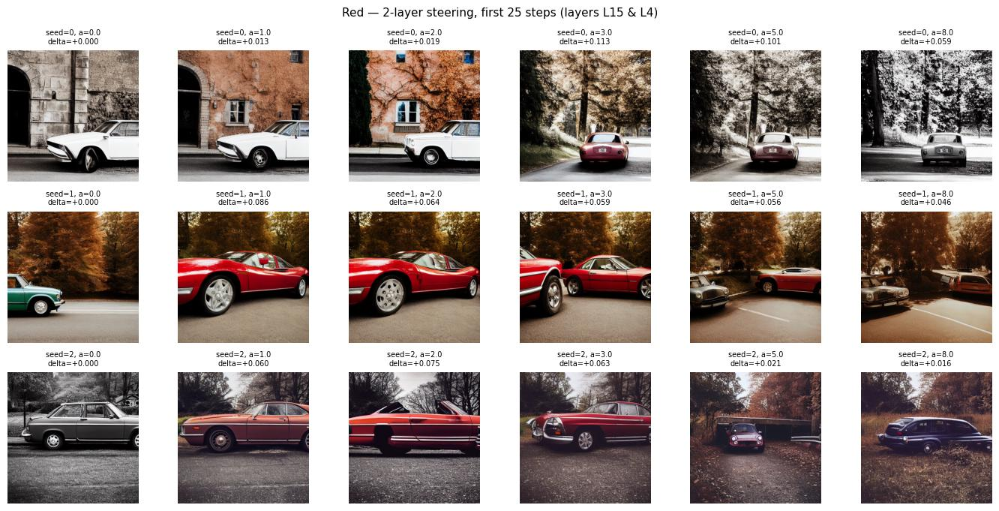

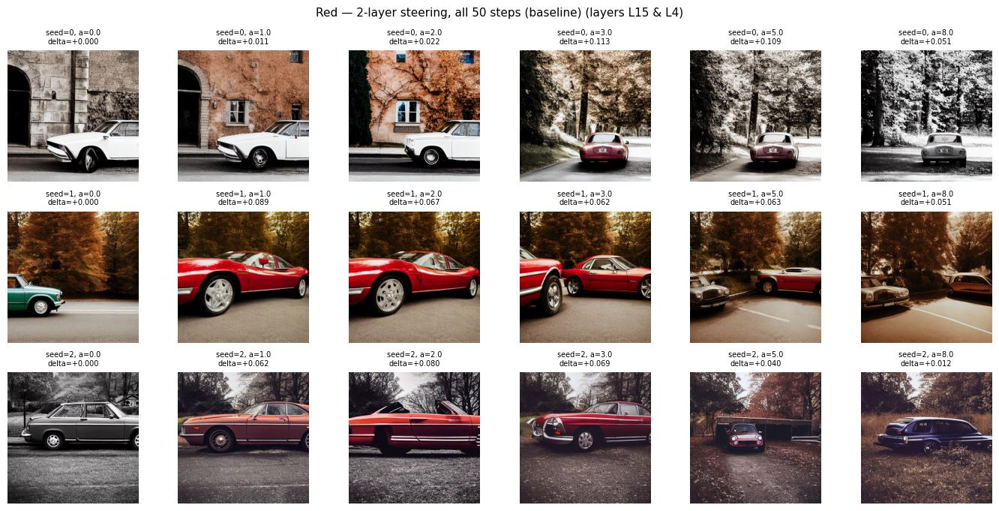

Saved: red_2layer_3seed_curves.png + 6 per-window grids


In [ ]:
# ============================================================
# 2-layer / 3-seed early-step sweep — RED
# ============================================================
red_2l_results, red_2l_images, red_2l_baselines = run_2layer_steering(
    concept_name    = "Red",
    save_prefix     = "red",
    top_layer_idxs  = red_top_layers,
    concept_dirs    = red_dirs,
    steering_prompt = "a photograph of a car",
    scorer          = red_score,
)

# --- Figure 1: delta vs alpha curves ---
fig, ax = plt.subplots(figsize=(9, 5))
cmap = plt.cm.viridis(np.linspace(0.05, 0.9, len(WINDOWS_2L)))
for c, (w_idx, ms) in zip(cmap, list(enumerate(WINDOWS_2L))):
    per_alpha = red_2l_results[w_idx]
    mean_y    = per_alpha.mean(axis=1)
    lo, hi    = per_alpha.min(axis=1), per_alpha.max(axis=1)
    label = f"first {ms} steps" if ms < NUM_STEPS else "all steps (baseline)"
    ax.plot(ALPHAS_2L, mean_y, "o-", color=c, linewidth=2, label=label)
    ax.fill_between(ALPHAS_2L, lo, hi, color=c, alpha=0.15)
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xlabel("alpha (steering strength)")
ax.set_ylabel("delta directional CLIP score (red-ness)")
ax.set_title(f"Red: 2-layer steering, layers L{red_top_layers[0]} & L{red_top_layers[1]}\n"
             f"(mean over 3 seeds, shaded band = min/max)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/red_2layer_3seed_curves.png", dpi=120)
plt.show()

# --- Figure 2: per-window image grids ---
for ms in WINDOWS_2L:
    fig, axes = plt.subplots(len(SEEDS_STEER), len(ALPHAS_2L),
                             figsize=(2.3 * len(ALPHAS_2L),
                                      2.3 * len(SEEDS_STEER)))
    if len(SEEDS_STEER) == 1:
        axes = np.array([axes])
    w_idx = WINDOWS_2L.index(ms)
    for s_idx, seed in enumerate(SEEDS_STEER):
        for a_idx, a in enumerate(ALPHAS_2L):
            ax = axes[s_idx, a_idx]
            ax.imshow(red_2l_images[(ms, a, seed)])
            d = red_2l_results[w_idx, a_idx, s_idx]
            ax.set_title(f"seed={seed}, a={a:.1f}\ndelta={d:+.3f}", fontsize=7)
            ax.axis("off")
    label = f"first {ms} steps" if ms < NUM_STEPS else "all 50 steps (baseline)"
    plt.suptitle(f"Red — 2-layer steering, {label} "
                 f"(layers L{red_top_layers[0]} & L{red_top_layers[1]})",
                 fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/red_2layer_3seed_grid_ms{ms}.png", dpi=120)
    plt.show()

print(f"Saved: red_2layer_3seed_curves.png + 6 per-window grids")

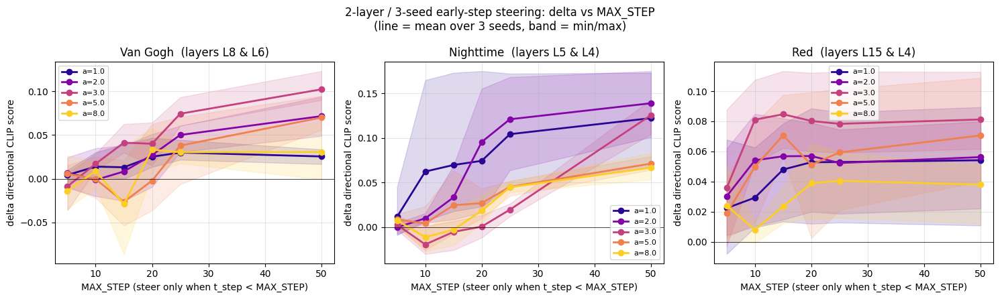

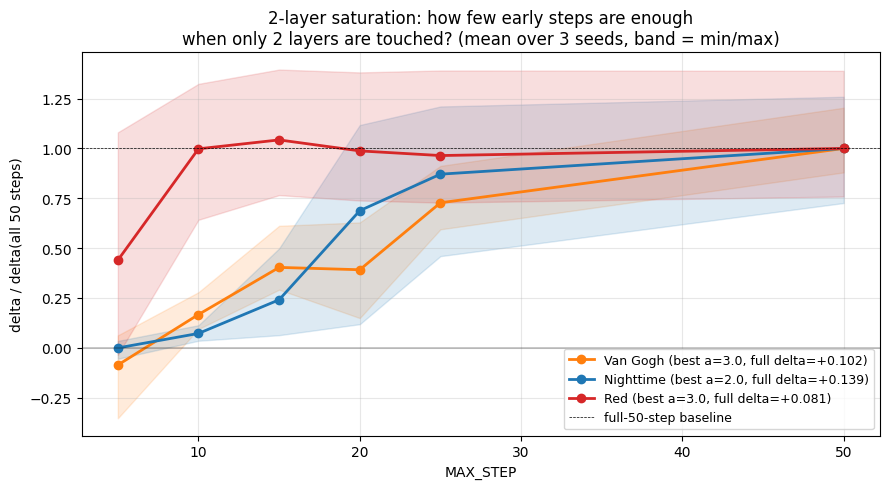


Concept     layers        MAX_STEP    best a   mean delta       min       max   % of full
------------------------------------------------------------------------------
Van Gogh    L8,L6                5       3.0      -0.0089    -0.036    +0.006       -8.7%
Van Gogh    L8,L6               10       3.0      +0.0170    +0.010    +0.028       16.7%
Van Gogh    L8,L6               15       3.0      +0.0412    +0.030    +0.062       40.3%
Van Gogh    L8,L6               20       3.0      +0.0400    +0.015    +0.064       39.1%
Van Gogh    L8,L6               25       3.0      +0.0743    +0.061    +0.093       72.7%
Van Gogh    L8,L6               50       3.0      +0.1021    +0.090    +0.123      100.0%
Nighttime   L5,L4                5       2.0      -0.0001    -0.008    +0.005       -0.1%
Nighttime   L5,L4               10       2.0      +0.0100    +0.005    +0.016        7.2%
Nighttime   L5,L4               15       2.0      +0.0334    +0.009    +0.069       24.1%
Nighttime   L5,L4   

In [ ]:
# ============================================================
# Cross-concept summary — 2-layer / 3-seed experiment
# How does delta CLIP grow as we widen the early window when only the
# top-2 layers per concept are touched? Compare with the earlier
# top-K=20 results to see how much of the effect was carried by
# just those 2 layers.
# ============================================================

CONCEPTS_2L = [
    ("Van Gogh",  vg_2l_results,    vg_top_layers,    "tab:orange"),
    ("Nighttime", night_2l_results, night_top_layers, "tab:blue"),
    ("Red",       red_2l_results,   red_top_layers,   "tab:red"),
]

# --- Figure 1: delta vs MAX_STEP for each (concept, alpha), mean over seeds ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
for ax, (name, res, layers, color) in zip(axes, CONCEPTS_2L):
    nonzero_alphas = [a for a in ALPHAS_2L if a > 0]
    cmap = plt.cm.plasma(np.linspace(0.05, 0.9, len(nonzero_alphas)))
    for c, alpha in zip(cmap, nonzero_alphas):
        a_idx = ALPHAS_2L.index(alpha)
        mean_y = res[:, a_idx, :].mean(axis=1)
        lo, hi = res[:, a_idx, :].min(axis=1), res[:, a_idx, :].max(axis=1)
        ax.plot(WINDOWS_2L, mean_y, "o-", color=c, linewidth=2,
                label=f"a={alpha}")
        ax.fill_between(WINDOWS_2L, lo, hi, color=c, alpha=0.15)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlabel("MAX_STEP (steer only when t_step < MAX_STEP)")
    ax.set_ylabel("delta directional CLIP score")
    ax.set_title(f"{name}  (layers L{layers[0]} & L{layers[1]})")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="best")
plt.suptitle("2-layer / 3-seed early-step steering: delta vs MAX_STEP\n"
             "(line = mean over 3 seeds, band = min/max)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/all_concepts_2layer_delta_vs_maxstep.png", dpi=120)
plt.show()

# --- Figure 2: saturation curves at best alpha per concept ---
fig, ax = plt.subplots(figsize=(9, 5))
for name, res, layers, color in CONCEPTS_2L:
    full_scores_mean = res[-1, :, :].mean(axis=1)        # MAX_STEP=50 row, per alpha
    best_a_idx = int(np.argmax(full_scores_mean))
    best_alpha = ALPHAS_2L[best_a_idx]
    full_delta = full_scores_mean[best_a_idx]
    if abs(full_delta) < 1e-6:
        print(f"  WARNING: {name} baseline delta is ~0, showing absolute deltas")
        ys = res[:, best_a_idx, :].mean(axis=1)
        lo = res[:, best_a_idx, :].min(axis=1)
        hi = res[:, best_a_idx, :].max(axis=1)
        ylabel = "delta directional CLIP score"
    else:
        ys = res[:, best_a_idx, :].mean(axis=1) / full_delta
        lo = res[:, best_a_idx, :].min(axis=1)  / full_delta
        hi = res[:, best_a_idx, :].max(axis=1)  / full_delta
        ylabel = "delta / delta(all 50 steps)"
    ax.plot(WINDOWS_2L, ys, "o-", color=color, linewidth=2,
            label=f"{name} (best a={best_alpha}, full delta={full_delta:+.3f})")
    ax.fill_between(WINDOWS_2L, lo, hi, color=color, alpha=0.15)
ax.axhline(1.0, color="black", linewidth=0.5, linestyle="--",
           label="full-50-step baseline")
ax.axhline(0, color="black", linewidth=0.3)
ax.set_xlabel("MAX_STEP")
ax.set_ylabel(ylabel)
ax.set_title("2-layer saturation: how few early steps are enough\n"
             "when only 2 layers are touched? (mean over 3 seeds, band = min/max)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/all_concepts_2layer_saturation.png", dpi=120)
plt.show()

# --- Numeric summary table ---
print("\n" + "=" * 78)
print(f"{'Concept':<10s}  {'layers':<10s}  {'MAX_STEP':>10s}  "
      f"{'best a':>8s}  {'mean delta':>11s}  {'min':>8s}  {'max':>8s}  {'% of full':>10s}")
print("-" * 78)
for name, res, layers, _ in CONCEPTS_2L:
    full_mean = res[-1, :, :].mean(axis=1)
    best_a_idx = int(np.argmax(full_mean))
    best_alpha = ALPHAS_2L[best_a_idx]
    full_delta = full_mean[best_a_idx]
    layer_str = f"L{layers[0]},L{layers[1]}"
    for w_idx, ms in enumerate(WINDOWS_2L):
        d_mean = res[w_idx, best_a_idx, :].mean()
        d_min  = res[w_idx, best_a_idx, :].min()
        d_max  = res[w_idx, best_a_idx, :].max()
        pct = (d_mean / full_delta * 100) if abs(full_delta) > 1e-6 else float("nan")
        print(f"{name:<10s}  {layer_str:<10s}  {ms:>10d}  "
              f"{best_alpha:>8.1f}  {d_mean:>+11.4f}  {d_min:>+8.3f}  "
              f"{d_max:>+8.3f}  {pct:>9.1f}%")

print("\n2-layer / 3-seed experiment complete.")
print(f"Artifacts in: {DRIVE_DIR}")
print("  *_2layer_3seed_results.npy           (windows, alphas, seeds)")
print("  *_2layer_3seed_baselines.npy         per-seed clean CLIP score")
print("  *_2layer_3seed_curves.png            delta vs alpha curves")
print("  *_2layer_3seed_grid_msXX.png         image grids per window")
print("  all_concepts_2layer_delta_vs_maxstep.png")
print("  all_concepts_2layer_saturation.png")

## 4. Averaged direction vs snapshot (thesis 6.4)

In [ ]:
# ------------------------------------------------------------------
# Shared sweep configuration for the two top-K experiments: the direction
# variant below and the snapshot variant in appendix A. Defined here so
# that section 5 runs whether or not the appendix has been executed.
# ------------------------------------------------------------------
TOPK_VALUES = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
SEEDS_TOPK  = [0, 1, 2]
print(f"TOPK_VALUES = {TOPK_VALUES}")
print(f"SEEDS_TOPK  = {SEEDS_TOPK}")

TOPK_VALUES = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
SEEDS_TOPK  = [0, 1, 2]


In [ ]:
# ============================================================
# VARIANT — TOP-K PATCHING WITH THE DRIVE-AVERAGED CONCEPT DIRECTION
#
# Same ranking as cells 13-16 (vg_matrix etc., from 20 pairs × 5 seeds),
# but the patched value at each top-K cell is now
#     clean_act + alpha * concept_dirs[(t, l)]
# i.e. we ADD the 5-seed-averaged direction at the top-K cells instead of
# copying activations from a single source-prompt run. This isolates the
# question: how much of the steering effect comes from the *averaged*
# direction vs. from a prompt-specific snapshot?
#
# Sweep:
#   - K     in TOPK_VALUES (same as cell 13)
#   - alpha in [1.0, 3.0]   (small + medium; expand if needed)
#   - seed  in [0, 1, 2]
#
# Comparison plot overlays the snapshot-style results from cells 14-16
# (vg_topk_results, night_topk_results, red_topk_results) when present,
# so the two protocols sit on the same axes.
# ============================================================

ALPHAS_DIR_TOPK = [1.0, 3.0]


def run_topk_direction_3seeds(concept_name, save_prefix,
                              ranking_matrix, concept_dirs,
                              patch_prompt, scorer,
                              snapshot_results=None,
                              topk_values=TOPK_VALUES,
                              alphas=ALPHAS_DIR_TOPK,
                              seeds=SEEDS_TOPK):
    """Top-K patching using the Drive-averaged direction at each top-K cell.

    Parameters
    ----------
    ranking_matrix : (N_LAYERS, NUM_STEPS) — Drive matrix, used only to
                     order cells.
    concept_dirs   : dict {(t, layer_name): cpu fp32 tensor of mean_A-mean_B}
                     loaded from {DRIVE_DIR}/<prefix>_concept_dirs_5seeds.pt.
    patch_prompt   : the prompt that gets the clean run + steered patch
                     (e.g. "a photograph of a cat" for VG).
    snapshot_results : optional dict {seed: {K: delta_score}} from the
                     snapshot-style top-K experiment (cells 14-16). If
                     given, plotted as a dashed comparison curve.

    Returns
    -------
    results : np.ndarray of shape (len(alphas), len(seeds), len(topk_values))
              holding delta directional CLIP score.
    images  : dict {(alpha, seed, K): PIL.Image}
    """
    print(f"\n{'='*72}\n[{concept_name}] top-K DIRECTION patching, 3 seeds")
    print(f"  patch_prompt='{patch_prompt}'")
    print(f"  K values = {topk_values}")
    print(f"  alphas   = {alphas}")
    print(f"  seeds    = {seeds}\n{'='*72}")

    # --- Rank cells (same as snapshot experiment) ---
    flat = []
    for l_idx in range(N_LAYERS):
        for t in range(NUM_STEPS):
            flat.append((float(ranking_matrix[l_idx, t]), l_idx, t))
    flat.sort(reverse=True)

    results = np.zeros((len(alphas), len(seeds), len(topk_values)),
                       dtype=np.float32)
    images  = {}
    baselines = {}

    total = len(alphas) * len(seeds) * len(topk_values)
    done  = 0
    t0    = time.time()

    for s_idx, seed in enumerate(seeds):
        # Clean run + per-seed baseline + per-seed cache for clean_act lookups
        clean_img, clean_cache = pipeline.run_and_cache(patch_prompt, seed=seed)
        baseline = scorer(clean_img)
        baselines[seed] = baseline
        print(f"  seed {seed} clean baseline = {baseline:+.4f}")

        for a_idx, alpha in enumerate(alphas):
            for k_idx, K in enumerate(topk_values):
                if K > len(flat):
                    break
                patch = {}
                for _, l_idx, t in flat[:K]:
                    l_name = layer_names_all[l_idx]
                    key = (t, l_name, "out")
                    if key not in clean_cache:
                        continue
                    clean_act = clean_cache[key].float()
                    dir_act   = concept_dirs[(t, l_name)].to(DEVICE)
                    patch[key] = (clean_act + alpha * dir_act).to(DTYPE)
                if not patch:
                    img = clean_img
                else:
                    img = pipeline.run_with_patch(patch, seed=seed,
                                                  prompt=patch_prompt)
                s = scorer(img) - baseline
                results[a_idx, s_idx, k_idx] = s
                images[(alpha, seed, K)] = img
                done += 1
                pct = K / (N_LAYERS * NUM_STEPS) * 100
                print(f"  [{done:3d}/{total}] seed={seed} alpha={alpha:>4.1f} "
                      f"top-{K:>3d} ({pct:>5.1f}%)  delta={s:+.4f}  "
                      f"({time.time()-t0:.1f}s)")

        del clean_cache
        torch.cuda.empty_cache()

    np.save(f"{DRIVE_DIR}/{save_prefix}_topk_dir_3seed_results.npy", results)
    np.save(f"{DRIVE_DIR}/{save_prefix}_topk_dir_3seed_baselines.npy",
            baselines, allow_pickle=True)
    print(f"\n  Saved {save_prefix}_topk_dir_3seed_results.npy "
          f"(shape {results.shape}) in {(time.time()-t0)/60:.1f} min")

    # ============================================================
    # PLOTS
    # ============================================================
    # --- Figure 1: Top-K curves — direction patching vs snapshot ---
    fig, axes = plt.subplots(1, len(alphas), figsize=(7 * len(alphas), 4.5),
                             sharey=True)
    if len(alphas) == 1:
        axes = [axes]
    cmap = plt.cm.viridis(np.linspace(0.1, 0.85, len(seeds)))
    for ax, alpha, a_idx in zip(axes, alphas, range(len(alphas))):
        # Direction-patching: one line per seed
        for c, seed, s_idx in zip(cmap, seeds, range(len(seeds))):
            ax.plot(topk_values, results[a_idx, s_idx, :], "o-",
                    color=c, linewidth=2,
                    label=f"direction (seed {seed}, a={alpha})")
        # Snapshot baseline (mean across seeds) if provided
        if snapshot_results is not None:
            ks = sorted({k for s in snapshot_results
                         for k in snapshot_results[s].keys()})
            mean_snap = []
            for K in ks:
                vals = [snapshot_results[s][K] for s in snapshot_results
                        if K in snapshot_results[s]]
                mean_snap.append(np.mean(vals) if vals else np.nan)
            ax.plot(ks, mean_snap, "s--", color="black", linewidth=1.5,
                    alpha=0.7, label="snapshot (mean over 3 seeds)")
        ax.axhline(0, color="black", linewidth=0.5)
        ax.set_xlabel("number of top cells patched (ranked by summed diff-norm)")
        ax.set_title(f"alpha = {alpha}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7, loc="best")
    axes[0].set_ylabel("delta directional CLIP score")
    plt.suptitle(f"{concept_name}: top-K direction patching vs snapshot patching\n"
                 f"(direction = 20 pairs × 5 seeds mean from Drive)", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/{save_prefix}_topk_dir_vs_snapshot_curves.png", dpi=120)
    plt.show()

    # --- Figure 2: Image grid for the larger alpha — rows = seeds, cols = select K ---
    show_ks = [k for k in [1, 5, 10, 50, 100, 200] if k in topk_values]
    big_alpha = alphas[-1]
    fig, axes = plt.subplots(len(seeds), len(show_ks) + 1,
                             figsize=(2.6 * (len(show_ks) + 1),
                                      2.6 * len(seeds)))
    if len(seeds) == 1:
        axes = np.array([axes])
    for r, seed in enumerate(seeds):
        # Show baseline (unpatched clean run) in first column for reference.
        # We didn't save it above, so reconstruct quickly:
        baseline_score = baselines[seed]
        axes[r, 0].text(0.5, 0.5, f"baseline\nseed {seed}\nscore={baseline_score:+.3f}",
                         ha="center", va="center", fontsize=8)
        axes[r, 0].axis("off")
        for c, K in enumerate(show_ks, start=1):
            img = images.get((big_alpha, seed, K))
            if img is not None:
                axes[r, c].imshow(img)
                d = results[alphas.index(big_alpha),
                            seeds.index(seed),
                            topk_values.index(K)]
                axes[r, c].set_title(f"seed {seed}\nK={K}, a={big_alpha}\n"
                                     f"delta={d:+.3f}", fontsize=7)
            axes[r, c].axis("off")
    plt.suptitle(f"{concept_name}: direction-patched images, alpha={big_alpha} "
                 f"(3 seeds × select K)", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/{save_prefix}_topk_dir_images.png", dpi=120)
    plt.show()

    print(f"  Saved 2 figures with prefix '{save_prefix}_topk_dir_'")
    return results, images, baselines


[Van Gogh] top-K DIRECTION patching, 3 seeds
  patch_prompt='a photograph of a cat'
  K values = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
  alphas   = [1.0, 3.0]
  seeds    = [0, 1, 2]
  seed 0 clean baseline = -0.0385
  [  1/84] seed=0 alpha= 1.0 top-  1 (  0.1%)  delta=+0.0013  (4.4s)
  [  2/84] seed=0 alpha= 1.0 top-  3 (  0.4%)  delta=+0.0017  (6.6s)
  [  3/84] seed=0 alpha= 1.0 top-  5 (  0.6%)  delta=+0.0065  (8.8s)
  [  4/84] seed=0 alpha= 1.0 top- 10 (  1.2%)  delta=+0.0065  (11.0s)
  [  5/84] seed=0 alpha= 1.0 top- 15 (  1.9%)  delta=+0.0097  (13.2s)
  [  6/84] seed=0 alpha= 1.0 top- 20 (  2.5%)  delta=+0.0092  (15.4s)
  [  7/84] seed=0 alpha= 1.0 top- 30 (  3.8%)  delta=+0.0258  (17.6s)
  [  8/84] seed=0 alpha= 1.0 top- 50 (  6.2%)  delta=+0.0346  (19.7s)
  [  9/84] seed=0 alpha= 1.0 top- 75 (  9.4%)  delta=+0.0558  (21.9s)
  [ 10/84] seed=0 alpha= 1.0 top-100 ( 12.5%)  delta=+0.0459  (24.1s)
  [ 11/84] seed=0 alpha= 1.0 top-150 ( 18.8%)  delta=+0.0527  (26

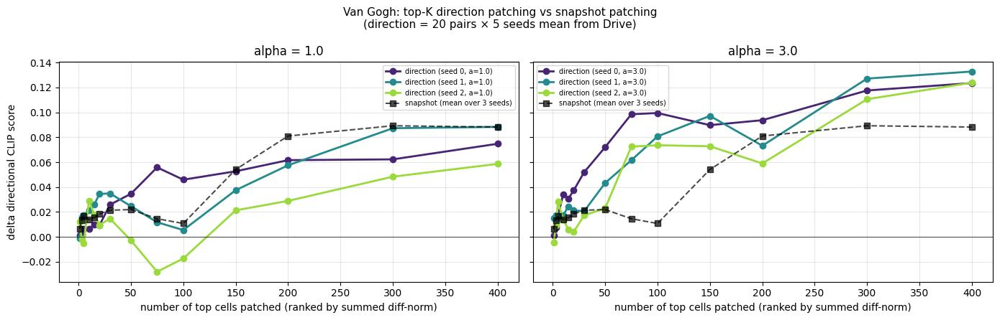

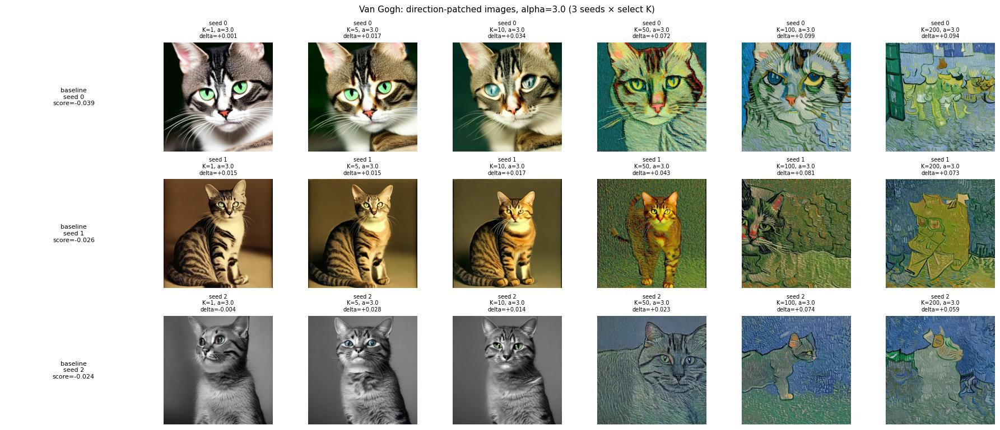

  Saved 2 figures with prefix 'vg_topk_dir_'


In [ ]:
# ============================================================
# Top-K DIRECTION patching — VAN GOGH (3 seeds, 2 alphas)
# ============================================================
vg_topk_dir_results, vg_topk_dir_images, vg_topk_dir_baselines = \
    run_topk_direction_3seeds(
        concept_name     = "Van Gogh",
        save_prefix      = "vg",
        ranking_matrix   = vg_matrix,
        concept_dirs     = vg_dirs,
        patch_prompt     = "a photograph of a cat",
        scorer           = vg_score,
        snapshot_results = vg_topk_results if "vg_topk_results" in globals() else None,
    )


[Nighttime] top-K DIRECTION patching, 3 seeds
  patch_prompt='a photograph of a city street during the day'
  K values = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
  alphas   = [1.0, 3.0]
  seeds    = [0, 1, 2]
  seed 0 clean baseline = -0.0861
  [  1/84] seed=0 alpha= 1.0 top-  1 (  0.1%)  delta=-0.0013  (4.4s)
  [  2/84] seed=0 alpha= 1.0 top-  3 (  0.4%)  delta=-0.0030  (6.6s)
  [  3/84] seed=0 alpha= 1.0 top-  5 (  0.6%)  delta=-0.0035  (8.8s)
  [  4/84] seed=0 alpha= 1.0 top- 10 (  1.2%)  delta=-0.0012  (11.0s)
  [  5/84] seed=0 alpha= 1.0 top- 15 (  1.9%)  delta=-0.0010  (13.2s)
  [  6/84] seed=0 alpha= 1.0 top- 20 (  2.5%)  delta=+0.0062  (15.4s)
  [  7/84] seed=0 alpha= 1.0 top- 30 (  3.8%)  delta=+0.0162  (17.6s)
  [  8/84] seed=0 alpha= 1.0 top- 50 (  6.2%)  delta=+0.0113  (19.8s)
  [  9/84] seed=0 alpha= 1.0 top- 75 (  9.4%)  delta=+0.0343  (22.0s)
  [ 10/84] seed=0 alpha= 1.0 top-100 ( 12.5%)  delta=+0.0511  (24.2s)
  [ 11/84] seed=0 alpha= 1.0 top-150 ( 18

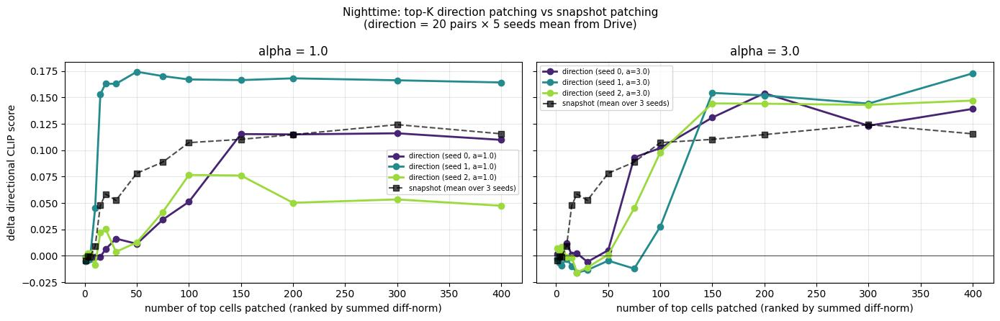

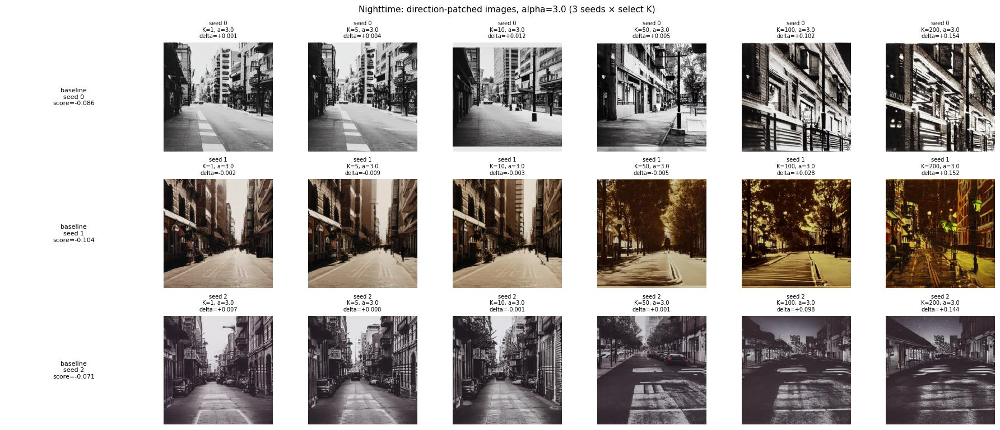

  Saved 2 figures with prefix 'night_topk_dir_'


In [ ]:
# ============================================================
# Top-K DIRECTION patching — NIGHTTIME (3 seeds, 2 alphas)
# ============================================================
night_topk_dir_results, night_topk_dir_images, night_topk_dir_baselines = \
    run_topk_direction_3seeds(
        concept_name     = "Nighttime",
        save_prefix      = "night",
        ranking_matrix   = night_matrix,
        concept_dirs     = night_dirs,
        patch_prompt     = "a photograph of a city street during the day",
        scorer           = night_score,
        snapshot_results = night_topk_results if "night_topk_results" in globals() else None,
    )


[Red] top-K DIRECTION patching, 3 seeds
  patch_prompt='a photograph of a car'
  K values = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
  alphas   = [1.0, 3.0]
  seeds    = [0, 1, 2]
  seed 0 clean baseline = -0.0777
  [  1/84] seed=0 alpha= 1.0 top-  1 (  0.1%)  delta=+0.0071  (4.4s)
  [  2/84] seed=0 alpha= 1.0 top-  3 (  0.4%)  delta=+0.0093  (6.6s)
  [  3/84] seed=0 alpha= 1.0 top-  5 (  0.6%)  delta=+0.0132  (8.9s)
  [  4/84] seed=0 alpha= 1.0 top- 10 (  1.2%)  delta=+0.0165  (11.1s)
  [  5/84] seed=0 alpha= 1.0 top- 15 (  1.9%)  delta=+0.0245  (13.3s)
  [  6/84] seed=0 alpha= 1.0 top- 20 (  2.5%)  delta=+0.0232  (15.5s)
  [  7/84] seed=0 alpha= 1.0 top- 30 (  3.8%)  delta=+0.0165  (17.6s)
  [  8/84] seed=0 alpha= 1.0 top- 50 (  6.2%)  delta=+0.0633  (19.8s)
  [  9/84] seed=0 alpha= 1.0 top- 75 (  9.4%)  delta=+0.0678  (22.0s)
  [ 10/84] seed=0 alpha= 1.0 top-100 ( 12.5%)  delta=+0.1225  (24.2s)
  [ 11/84] seed=0 alpha= 1.0 top-150 ( 18.8%)  delta=+0.1343  (26.4s)


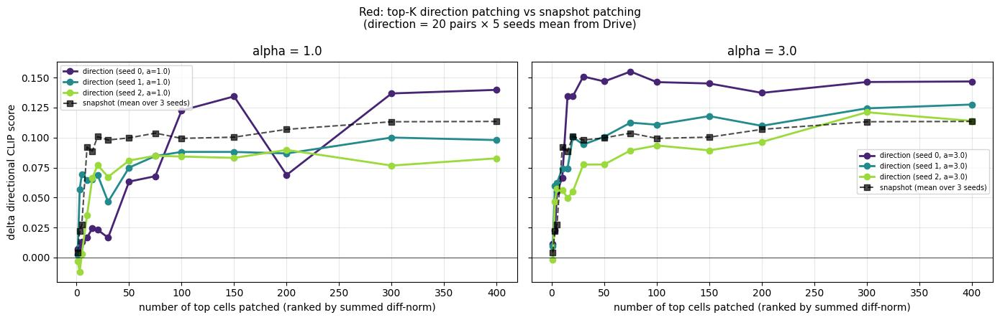

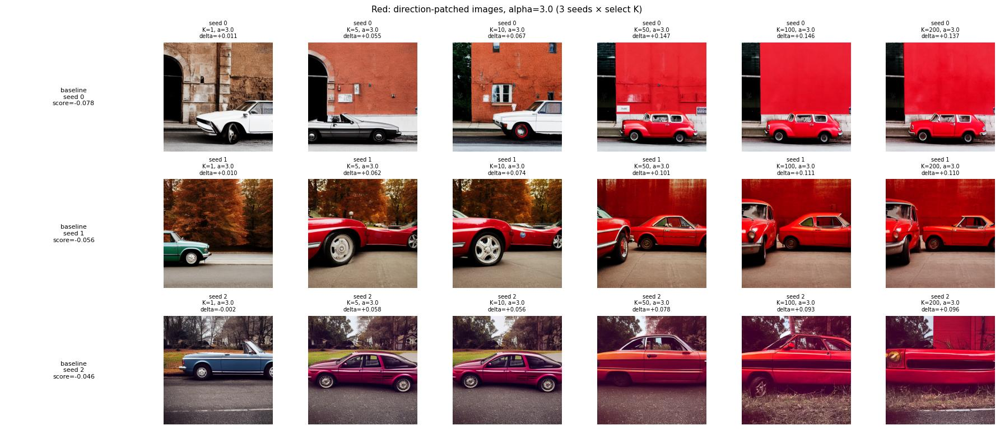

  Saved 2 figures with prefix 'red_topk_dir_'


In [ ]:
# ============================================================
# Top-K DIRECTION patching — RED (3 seeds, 2 alphas)
# ============================================================
red_topk_dir_results, red_topk_dir_images, red_topk_dir_baselines = \
    run_topk_direction_3seeds(
        concept_name     = "Red",
        save_prefix      = "red",
        ranking_matrix   = red_matrix,
        concept_dirs     = red_dirs,
        patch_prompt     = "a photograph of a car",
        scorer           = red_score,
        snapshot_results = red_topk_results if "red_topk_results" in globals() else None,
    )

## 5. Van Gogh or just painting? (thesis 6.5)

5.2  SPECIFICITY — Van Gogh, or painting in general?

  Van Gogh direction  (28s)
     alpha    painted         vg      monet   vg_monet  spec ratio
       1.0    +0.0188    +0.0296    -0.0001    +0.0293       +1.55
       2.0    +0.1667    +0.0887    -0.0113    +0.0981       +0.59
       3.0    +0.1913    +0.1210    +0.0065    +0.1126       +0.59

  Nighttime direction  (56s)
     alpha    painted         vg      monet   vg_monet  spec ratio
       1.0    +0.0349    +0.0293    -0.0121    +0.0405       +1.16
       2.0    +0.0567    +0.0350    -0.0190    +0.0529       +0.93
       3.0    +0.0686    +0.0455    -0.0051    +0.0497       +0.72

----------------------------------------------------------------------
At alpha=3.0, the Van Gogh direction moves:
  painting-vs-photograph  +0.1913
  van-gogh-vs-painting    +0.1210
  monet-vs-painting       +0.0065
  van-gogh-vs-monet       +0.1126

If van-gogh-vs-monet is clearly positive, the direction separates
artists and the thesis may say 'V

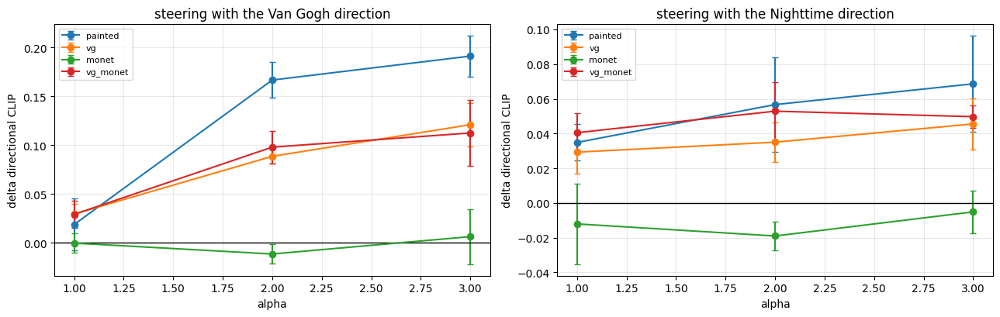


Done in 1.0 min.


In [ ]:
# ============================================================
# 5.1  SPECIFICITY — is the direction "Van Gogh" or just "a painting"?
#
# The thesis claims the direction encodes a particular artist. The cheapest
# way for that claim to be wrong is that it encodes "painted rather than
# photographed", and Van Gogh is simply the most painting-like thing CLIP
# knows. An earlier version of this test used snapshot patching; it has
# never been run with the 5-seed AVERAGED direction, which is what every
# result from section 5 onwards actually uses.
#
# Four CLIP axes are read off every image:
#   painted   "a painting"              vs "a photograph"   <- the generic axis
#   vg        "a van gogh painting"     vs "a painting"
#   monet     "a monet painting"        vs "a painting"
#   vg_monet  "a van gogh painting"     vs "a monet painting"  <- the sharp one
#
# Specificity ratio = delta(vg_monet) / delta(painted). Well above zero means
# the direction distinguishes artists, not just media. Near zero means the
# thesis should say "painterly style" and not "Van Gogh".
#
# Nighttime is steered as a control: it should move none of these axes.
#
# Cost: ~24 generations, ~2 min on an A100.
# ============================================================

SPEC_PROMPT = "a photograph of a house"
SPEC_ALPHAS = [1.0, 2.0, 3.0]
SPEC_SEEDS  = [0, 1, 2]

SPEC_AXES = {
    "painted":  ("a painting", "a photograph"),
    "vg":       ("a van gogh painting", "a painting"),
    "monet":    ("a monet painting", "a painting"),
    "vg_monet": ("a van gogh painting", "a monet painting"),
}
spec_scorers = {k: make_scorer(make_clip_direction(p, n))
                for k, (p, n) in SPEC_AXES.items()}
SPEC_KEYS = list(SPEC_AXES.keys())

SPEC_CONCEPTS = {
    "Van Gogh":  dict(dirs=vg_dirs,    layers=vg_top_layers),
    "Nighttime": dict(dirs=night_dirs, layers=night_top_layers),   # control
}

print("=" * 70)
print("5.2  SPECIFICITY — Van Gogh, or painting in general?")
print("=" * 70)
t0 = time.time()

spec_res = {c: np.zeros((len(SPEC_ALPHAS), len(SPEC_SEEDS), len(SPEC_KEYS)),
                        dtype=np.float32) for c in SPEC_CONCEPTS}
spec_imgs = {}

for cname, cfg in SPEC_CONCEPTS.items():
    for is_, seed in enumerate(SPEC_SEEDS):
        clean_img, cache = pipeline.run_and_cache(SPEC_PROMPT, seed=seed)
        base = {k: spec_scorers[k](clean_img) for k in SPEC_KEYS}
        for ia, alpha in enumerate(SPEC_ALPHAS):
            patch = {}
            for l_idx in cfg["layers"]:
                l_name = layer_names_all[l_idx]
                for t_step in range(NUM_STEPS):
                    key = (t_step, l_name, "out")
                    patch[key] = (cache[key].float()
                                  + alpha * cfg["dirs"][(t_step, l_name)]
                                  .to(DEVICE)).to(DTYPE)
            img = pipeline.run_with_patch(patch, seed=seed, prompt=SPEC_PROMPT)
            for ik, k in enumerate(SPEC_KEYS):
                spec_res[cname][ia, is_, ik] = spec_scorers[k](img) - base[k]
            if seed == SPEC_SEEDS[0]:
                spec_imgs[(cname, alpha)] = img
        del cache
        torch.cuda.empty_cache()

    m = spec_res[cname].mean(axis=1)
    print(f"\n  {cname} direction  ({time.time()-t0:.0f}s)")
    print(f"    {'alpha':>6s}" + "".join(f"{k:>11s}" for k in SPEC_KEYS)
          + f"{'spec ratio':>12s}")
    for ia, alpha in enumerate(SPEC_ALPHAS):
        painted = float(m[ia, SPEC_KEYS.index("painted")])
        vgm = float(m[ia, SPEC_KEYS.index("vg_monet")])
        ratio = vgm / painted if abs(painted) > 1e-6 else float("nan")
        print(f"    {alpha:>6.1f}"
              + "".join(f"{m[ia, ik]:>+11.4f}" for ik in range(len(SPEC_KEYS)))
              + f"{ratio:>+12.2f}")

print("\n" + "-" * 70)
mv = spec_res["Van Gogh"].mean(axis=1)
painted = float(mv[-1, SPEC_KEYS.index("painted")])
vg = float(mv[-1, SPEC_KEYS.index("vg")])
monet = float(mv[-1, SPEC_KEYS.index("monet")])
vgm = float(mv[-1, SPEC_KEYS.index("vg_monet")])
print(f"At alpha={SPEC_ALPHAS[-1]}, the Van Gogh direction moves:")
print(f"  painting-vs-photograph  {painted:+.4f}")
print(f"  van-gogh-vs-painting    {vg:+.4f}")
print(f"  monet-vs-painting       {monet:+.4f}")
print(f"  van-gogh-vs-monet       {vgm:+.4f}")
print("\nIf van-gogh-vs-monet is clearly positive, the direction separates")
print("artists and the thesis may say 'Van Gogh'. If it is near zero while")
print("painting-vs-photograph is large, the honest claim is 'painterly")
print("style', and every 'Van Gogh' in the write-up should be softened.")
print("-" * 70)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, cname in zip(axes, SPEC_CONCEPTS):
    m = spec_res[cname].mean(axis=1)
    sd = spec_res[cname].std(axis=1)
    for ik, k in enumerate(SPEC_KEYS):
        ax.errorbar(SPEC_ALPHAS, m[:, ik], yerr=sd[:, ik], fmt="o-",
                    capsize=3, label=k)
    ax.axhline(0, color="k", lw=1)
    ax.set_title(f"steering with the {cname} direction")
    ax.set_xlabel("alpha")
    ax.set_ylabel("delta directional CLIP")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_specificity.png", dpi=140, bbox_inches="tight")
plt.show()

np.save(f"{DRIVE_DIR}/specificity.npy", spec_res, allow_pickle=True)
print(f"\nDone in {(time.time()-t0)/60:.1f} min.")

In [ ]:
# ============================================================
# 5.2  SPECIFICITY IN IMAGES
#
# Does the Van Gogh direction make "a Van Gogh", or
# just "a painting"? Shown with images:
#   row 1: "a photograph of a house" + the Van Gogh direction, alpha 0..3
#   row 2: what the model draws when ASKED for a painting, a Van Gogh
#          painting and a Monet painting of the same house (same seed)
# If the direction is specific, the steered image should look like the
# Van Gogh reference and not like the Monet one. As a number, the CLIP
# image-to-image similarity of the alpha=3 image to each reference.
#
# Saves: <DRIVE_DIR>/specificity_rerun/spec_seed<k>.jpg  and  spec_similarity.npy
# Cost: 3 seeds x 7 generations = 21 generations, ~3 min.
# ============================================================

SPEC2_PROMPT = "a photograph of a house"
SPEC2_ALPHAS = [0.0, 1.0, 2.0, 3.0]
SPEC2_SEEDS  = [0, 1, 2]
SPEC2_REFS   = {
    "a painting":          "a painting of a house",
    "a Van Gogh painting": "a van gogh painting of a house",
    "a Monet painting":    "a monet painting of a house",
}
SPEC2_DIR = f"{DRIVE_DIR}/specificity_rerun"
os.makedirs(SPEC2_DIR, exist_ok=True)

t0 = time.time()
spec2_sim = np.zeros((len(SPEC2_SEEDS), len(SPEC2_REFS)), dtype=np.float32)

for i_s, seed in enumerate(SPEC2_SEEDS):
    clean_img, cache = pipeline.run_and_cache(SPEC2_PROMPT, seed=seed)
    steered = []
    for a in SPEC2_ALPHAS:
        if a == 0.0:
            steered.append(clean_img)
        else:
            steered.append(pipeline.run_with_patch(
                steer_patch(cache, vg_dirs, vg_top_layers, a),
                seed=seed, prompt=SPEC2_PROMPT))
    del cache
    torch.cuda.empty_cache()

    refs = []
    for p in SPEC2_REFS.values():
        img, c = pipeline.run_and_cache(p, seed=seed)
        del c
        torch.cuda.empty_cache()
        refs.append(img)

    e3 = clip_image_embed(steered[-1])
    for j, r in enumerate(refs):
        spec2_sim[i_s, j] = float(e3 @ clip_image_embed(r))

    grid = labeled_grid(
        rows=[steered, [None] + refs],
        col_headers=[f"α = {a:g}" for a in SPEC2_ALPHAS],
        row_labels=["+ Van Gogh direction", "Asked in the prompt"],
        row_sublabels=["\"a photograph of a house\"", "\"... of a house\""],
        captions=[["", "", "", ""],
                  [""] + list(SPEC2_REFS.keys())],
        left=400,
    )
    grid.save(f"{SPEC2_DIR}/spec_seed{seed}.jpg", quality=90)
    print(f"seed {seed} done ({time.time()-t0:.0f}s)")

np.save(f"{SPEC2_DIR}/spec_similarity.npy", spec2_sim)
print("\nCLIP similarity of the alpha=3 steered image to each reference "
      "(higher = more alike):")
print(f"  {'seed':<6s}" + "".join(f"{k:>22s}" for k in SPEC2_REFS))
for i_s, seed in enumerate(SPEC2_SEEDS):
    print(f"  {seed:<6d}" + "".join(f"{v:>22.4f}" for v in spec2_sim[i_s]))
print(f"  {'mean':<6s}" + "".join(f"{v:>22.4f}" for v in spec2_sim.mean(0)))
print(f"\nImages: {SPEC2_DIR}/spec_seed0.jpg .. spec_seed2.jpg   "
      f"({(time.time()-t0)/60:.1f} min)")

seed 0 done (16s)
seed 1 done (32s)
seed 2 done (48s)

CLIP similarity of the alpha=3 steered image to each reference (higher = more alike):
  seed              a painting   a Van Gogh painting      a Monet painting
  0                     0.7610                0.8244                0.7595
  1                     0.6967                0.8210                0.7995
  2                     0.7113                0.8137                0.7895
  mean                  0.7230                0.8197                0.7828

Images: /content/drive/MyDrive/thesis_public_run/specificity_rerun/spec_seed0.jpg .. spec_seed2.jpg   (0.8 min)


## 6. Erasure (thesis 6.6)

Beyond |alpha| ≈ 4 the image breaks, so the thesis uses alpha up to −3.

In [ ]:
# ============================================================
# ERASURE VIA INVERSE STEERING — 3 concepts × many content prompts × 3 seeds
#
# Idea: take a prompt that INCLUDES the concept (e.g. "a van gogh painting
# of a cat"), then patch the top-2 concept layers across all 50 steps with
#     clean_act + alpha * concept_dirs[(t, l)]
# using NEGATIVE alpha. If the direction really encodes the concept, the
# concept should be removed while the content (cat) stays.
#
# Sweep dimensions:
#   PROMPTS (per concept): 4 concept-full prompts with different content
#   ALPHAS_ERASE : [0.0, -1.0, -2.0, -3.0, -5.0, -8.0]  (0 = baseline)
#   SEEDS_ERASE  : [0, 1, 2]
#   LAYERS       : the top-2 layers of each concept (from cell 8)
#
# Baseline for the delta score is the CONCEPT-FULL image itself (alpha=0),
# so a NEGATIVE delta means the concept was successfully suppressed.
# ============================================================

ALPHAS_ERASE = [0.0, -1.0, -2.0, -3.0, -5.0, -8.0, -12.0, -16.0]
SEEDS_ERASE  = [0, 1, 2]

# Content prompts that already contain the concept — the target of erasure.
ERASE_PROMPTS = {
    "Van Gogh": [
        "a van gogh painting of a cat",
        "a van gogh painting of a woman",
        "a van gogh painting of a house",
        "a van gogh painting of a mountain landscape",
    ],
    "Nighttime": [
        "a photograph of a city street at night",
        "a photograph of a forest at night",
        "a photograph of a bridge at night",
        "a photograph of a castle at night",
    ],
    "Red": [
        "a photograph of a red car",
        "a photograph of a red book",
        "a photograph of a red box",
        "a photograph of a red dress",
    ],
}


def run_inverse_steering_erasure(concept_name, save_prefix, top_layer_idxs,
                                 concept_dirs, prompts, scorer,
                                 alphas=ALPHAS_ERASE, seeds=SEEDS_ERASE):
    """Erasure via inverse steering.

    For each (prompt, alpha, seed):
      - cache the clean run
      - for every cell (t, l) with l in top_layer_idxs and any t in [0, NUM_STEPS):
        patch[key] = (clean_act + alpha * concept_dirs[(t, l)])
      - generate the patched image, score along the concept axis

    Baseline (alpha=0) is the concept-full image at that seed; the delta
    reported is (score(patched) - score(clean)). Negative delta = erasure.

    Returns
    -------
    results : np.ndarray shape (len(prompts), len(alphas), len(seeds))
              — delta directional CLIP score.
    baselines : np.ndarray shape (len(prompts), len(seeds))
                — absolute clean-image score (not delta), useful to see how
                  strong the concept was to begin with.
    images  : dict {(p_idx, alpha, seed): PIL.Image}
    """
    print(f"\n{'='*72}\n[{concept_name}] INVERSE-STEERING ERASURE")
    print(f"  layers          = {top_layer_idxs}")
    print(f"  alphas          = {alphas}")
    print(f"  seeds           = {seeds}")
    print(f"  prompts ({len(prompts)}):")
    for p in prompts:
        print(f"    - {p}")
    print("=" * 72)

    layer_name_set = {layer_names_all[l] for l in top_layer_idxs}
    n_p, n_a, n_s = len(prompts), len(alphas), len(seeds)

    results   = np.zeros((n_p, n_a, n_s), dtype=np.float32)
    baselines = np.zeros((n_p, n_s),      dtype=np.float32)
    images    = {}

    total = n_p * n_a * n_s
    done  = 0
    t0    = time.time()

    for p_idx, prompt in enumerate(prompts):
        for s_idx, seed in enumerate(seeds):
            # Clean run + per-(prompt, seed) baseline + activation cache
            clean_img, clean_cache = pipeline.run_and_cache(prompt, seed=seed)
            base_score = scorer(clean_img)
            baselines[p_idx, s_idx] = base_score
            print(f"  '{prompt}'  seed={seed}  clean score = {base_score:+.4f}")

            for a_idx, alpha in enumerate(alphas):
                if alpha == 0.0:
                    img = clean_img
                else:
                    patch = {}
                    for t_step in range(NUM_STEPS):
                        for l_name in layer_name_set:
                            key = (t_step, l_name, "out")
                            if key not in clean_cache:
                                continue
                            clean_act = clean_cache[key].float()
                            dir_act   = concept_dirs[(t_step, l_name)].to(DEVICE)
                            patch[key] = (clean_act + alpha * dir_act).to(DTYPE)
                    if patch:
                        img = pipeline.run_with_patch(patch, seed=seed,
                                                      prompt=prompt)
                    else:
                        img = clean_img
                delta = scorer(img) - base_score
                results[p_idx, a_idx, s_idx] = delta
                images[(p_idx, alpha, seed)] = img
                done += 1
                print(f"    [{done:3d}/{total}] alpha={alpha:>5.1f}  "
                      f"delta={delta:+.4f}  ({time.time()-t0:.1f}s)")

            del clean_cache
            torch.cuda.empty_cache()

    np.save(f"{DRIVE_DIR}/{save_prefix}_erase_results.npy",   results)
    np.save(f"{DRIVE_DIR}/{save_prefix}_erase_baselines.npy", baselines)
    print(f"\n  Saved {save_prefix}_erase_results.npy (shape {results.shape}) "
          f"in {(time.time()-t0)/60:.1f} min")

    # ============================================================
    # PLOTS
    # ============================================================
    # --- Figure 1: delta vs alpha, one line per prompt (mean over seeds) ---
    fig, ax = plt.subplots(figsize=(10, 5))
    cmap = plt.cm.tab10(np.linspace(0, 1, n_p))
    for c, (p_idx, prompt) in zip(cmap, list(enumerate(prompts))):
        mean_y = results[p_idx].mean(axis=1)
        lo, hi = results[p_idx].min(axis=1), results[p_idx].max(axis=1)
        ax.plot(alphas, mean_y, "o-", color=c, linewidth=2, label=prompt)
        ax.fill_between(alphas, lo, hi, color=c, alpha=0.15)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlabel("alpha (negative = inverse / erasure)")
    ax.set_ylabel("delta directional CLIP score\n(negative = concept suppressed)")
    ax.set_title(f"{concept_name}: erasure via inverse steering\n"
                 f"(top-2 layers L{top_layer_idxs[0]} & L{top_layer_idxs[1]}, "
                 f"all 50 steps, mean over 3 seeds, band = min/max)")
    ax.legend(fontsize=8, loc="best")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/{save_prefix}_erase_curves.png", dpi=120)
    plt.show()

    # --- Figure 2: one image grid per prompt (rows = seeds, cols = alphas) ---
    for p_idx, prompt in enumerate(prompts):
        fig, axes = plt.subplots(n_s, n_a, figsize=(2.3 * n_a, 2.3 * n_s))
        if n_s == 1:
            axes = np.array([axes])
        for r, seed in enumerate(seeds):
            for c, alpha in enumerate(alphas):
                img = images[(p_idx, alpha, seed)]
                axes[r, c].imshow(img)
                delta = results[p_idx, c, r]
                axes[r, c].set_title(f"seed={seed}, a={alpha}\ndelta={delta:+.3f}",
                                     fontsize=7)
                axes[r, c].axis("off")
        safe = prompt.replace(" ", "_")[:40]
        plt.suptitle(f"{concept_name} erasure — '{prompt}'", fontsize=11)
        plt.tight_layout()
        plt.savefig(f"{DRIVE_DIR}/{save_prefix}_erase_grid_p{p_idx}.png", dpi=120)
        plt.show()

    # --- Numeric summary ---
    print("\n" + "=" * 74)
    print(f"{'prompt':<40s} {'best alpha':>10s} {'mean delta':>12s} "
          f"{'baseline':>10s}")
    print("-" * 74)
    for p_idx, prompt in enumerate(prompts):
        mean_delta_per_alpha = results[p_idx].mean(axis=1)   # (alphas,)
        # "Best" for erasure = the alpha with the MOST NEGATIVE mean delta
        best_a_idx = int(np.argmin(mean_delta_per_alpha))
        best_alpha = alphas[best_a_idx]
        best_delta = mean_delta_per_alpha[best_a_idx]
        mean_base  = baselines[p_idx].mean()
        print(f"{prompt[:40]:<40s} {best_alpha:>10.1f} {best_delta:>+12.4f} "
              f"{mean_base:>+10.4f}")

    print(f"\n  Saved erasure curves and {n_p} per-prompt grids in {DRIVE_DIR}")
    return results, baselines, images


[Van Gogh] INVERSE-STEERING ERASURE
  layers          = [8, 6]
  alphas          = [0.0, -1.0, -2.0, -3.0, -5.0, -8.0, -12.0, -16.0]
  seeds           = [0, 1, 2]
  prompts (4):
    - a van gogh painting of a cat
    - a van gogh painting of a woman
    - a van gogh painting of a house
    - a van gogh painting of a mountain landscape
  'a van gogh painting of a cat'  seed=0  clean score = +0.0563
    [  1/96] alpha=  0.0  delta=+0.0000  (2.2s)
    [  2/96] alpha= -1.0  delta=-0.0842  (4.5s)
    [  3/96] alpha= -2.0  delta=-0.0615  (6.7s)
    [  4/96] alpha= -3.0  delta=-0.0560  (9.0s)
    [  5/96] alpha= -5.0  delta=-0.0737  (11.2s)
    [  6/96] alpha= -8.0  delta=-0.0765  (13.4s)
    [  7/96] alpha=-12.0  delta=-0.0909  (15.7s)
    [  8/96] alpha=-16.0  delta=-0.0924  (17.9s)
  'a van gogh painting of a cat'  seed=1  clean score = +0.0538
    [  9/96] alpha=  0.0  delta=+0.0000  (20.2s)
    [ 10/96] alpha= -1.0  delta=-0.0654  (22.4s)
    [ 11/96] alpha= -2.0  delta=-0.0604  (24.7s)

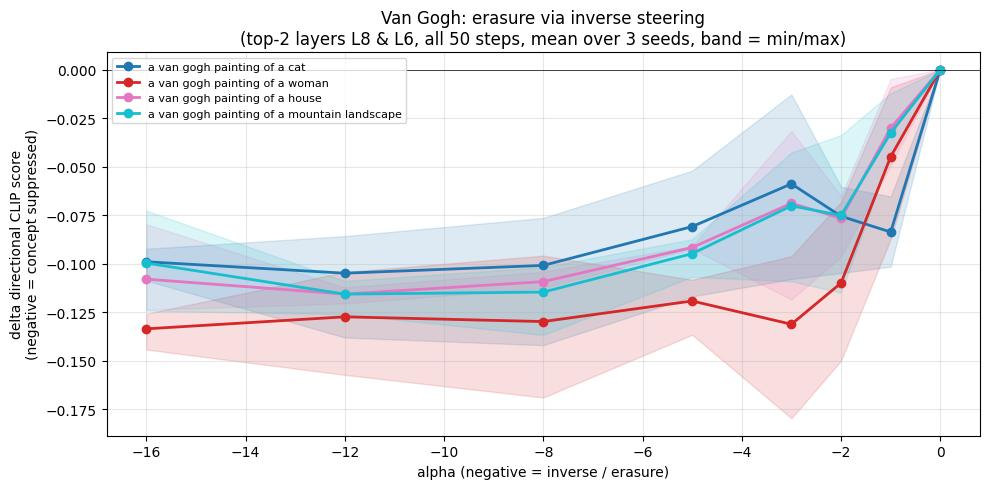

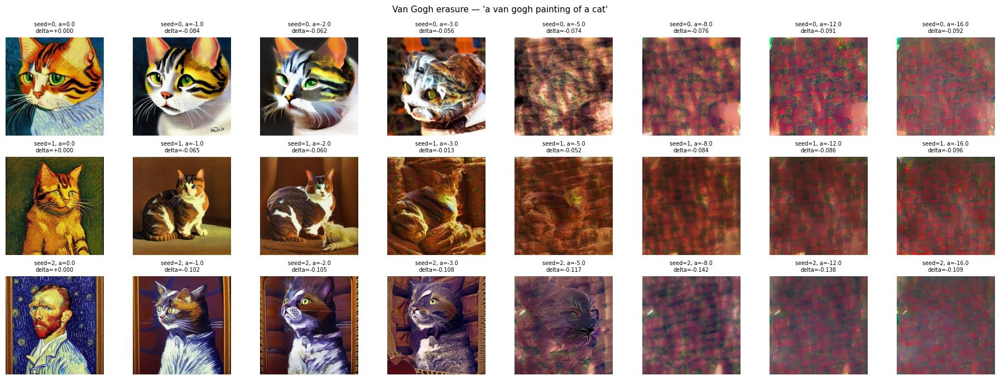

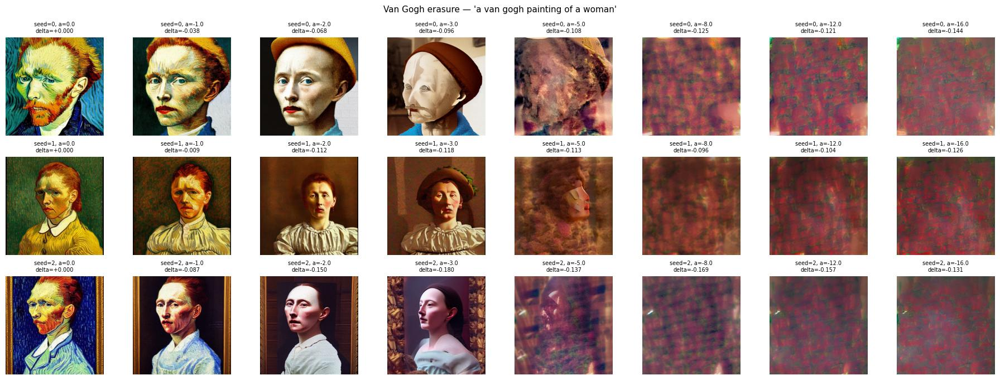

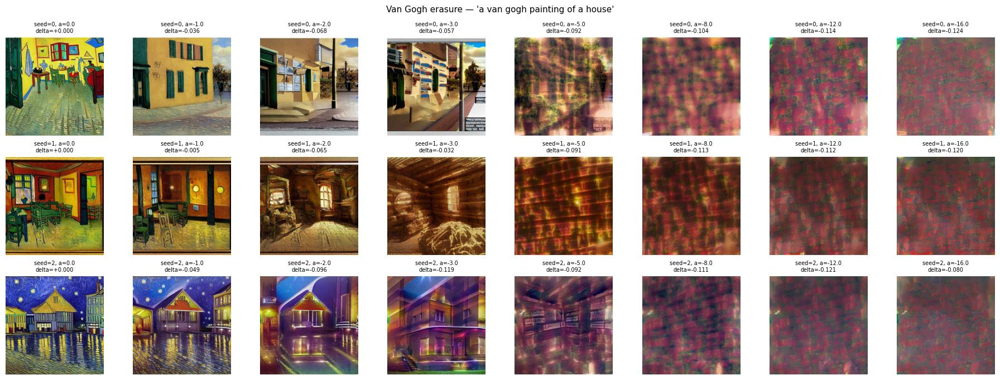

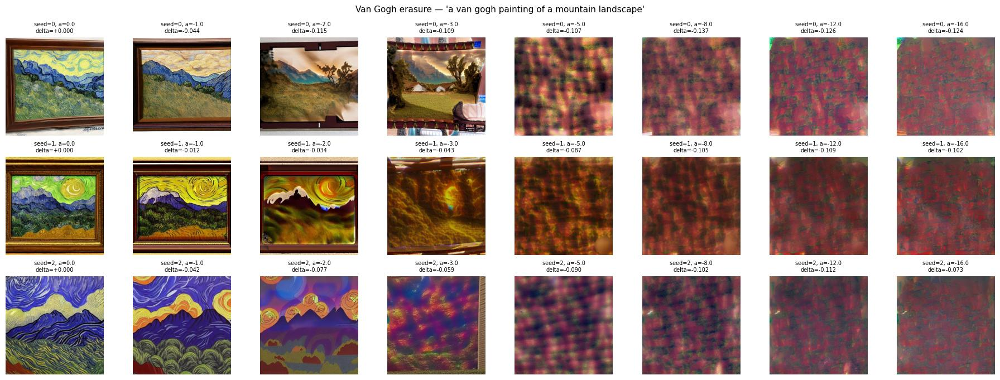


prompt                                   best alpha   mean delta   baseline
--------------------------------------------------------------------------
a van gogh painting of a cat                  -12.0      -0.1050    +0.0724
a van gogh painting of a woman                -16.0      -0.1336    +0.0931
a van gogh painting of a house                -12.0      -0.1157    +0.0762
a van gogh painting of a mountain landsc      -12.0      -0.1158    +0.0729

  Saved erasure curves and 4 per-prompt grids in /content/drive/MyDrive/thesis_public_run


In [ ]:
# ============================================================
# Inverse-steering erasure — VAN GOGH (4 prompts × 6 alphas × 3 seeds)
# ============================================================
vg_erase_results, vg_erase_baselines, vg_erase_images = run_inverse_steering_erasure(
    concept_name    = "Van Gogh",
    save_prefix     = "vg",
    top_layer_idxs  = vg_top_layers,
    concept_dirs    = vg_dirs,
    prompts         = ERASE_PROMPTS["Van Gogh"],
    scorer          = vg_score,
)


[Nighttime] INVERSE-STEERING ERASURE
  layers          = [5, 4]
  alphas          = [0.0, -1.0, -2.0, -3.0, -5.0, -8.0, -12.0, -16.0]
  seeds           = [0, 1, 2]
  prompts (4):
    - a photograph of a city street at night
    - a photograph of a forest at night
    - a photograph of a bridge at night
    - a photograph of a castle at night
  'a photograph of a city street at night'  seed=0  clean score = +0.0594
    [  1/96] alpha=  0.0  delta=+0.0000  (2.3s)
    [  2/96] alpha= -1.0  delta=-0.1280  (4.5s)
    [  3/96] alpha= -2.0  delta=-0.1325  (6.7s)
    [  4/96] alpha= -3.0  delta=-0.1584  (9.0s)
    [  5/96] alpha= -5.0  delta=-0.1516  (11.2s)
    [  6/96] alpha= -8.0  delta=-0.0917  (13.5s)
    [  7/96] alpha=-12.0  delta=-0.0516  (15.7s)
    [  8/96] alpha=-16.0  delta=-0.0770  (17.9s)
  'a photograph of a city street at night'  seed=1  clean score = +0.0666
    [  9/96] alpha=  0.0  delta=+0.0000  (20.2s)
    [ 10/96] alpha= -1.0  delta=-0.1602  (22.4s)
    [ 11/96] alpha= -

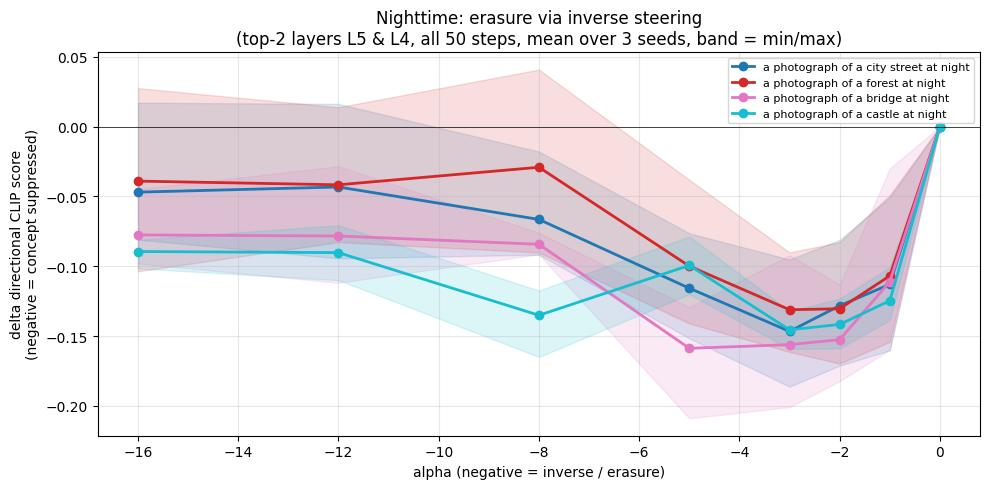

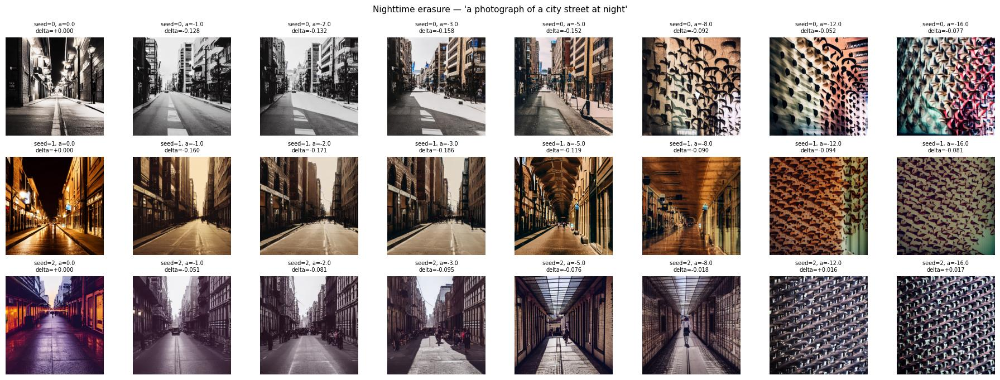

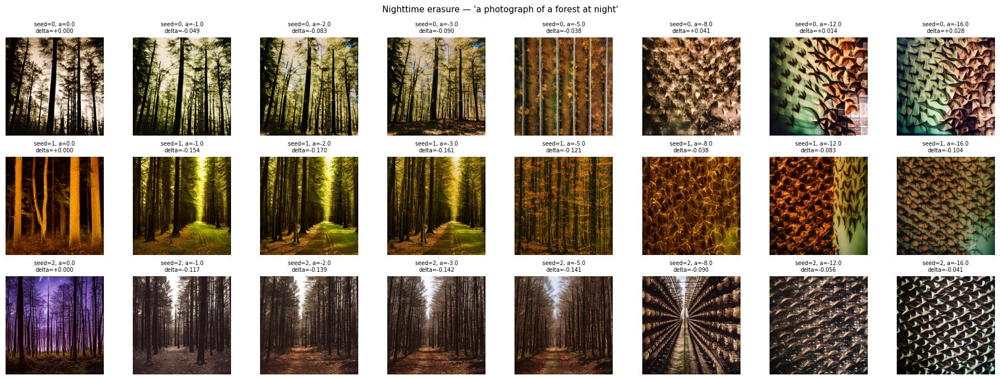

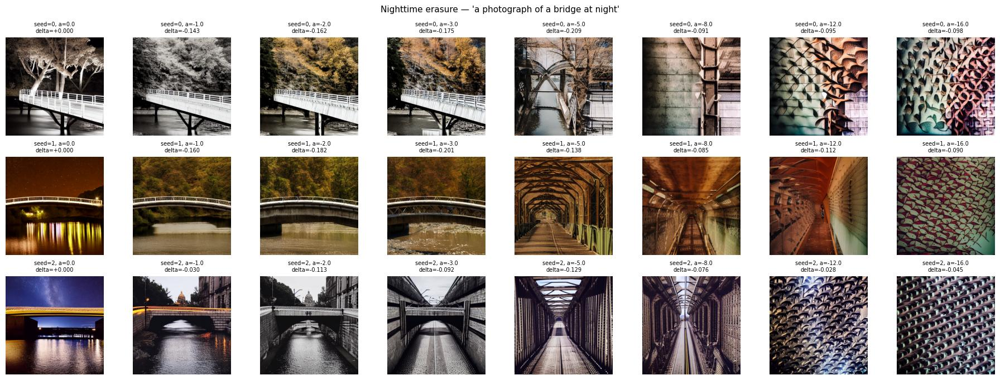

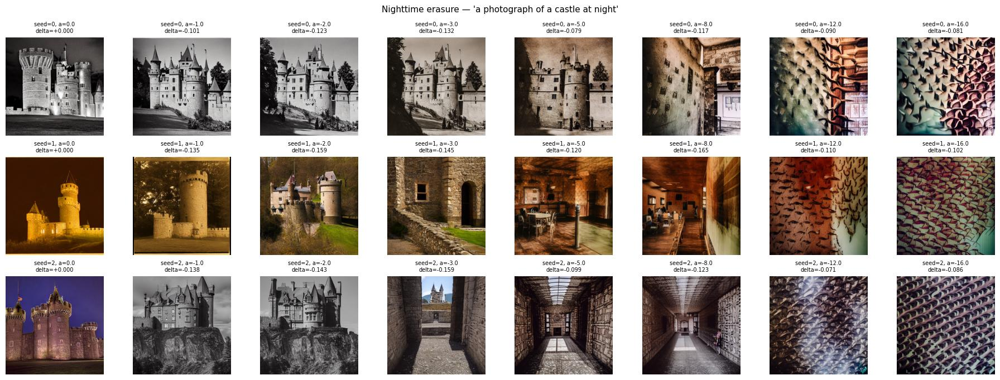


prompt                                   best alpha   mean delta   baseline
--------------------------------------------------------------------------
a photograph of a city street at night         -3.0      -0.1466    +0.0325
a photograph of a forest at night              -3.0      -0.1311    +0.0402
a photograph of a bridge at night              -5.0      -0.1587    +0.0682
a photograph of a castle at night              -3.0      -0.1455    +0.0750

  Saved erasure curves and 4 per-prompt grids in /content/drive/MyDrive/thesis_public_run


In [ ]:
# ============================================================
# Inverse-steering erasure — NIGHTTIME (4 prompts × 6 alphas × 3 seeds)
# ============================================================
night_erase_results, night_erase_baselines, night_erase_images = run_inverse_steering_erasure(
    concept_name    = "Nighttime",
    save_prefix     = "night",
    top_layer_idxs  = night_top_layers,
    concept_dirs    = night_dirs,
    prompts         = ERASE_PROMPTS["Nighttime"],
    scorer          = night_score,
)


[Red] INVERSE-STEERING ERASURE
  layers          = [15, 4]
  alphas          = [0.0, -1.0, -2.0, -3.0, -5.0, -8.0, -12.0, -16.0]
  seeds           = [0, 1, 2]
  prompts (4):
    - a photograph of a red car
    - a photograph of a red book
    - a photograph of a red box
    - a photograph of a red dress
  'a photograph of a red car'  seed=0  clean score = +0.0707
    [  1/96] alpha=  0.0  delta=+0.0000  (2.3s)
    [  2/96] alpha= -1.0  delta=-0.0058  (4.5s)
    [  3/96] alpha= -2.0  delta=-0.0250  (6.7s)
    [  4/96] alpha= -3.0  delta=-0.0222  (8.9s)
    [  5/96] alpha= -5.0  delta=-0.0891  (11.1s)
    [  6/96] alpha= -8.0  delta=-0.0672  (13.4s)
    [  7/96] alpha=-12.0  delta=-0.1450  (15.6s)
    [  8/96] alpha=-16.0  delta=-0.1440  (17.9s)
  'a photograph of a red car'  seed=1  clean score = +0.0306
    [  9/96] alpha=  0.0  delta=+0.0000  (20.1s)
    [ 10/96] alpha= -1.0  delta=+0.0034  (22.3s)
    [ 11/96] alpha= -2.0  delta=+0.0149  (24.5s)
    [ 12/96] alpha= -3.0  delta=+0.01

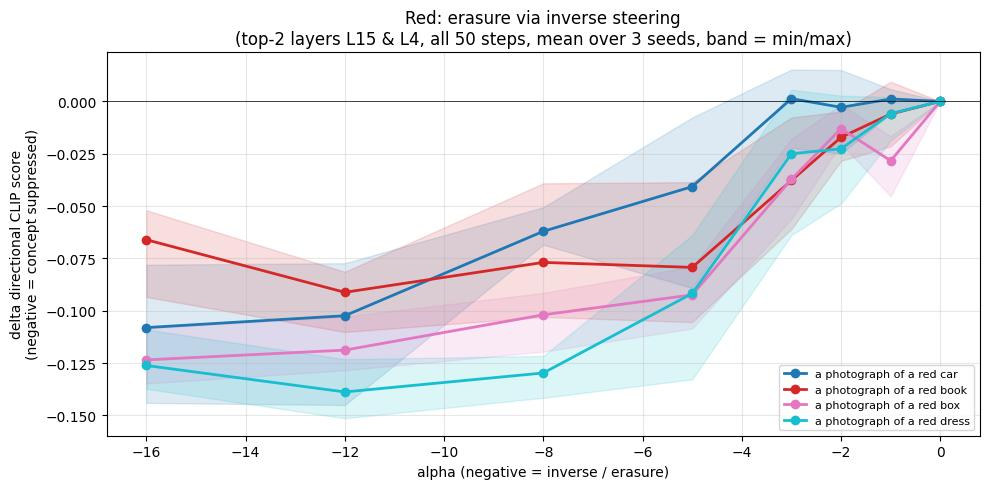

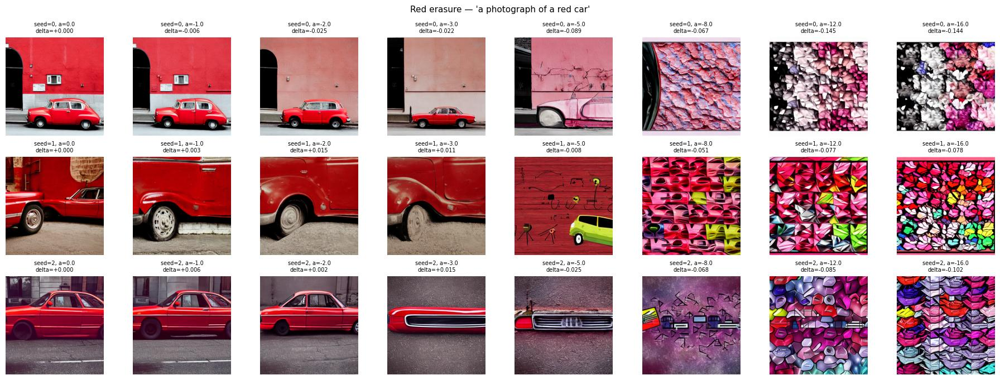

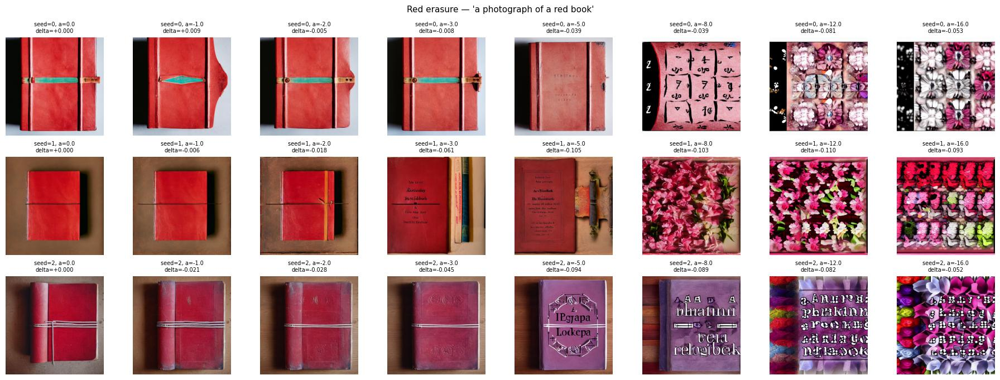

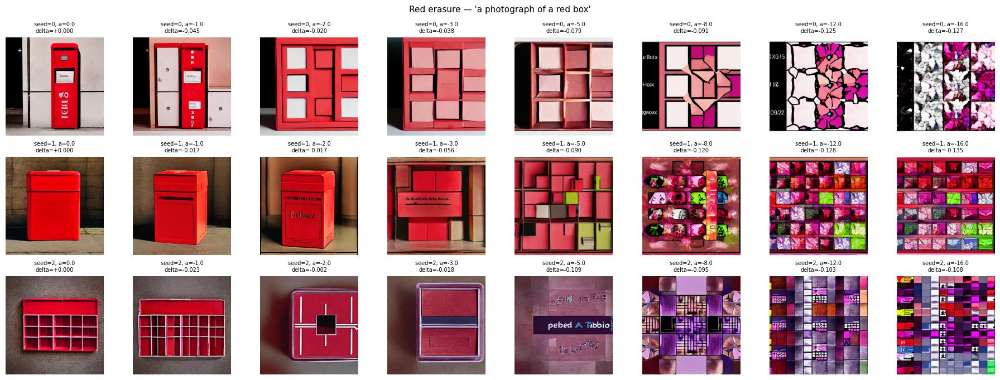

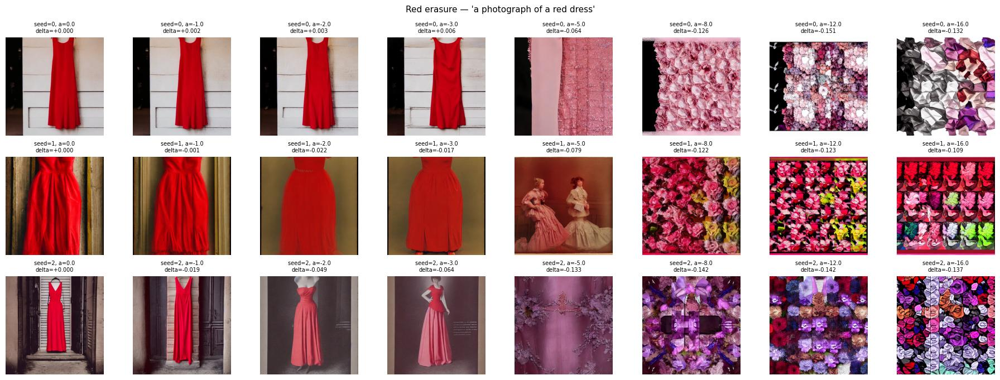


prompt                                   best alpha   mean delta   baseline
--------------------------------------------------------------------------
a photograph of a red car                     -16.0      -0.1081    +0.0527
a photograph of a red book                    -12.0      -0.0912    +0.0149
a photograph of a red box                     -16.0      -0.1235    +0.0657
a photograph of a red dress                   -12.0      -0.1388    +0.0733

  Saved erasure curves and 4 per-prompt grids in /content/drive/MyDrive/thesis_public_run


In [ ]:
# ============================================================
# Inverse-steering erasure — RED (4 prompts × 6 alphas × 3 seeds)
# ============================================================
red_erase_results, red_erase_baselines, red_erase_images = run_inverse_steering_erasure(
    concept_name    = "Red",
    save_prefix     = "red",
    top_layer_idxs  = red_top_layers,
    concept_dirs    = red_dirs,
    prompts         = ERASE_PROMPTS["Red"],
    scorer          = red_score,
)

Does the subject of the image survive the erasure?

6.2  ERASURE / FIDELITY TRADE-OFF

  Van Gogh
      alpha    concept    content   prompt sim
        0.0    +0.0000    +0.0000      +0.0000
       -1.0    -0.0479    +0.0176      -0.0052
       -2.0    -0.0844    +0.0066      -0.0635
       -3.0    -0.0823    -0.0069      -0.0935
       -5.0    -0.0967    -0.0198      -0.1258
       -8.0    -0.1137    -0.0220      -0.1331
      -12.0    -0.1160    -0.0229      -0.1406
      -16.0    -0.1101    -0.0263      -0.1238
    operating point: alpha = -5.0  concept -0.0967  content -0.0198  (content loss within 0.02)

  Nighttime
      alpha    concept    content   prompt sim
        0.0    +0.0000    +0.0000      +0.0000
       -1.0    -0.1139    +0.0023      -0.0472
       -2.0    -0.1382    -0.0004      -0.0644
       -3.0    -0.1448    -0.0059      -0.0789
       -5.0    -0.1184    -0.0099      -0.0766
       -8.0    -0.0787    -0.0479      -0.1100
      -12.0    -0.0633    -0.0649      -0.1240
      -16.0    -0.0632    -0.0622      -0.1271

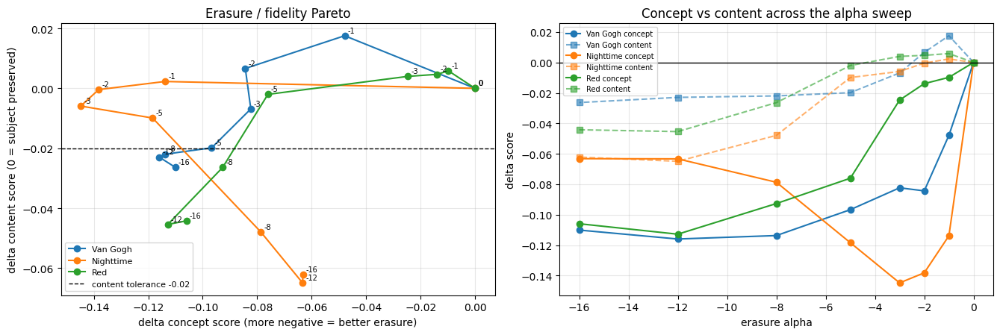


Done in 12s (no images were generated).


In [ ]:
# ============================================================
# 6.2  ERASURE / FIDELITY TRADE-OFF  (no GPU generation)
#
# Section 6 reports only the concept score, and the best alpha is the most
# negative one tested for every prompt - i.e. the sweep never saturated. On
# that evidence alone there is no way to tell erasure from destruction of
# the image.
#
# This cell fixes that WITHOUT generating anything: the erasure functions
# already returned every image they made, keyed (prompt_idx, alpha, seed).
# Each one is re-scored on two extra CLIP axes:
#
#   content  similarity to the bare subject noun ("a cat") - did the subject
#            survive?
#   prompt   similarity to the full original prompt - how far did the image
#            drift overall?
#
# Plotting concept delta against content delta turns the alpha sweep into a
# Pareto curve, and the operating point to quote in the thesis is the alpha
# with the most negative concept score whose content loss stays inside
# CONTENT_TOL.
#
# Prerequisites: the three erasure cells in section 6 must have run in this
# kernel (vg_erase_images, night_erase_images, red_erase_images).
# Cost: CPU/CLIP only, well under a minute.
# ============================================================

CONTENT_TOL = 0.02       # max acceptable drop in CLIP-to-noun

SUBJECT_NOUN = {
    "a van gogh painting of a cat":                 "a cat",
    "a van gogh painting of a woman":               "a woman",
    "a van gogh painting of a house":               "a house",
    "a van gogh painting of a mountain landscape":  "a mountain landscape",
    "a photograph of a city street at night":       "a city street",
    "a photograph of a forest at night":            "a forest",
    "a photograph of a bridge at night":            "a bridge",
    "a photograph of a castle at night":            "a castle",
    "a photograph of a red car":                    "a car",
    "a photograph of a red book":                   "a book",
    "a photograph of a red box":                    "a box",
    "a photograph of a red dress":                  "a dress",
}


@torch.no_grad()
def clip_sim(image, text):
    inputs = clip_proc(text=[text], images=[image],
                       return_tensors="pt", padding=True).to(DEVICE)
    out = clip_model(**inputs)
    i = F.normalize(out.image_embeds, dim=-1)
    t = F.normalize(out.text_embeds, dim=-1)
    return float((i @ t.T).item())


FID_SOURCES = {
    "Van Gogh":  (vg_erase_images,    vg_erase_results,    "Van Gogh"),
    "Nighttime": (night_erase_images, night_erase_results, "Nighttime"),
    "Red":       (red_erase_images,   red_erase_results,   "Red"),
}

print("=" * 70)
print("6.2  ERASURE / FIDELITY TRADE-OFF")
print("=" * 70)
t0 = time.time()

fid = {}     # concept -> array (prompts, alphas, seeds, 2)  [content, prompt]

for cname, (images, results, key) in FID_SOURCES.items():
    prompts = ERASE_PROMPTS[key]
    arr = np.full((len(prompts), len(ALPHAS_ERASE), len(SEEDS_ERASE), 2),
                  np.nan, dtype=np.float32)
    for p_idx, prompt in enumerate(prompts):
        noun = SUBJECT_NOUN.get(prompt, prompt)
        for s_idx, seed in enumerate(SEEDS_ERASE):
            base_img = images.get((p_idx, 0.0, seed))
            if base_img is None:
                continue
            b_noun = clip_sim(base_img, noun)
            b_prompt = clip_sim(base_img, prompt)
            for a_idx, alpha in enumerate(ALPHAS_ERASE):
                img = images.get((p_idx, alpha, seed))
                if img is None:
                    continue
                arr[p_idx, a_idx, s_idx, 0] = clip_sim(img, noun) - b_noun
                arr[p_idx, a_idx, s_idx, 1] = clip_sim(img, prompt) - b_prompt
    fid[cname] = arr

    conc = results.mean(axis=(0, 2))            # (alphas,)
    cont = np.nanmean(arr[:, :, :, 0], axis=(0, 2))
    drift = np.nanmean(arr[:, :, :, 1], axis=(0, 2))
    print(f"\n  {cname}")
    print(f"    {'alpha':>7s} {'concept':>10s} {'content':>10s} "
          f"{'prompt sim':>12s}")
    for a_idx, alpha in enumerate(ALPHAS_ERASE):
        print(f"    {alpha:>7.1f} {conc[a_idx]:>+10.4f} {cont[a_idx]:>+10.4f} "
              f"{drift[a_idx]:>+12.4f}")
    ok = [a_idx for a_idx, _ in enumerate(ALPHAS_ERASE)
          if not np.isnan(cont[a_idx]) and cont[a_idx] >= -CONTENT_TOL]
    if ok:
        best = min(ok, key=lambda i: conc[i])
        print(f"    operating point: alpha = {ALPHAS_ERASE[best]}  "
              f"concept {conc[best]:+.4f}  content {cont[best]:+.4f}  "
              f"(content loss within {CONTENT_TOL})")
    else:
        print(f"    no alpha keeps content loss within {CONTENT_TOL} - "
              f"erasure is not content-preserving at any strength tested")

np.save(f"{DRIVE_DIR}/erasure_fidelity.npy", fid, allow_pickle=True)

# ---- Pareto plot -----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

ax = axes[0]
for cname, (images, results, key) in FID_SOURCES.items():
    conc = results.mean(axis=(0, 2))
    cont = np.nanmean(fid[cname][:, :, :, 0], axis=(0, 2))
    ax.plot(conc, cont, "o-", label=cname)
    for a_idx, alpha in enumerate(ALPHAS_ERASE):
        ax.annotate(f"{alpha:g}", (conc[a_idx], cont[a_idx]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.axhline(-CONTENT_TOL, ls="--", color="k", lw=1,
           label=f"content tolerance {-CONTENT_TOL}")
ax.set_xlabel("delta concept score (more negative = better erasure)")
ax.set_ylabel("delta content score (0 = subject preserved)")
ax.set_title("Erasure / fidelity Pareto")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
for cname, (images, results, key) in FID_SOURCES.items():
    conc = results.mean(axis=(0, 2))
    cont = np.nanmean(fid[cname][:, :, :, 0], axis=(0, 2))
    line, = ax.plot(ALPHAS_ERASE, conc, "o-", label=f"{cname} concept")
    ax.plot(ALPHAS_ERASE, cont, "s--", color=line.get_color(), alpha=0.6,
            label=f"{cname} content")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("erasure alpha")
ax.set_ylabel("delta score")
ax.set_title("Concept vs content across the alpha sweep")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_erasure_fidelity.png", dpi=140,
            bbox_inches="tight")
plt.show()
print(f"\nDone in {time.time()-t0:.0f}s (no images were generated).")

## 7. More layers or later steps? (thesis 6.7)

In [ ]:
# ============================================================
# 7.1  ERASURE — LAYER COUNT × TIMESTEP WINDOW SWEEP (definitions only)
#
# Motivation: the fixed-top-2 / all-50-steps erasure worked for VG and Night
# but was weak for Red. Test two hypotheses simultaneously:
#   A. Red needs more layers (color is distributed across the UNet).
#   B. Red lives in LATE timesteps (color/detail phase), so we should
#      restrict the erasure to t >= MIN_STEP instead of touching all steps.
#
# Sweep dimensions:
#   LAYER_COUNTS_ERASE : [2, 4, 8, 16]        (top-N layers per concept)
#   MIN_STEPS_ERASE    : [0, 15, 25, 35]      (patch only at t >= MIN_STEP)
#   ALPHA_ERASE_LW     : -3.0                 (beyond |alpha| ~ 4 the image breaks)
#   SEEDS_ERASE_LW     : [0, 1, 2]
#   PROMPTS            : 2 representative content prompts per concept
#
# Metric: delta directional CLIP score with per-(prompt, seed) baseline
# taken from the alpha=0 (clean) run of that prompt+seed. Negative delta
# = concept suppressed.
# ============================================================

LAYER_COUNTS_ERASE = [2, 4, 8, 16]
MIN_STEPS_ERASE    = [0, 15, 25, 35]
ALPHA_ERASE_LW     = -3.0
SEEDS_ERASE_LW     = [0, 1, 2]

# Use two content prompts per concept (index 0 and 2 of ERASE_PROMPTS)
ERASE_PROMPTS_LW = {
    name: [ERASE_PROMPTS[name][0], ERASE_PROMPTS[name][2]]
    for name in ERASE_PROMPTS
}


def run_layerwindow_erasure(concept_name, save_prefix,
                            ranking_matrix, concept_dirs,
                            prompts, scorer,
                            layer_counts=LAYER_COUNTS_ERASE,
                            min_steps=MIN_STEPS_ERASE,
                            alpha=ALPHA_ERASE_LW,
                            seeds=SEEDS_ERASE_LW):
    """Layer-count × timestep-window erasure sweep.

    For every (n_layers, MIN_STEP, prompt, seed):
      - pick the top-`n_layers` layers per concept (by summed diff-norm)
      - patch cells (t_step, layer) where t_step >= MIN_STEP AND
        layer in those layers, with clean + alpha * concept_dirs[(t,l)]
      - score along the concept CLIP axis
      - report delta = score(patched) - score(clean_at_that_seed)

    Returns
    -------
    results : (len(layer_counts), len(min_steps), len(prompts), len(seeds))
              delta directional CLIP score.
    baselines : (len(prompts), len(seeds))  absolute clean score.
    images    : dict {(n_layers, min_step, p_idx, seed): PIL.Image}
    """
    print(f"\n{'='*72}\n[{concept_name}] Erasure L × T sweep  (alpha={alpha})")
    print(f"  layer_counts = {layer_counts}")
    print(f"  min_steps    = {min_steps}")
    print(f"  seeds        = {seeds}")
    print(f"  prompts ({len(prompts)}):")
    for p in prompts:
        print(f"    - {p}")
    print("=" * 72)

    # Rank layers ONCE per concept, take up to max(layer_counts)
    max_L = max(layer_counts)
    top_all_layers, _ = top_layers(ranking_matrix, k=max_L)
    print(f"  Top-{max_L} layers (by summed diff-norm): "
          f"{top_all_layers}")
    layer_name_by_count = {
        n: [layer_names_all[l] for l in top_all_layers[:n]]
        for n in layer_counts
    }

    n_L, n_T, n_P, n_S = len(layer_counts), len(min_steps), len(prompts), len(seeds)
    results   = np.zeros((n_L, n_T, n_P, n_S), dtype=np.float32)
    baselines = np.zeros((n_P, n_S),           dtype=np.float32)
    images    = {}

    total = n_L * n_T * n_P * n_S
    done  = 0
    t0    = time.time()

    for p_idx, prompt in enumerate(prompts):
        for s_idx, seed in enumerate(seeds):
            # Clean run + per-(prompt, seed) baseline + cache
            clean_img, clean_cache = pipeline.run_and_cache(prompt, seed=seed)
            base_score = scorer(clean_img)
            baselines[p_idx, s_idx] = base_score
            print(f"\n  '{prompt}'  seed={seed}  clean score = {base_score:+.4f}")

            for L_idx, n_layers in enumerate(layer_counts):
                l_names_set = set(layer_name_by_count[n_layers])
                for T_idx, min_step in enumerate(min_steps):
                    patch = {}
                    for t_step in range(min_step, NUM_STEPS):
                        for l_name in l_names_set:
                            key = (t_step, l_name, "out")
                            if key not in clean_cache:
                                continue
                            clean_act = clean_cache[key].float()
                            dir_act   = concept_dirs[(t_step, l_name)].to(DEVICE)
                            patch[key] = (clean_act + alpha * dir_act).to(DTYPE)
                    if not patch:
                        img = clean_img
                    else:
                        img = pipeline.run_with_patch(patch, seed=seed,
                                                      prompt=prompt)
                    delta = scorer(img) - base_score
                    results[L_idx, T_idx, p_idx, s_idx] = delta
                    images[(n_layers, min_step, p_idx, seed)] = img
                    done += 1
                    print(f"    [{done:3d}/{total}] L={n_layers:>2d} "
                          f"MIN_STEP={min_step:>2d} steps={NUM_STEPS-min_step:>2d}  "
                          f"delta={delta:+.4f}  ({time.time()-t0:.1f}s)")

            del clean_cache
            torch.cuda.empty_cache()

    np.save(f"{DRIVE_DIR}/{save_prefix}_erase_LW_results.npy",   results)
    np.save(f"{DRIVE_DIR}/{save_prefix}_erase_LW_baselines.npy", baselines)
    print(f"\n  Saved {save_prefix}_erase_LW_results.npy "
          f"(shape {results.shape}) in {(time.time()-t0)/60:.1f} min")

    # ============================================================
    # PLOTS
    # ============================================================
    # --- Figure 1: heatmap of mean delta (over prompts + seeds) ---
    fig, axes = plt.subplots(1, n_P + 1, figsize=(4.5 * (n_P + 1), 4.5))
    if n_P + 1 == 1:
        axes = [axes]
    # Panels: one per prompt + one aggregate
    mats = []
    titles = []
    for p_idx, prompt in enumerate(prompts):
        m = results[:, :, p_idx, :].mean(axis=2)   # (L, T)
        mats.append(m)
        titles.append(f"prompt: '{prompt}'\n(mean over 3 seeds)")
    mats.append(results.mean(axis=(2, 3)))
    titles.append("aggregate (mean over prompts + seeds)")
    vmin = min(m.min() for m in mats)
    vmax = max(m.max() for m in mats)
    bound = max(abs(vmin), abs(vmax))
    for ax, m, ttl in zip(axes, mats, titles):
        im = ax.imshow(m, aspect="auto", cmap="RdBu",
                       vmin=-bound, vmax=+bound)
        for i in range(n_L):
            for j in range(n_T):
                ax.text(j, i, f"{m[i, j]:+.2f}", ha="center", va="center",
                        fontsize=8, color="black")
        ax.set_xticks(range(n_T))
        ax.set_xticklabels([f"MIN={ms}\n(last {NUM_STEPS-ms})" for ms in min_steps],
                          fontsize=8)
        ax.set_yticks(range(n_L))
        ax.set_yticklabels([f"top-{n}" for n in layer_counts], fontsize=8)
        ax.set_xlabel("timestep window (MIN_STEP)")
        ax.set_ylabel("layer count (top-N by summed diff-norm)")
        ax.set_title(ttl, fontsize=9)
    fig.colorbar(im, ax=axes[-1], label="delta CLIP (blue = erased)")
    plt.suptitle(f"{concept_name}: erasure delta CLIP as function of "
                 f"(layer count × timestep window)  alpha={alpha}",
                 fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/{save_prefix}_erase_LW_heatmaps.png", dpi=120)
    plt.show()

    # --- Figure 2: per-prompt image grids (seed=0), rows=L, cols=window ---
    for p_idx, prompt in enumerate(prompts):
        show_seed = seeds[0]
        fig, axes = plt.subplots(n_L, n_T, figsize=(2.5 * n_T, 2.5 * n_L))
        if n_L == 1:
            axes = np.array([axes])
        for L_idx, n_layers in enumerate(layer_counts):
            for T_idx, min_step in enumerate(min_steps):
                img = images[(n_layers, min_step, p_idx, show_seed)]
                axes[L_idx, T_idx].imshow(img)
                delta = results[L_idx, T_idx, p_idx, seeds.index(show_seed)]
                axes[L_idx, T_idx].set_title(
                    f"top-{n_layers}, MIN={min_step}\ndelta={delta:+.3f}",
                    fontsize=7)
                axes[L_idx, T_idx].axis("off")
        plt.suptitle(f"{concept_name} erasure — '{prompt}'  "
                     f"seed={show_seed}, alpha={alpha}", fontsize=11)
        plt.tight_layout()
        plt.savefig(f"{DRIVE_DIR}/{save_prefix}_erase_LW_grid_p{p_idx}.png", dpi=120)
        plt.show()

    # --- Summary: best (L, T) combo per prompt ---
    print("\n" + "=" * 80)
    print(f"Best (layer_count, MIN_STEP) combo by most-negative mean delta:")
    print(f"{'prompt':<40s} {'top-N':>7s} {'MIN_STEP':>9s} {'mean delta':>12s} "
          f"{'baseline':>10s}")
    print("-" * 80)
    for p_idx, prompt in enumerate(prompts):
        mean_mat = results[:, :, p_idx, :].mean(axis=2)   # (L, T)
        best_flat = int(np.argmin(mean_mat))
        L_idx, T_idx = np.unravel_index(best_flat, mean_mat.shape)
        best_delta = mean_mat[L_idx, T_idx]
        base_mean  = baselines[p_idx].mean()
        print(f"{prompt[:40]:<40s} {layer_counts[L_idx]:>7d} "
              f"{min_steps[T_idx]:>9d} {best_delta:>+12.4f} {base_mean:>+10.4f}")

    return results, baselines, images


[Van Gogh] Erasure L × T sweep  (alpha=-3.0)
  layer_counts = [2, 4, 8, 16]
  min_steps    = [0, 15, 25, 35]
  seeds        = [0, 1, 2]
  prompts (2):
    - a van gogh painting of a cat
    - a van gogh painting of a house
  Top-16 layers (by summed diff-norm): [8, 6, 4, 7, 5, 15, 11, 3, 2, 0, 10, 1, 14, 13, 12, 9]

  'a van gogh painting of a cat'  seed=0  clean score = +0.0563
    [  1/96] L= 2 MIN_STEP= 0 steps=50  delta=-0.0560  (4.5s)
    [  2/96] L= 2 MIN_STEP=15 steps=35  delta=-0.0547  (6.7s)
    [  3/96] L= 2 MIN_STEP=25 steps=25  delta=-0.0476  (8.9s)
    [  4/96] L= 2 MIN_STEP=35 steps=15  delta=-0.0243  (11.1s)
    [  5/96] L= 4 MIN_STEP= 0 steps=50  delta=-0.0774  (13.4s)
    [  6/96] L= 4 MIN_STEP=15 steps=35  delta=-0.0444  (15.7s)
    [  7/96] L= 4 MIN_STEP=25 steps=25  delta=-0.0530  (17.9s)
    [  8/96] L= 4 MIN_STEP=35 steps=15  delta=-0.0165  (20.1s)
    [  9/96] L= 8 MIN_STEP= 0 steps=50  delta=-0.0826  (22.5s)
    [ 10/96] L= 8 MIN_STEP=15 steps=35  delta=-0.0535

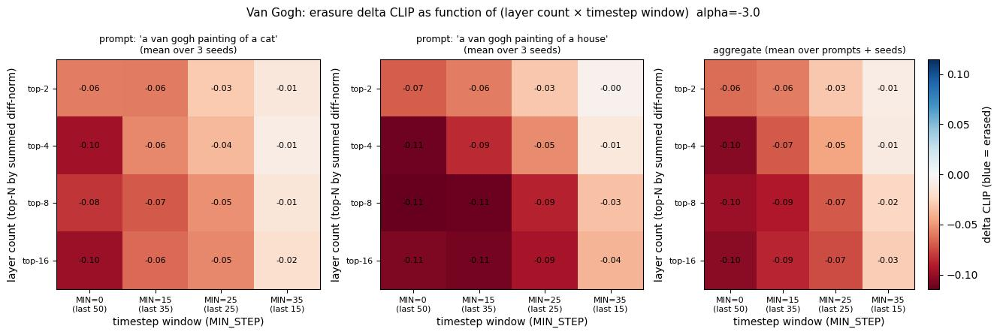

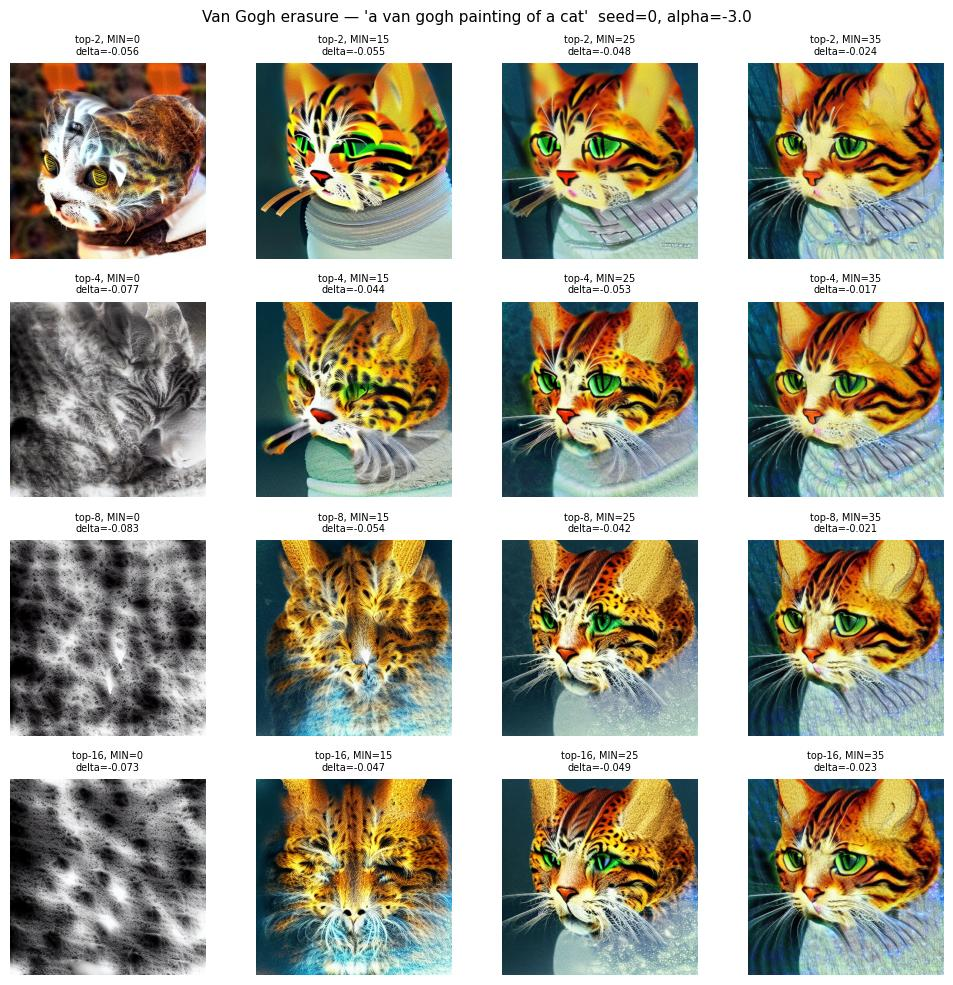

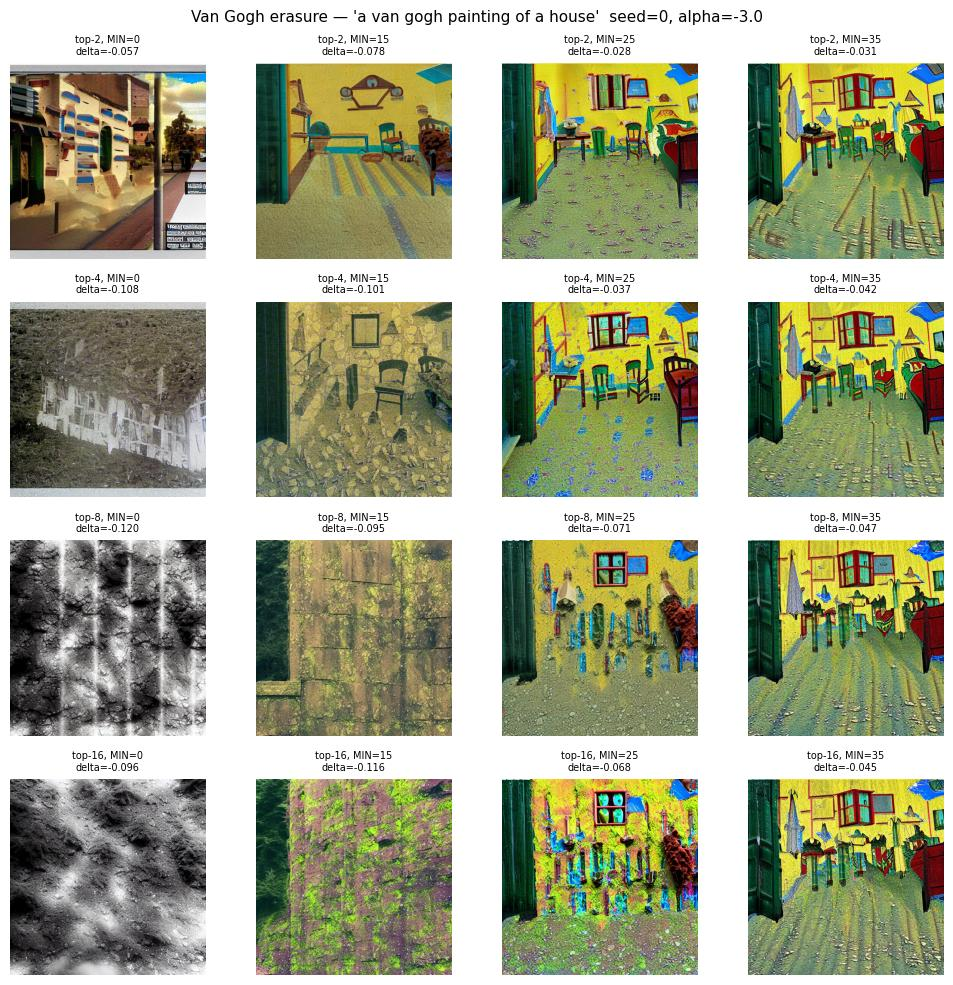


Best (layer_count, MIN_STEP) combo by most-negative mean delta:
prompt                                     top-N  MIN_STEP   mean delta   baseline
--------------------------------------------------------------------------------
a van gogh painting of a cat                  16         0      -0.0988    +0.0724
a van gogh painting of a house                 8         0      -0.1144    +0.0762

[Nighttime] Erasure L × T sweep  (alpha=-3.0)
  layer_counts = [2, 4, 8, 16]
  min_steps    = [0, 15, 25, 35]
  seeds        = [0, 1, 2]
  prompts (2):
    - a photograph of a city street at night
    - a photograph of a bridge at night
  Top-16 layers (by summed diff-norm): [5, 4, 15, 6, 8, 2, 0, 7, 11, 12, 1, 13, 3, 14, 10, 9]

  'a photograph of a city street at night'  seed=0  clean score = +0.0594
    [  1/96] L= 2 MIN_STEP= 0 steps=50  delta=-0.1584  (4.5s)
    [  2/96] L= 2 MIN_STEP=15 steps=35  delta=-0.1297  (6.7s)
    [  3/96] L= 2 MIN_STEP=25 steps=25  delta=-0.0648  (8.9s)
    [  4/96]

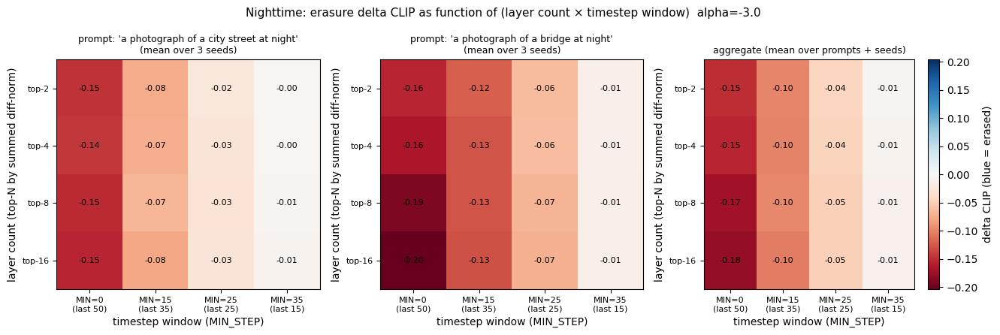

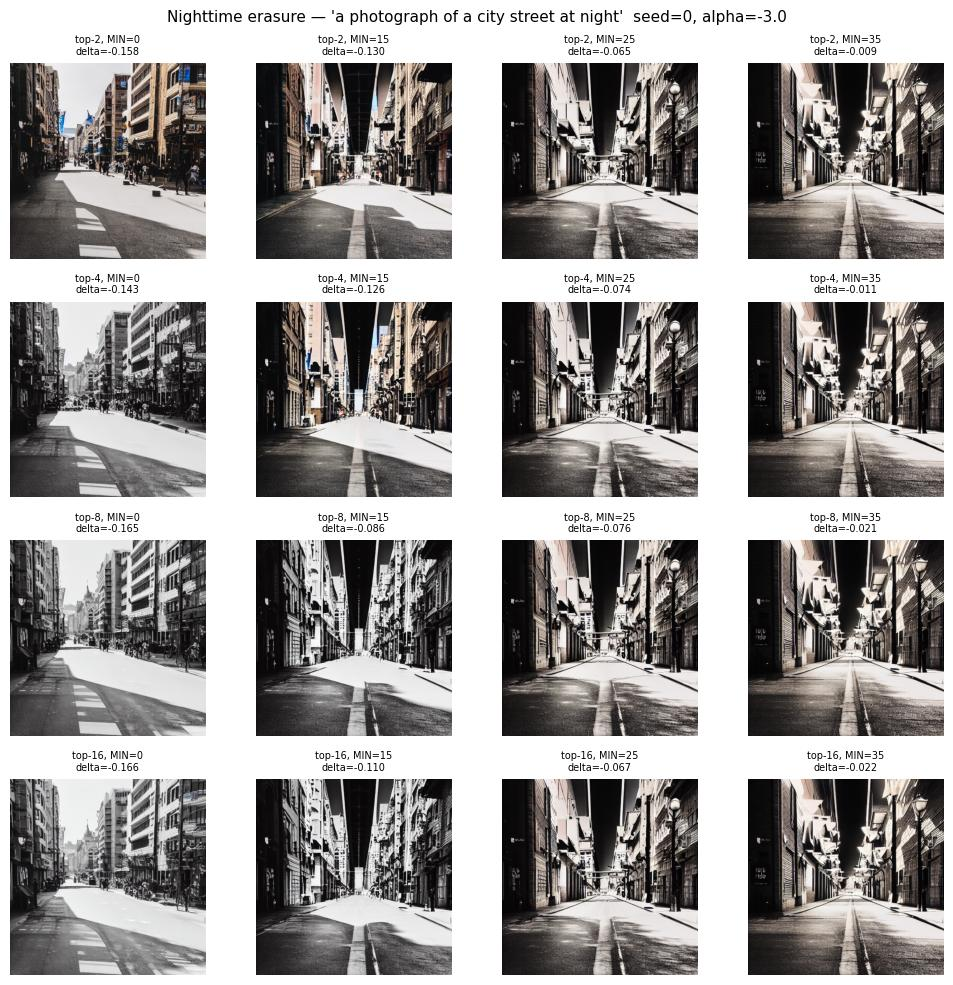

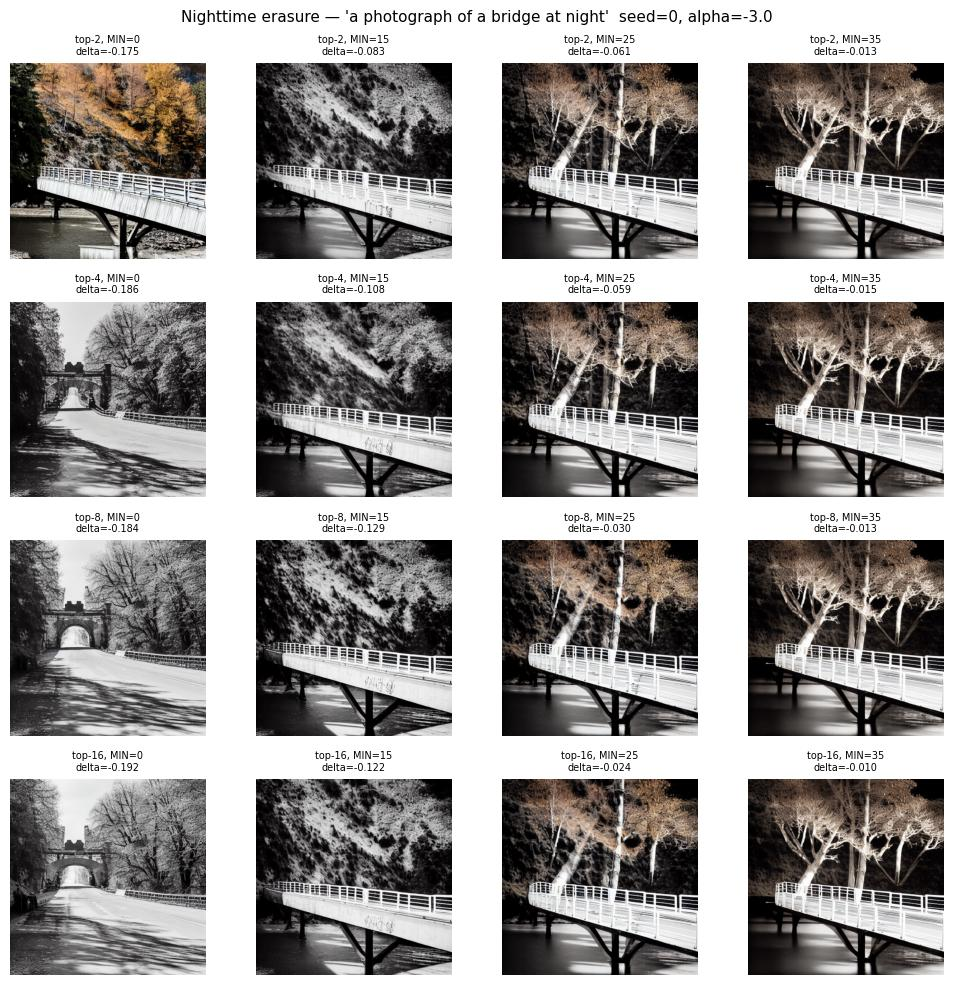


Best (layer_count, MIN_STEP) combo by most-negative mean delta:
prompt                                     top-N  MIN_STEP   mean delta   baseline
--------------------------------------------------------------------------------
a photograph of a city street at night        16         0      -0.1549    +0.0325
a photograph of a bridge at night             16         0      -0.2039    +0.0682

[Red] Erasure L × T sweep  (alpha=-3.0)
  layer_counts = [2, 4, 8, 16]
  min_steps    = [0, 15, 25, 35]
  seeds        = [0, 1, 2]
  prompts (2):
    - a photograph of a red car
    - a photograph of a red box
  Top-16 layers (by summed diff-norm): [15, 4, 5, 6, 8, 11, 7, 0, 2, 10, 12, 13, 1, 14, 3, 9]

  'a photograph of a red car'  seed=0  clean score = +0.0707
    [  1/96] L= 2 MIN_STEP= 0 steps=50  delta=-0.0222  (4.5s)
    [  2/96] L= 2 MIN_STEP=15 steps=35  delta=-0.0074  (6.7s)
    [  3/96] L= 2 MIN_STEP=25 steps=25  delta=-0.0011  (8.9s)
    [  4/96] L= 2 MIN_STEP=35 steps=15  delta=+0.001

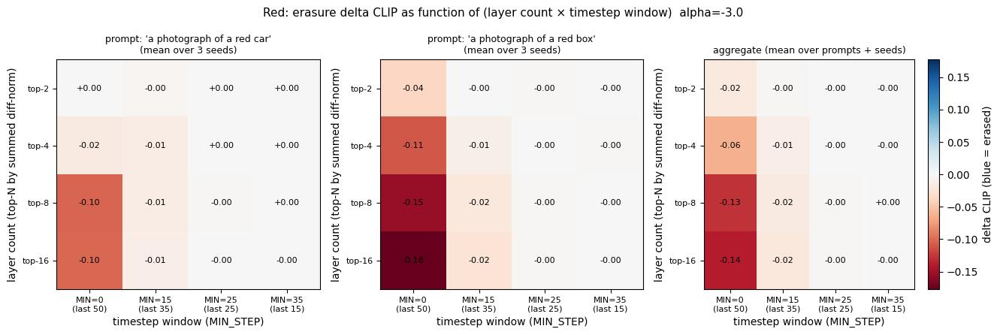

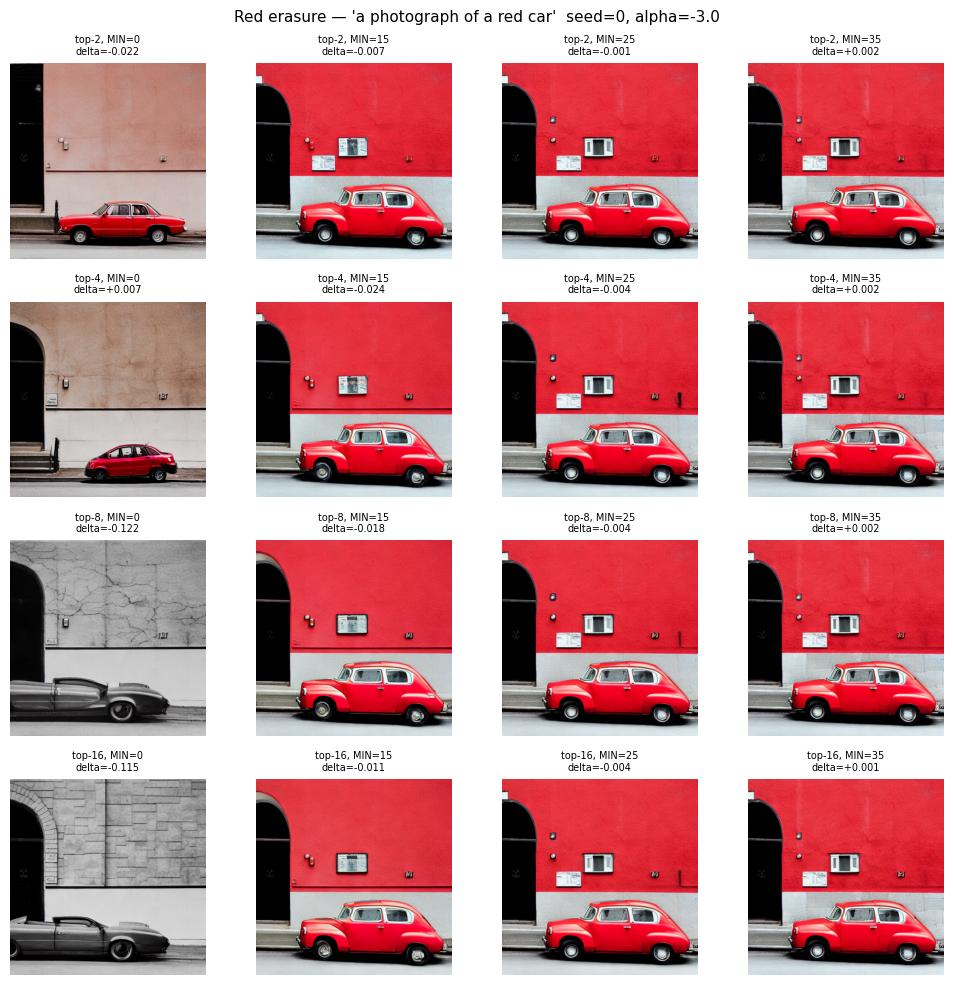

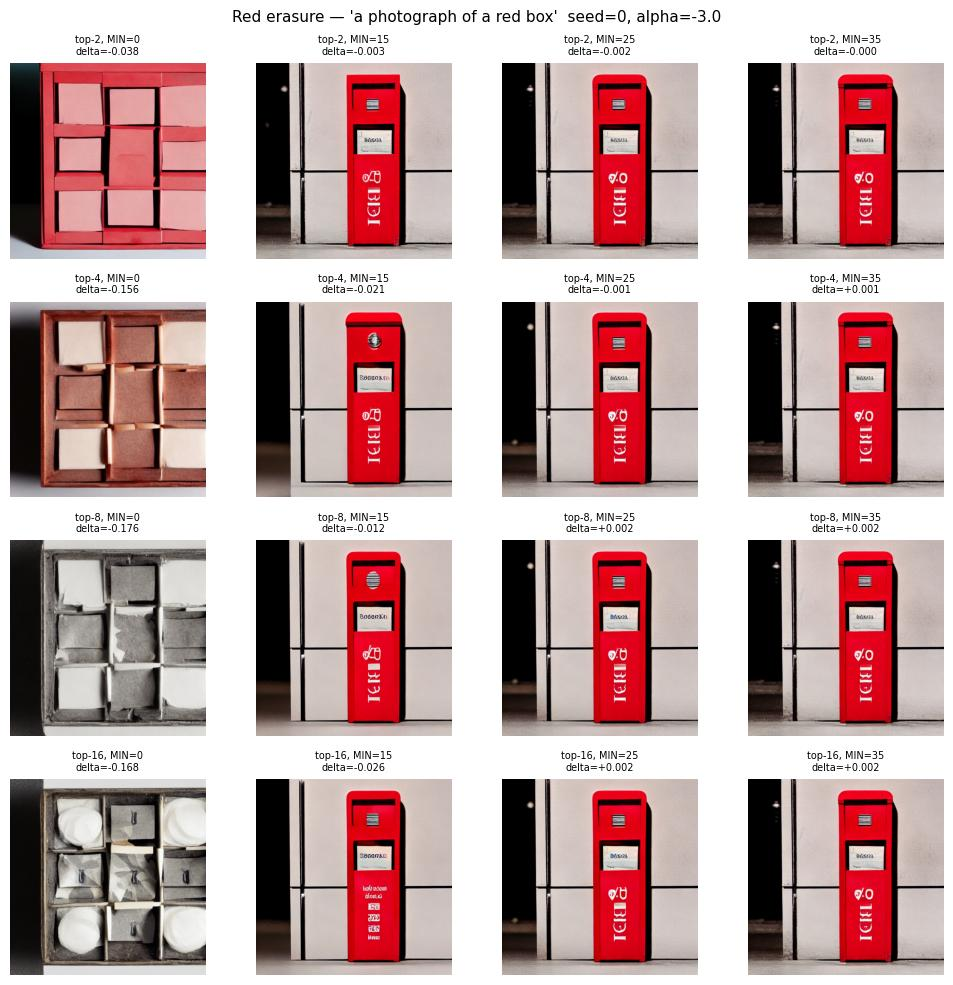


Best (layer_count, MIN_STEP) combo by most-negative mean delta:
prompt                                     top-N  MIN_STEP   mean delta   baseline
--------------------------------------------------------------------------------
a photograph of a red car                      8         0      -0.1024    +0.0527
a photograph of a red box                     16         0      -0.1771    +0.0657


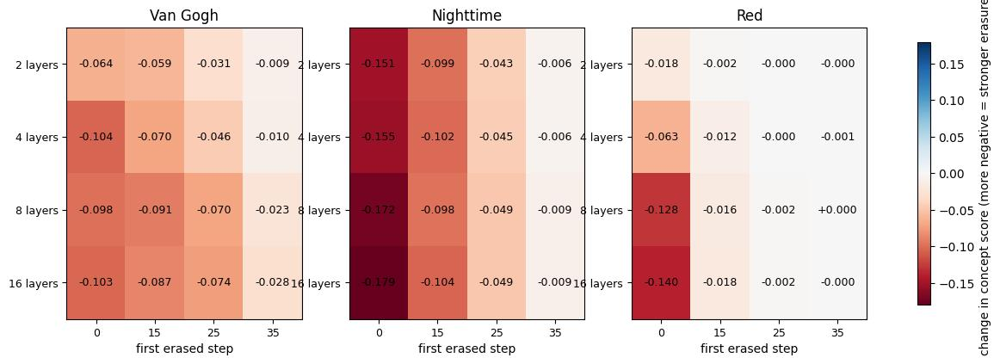


Layers x first step at alpha=-3.0, mean over 2 prompts x 3 seeds:

  Van Gogh
    layers       from 0     from 15     from 25     from 35
         2      -0.0639     -0.0589     -0.0307     -0.0087
         4      -0.1040     -0.0705     -0.0455     -0.0101
         8      -0.0982     -0.0913     -0.0704     -0.0234
        16      -0.1029     -0.0872     -0.0744     -0.0284

  Nighttime
    layers       from 0     from 15     from 25     from 35
         2      -0.1513     -0.0988     -0.0432     -0.0063
         4      -0.1549     -0.1018     -0.0446     -0.0065
         8      -0.1715     -0.0979     -0.0487     -0.0088
        16      -0.1794     -0.1043     -0.0490     -0.0093

  Red
    layers       from 0     from 15     from 25     from 35
         2      -0.0180     -0.0022     -0.0004     -0.0000
         4      -0.0625     -0.0116     -0.0003     -0.0009
         8      -0.1283     -0.0155     -0.0020     +0.0004
        16      -0.1396     -0.0181     -0.0016     -0.0004



In [ ]:
# ============================================================
# 7.2  ERASURE: LAYER COUNT x STEP WINDOW, AT ALPHA = -3, THREE CONCEPTS
#
# Needs the erasure prompts (first cell of section 6) and the cell above,
# which only define things.
#
# Saves:
#   <DRIVE_DIR>/{vg,night,red}_a3_erase_LW_results.npy / _baselines.npy
#   <DRIVE_DIR>/{vg,night,red}_a3_erase_LW_heatmaps.png
#   <DRIVE_DIR>/{vg,night,red}_a3_erase_LW_grid_p0.png, _p1.png  (seed 0)
#   <DRIVE_DIR>/fig_erase_LW_all_a3.png  <- ONE figure, the three concepts
# Cost: 3 concepts x 96 generations, ~20 min.
# ============================================================

LW_ALPHA_NEW = -3.0
lw_new = {}
for cname, prefix, matrix, dirs, scorer in [
        ("Van Gogh",  "vg_a3",    vg_matrix,    vg_dirs,    vg_score),
        ("Nighttime", "night_a3", night_matrix, night_dirs, night_score),
        ("Red",       "red_a3",   red_matrix,   red_dirs,   red_score)]:
    res, base, imgs = run_layerwindow_erasure(
        concept_name=cname, save_prefix=prefix,
        ranking_matrix=matrix, concept_dirs=dirs,
        prompts=ERASE_PROMPTS_LW[cname], scorer=scorer,
        alpha=LW_ALPHA_NEW)
    lw_new[cname] = res
    del imgs
    gc.collect()
    torch.cuda.empty_cache()

# ---- one combined heatmap figure for the thesis ----------------------------
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
bound = max(abs(r.mean(axis=(2, 3))).max() for r in lw_new.values())
for ax, (cname, res) in zip(axes, lw_new.items()):
    m = res.mean(axis=(2, 3))
    im = ax.imshow(m, aspect="auto", cmap="RdBu", vmin=-bound, vmax=bound)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m[i, j]:+.3f}", ha="center", va="center",
                    fontsize=9)
    ax.set_xticks(range(len(MIN_STEPS_ERASE)))
    ax.set_xticklabels([str(s) for s in MIN_STEPS_ERASE], fontsize=9)
    ax.set_xlabel("first erased step")
    ax.set_yticks(range(len(LAYER_COUNTS_ERASE)))
    ax.set_yticklabels([f"{n} layers" for n in LAYER_COUNTS_ERASE], fontsize=9)
    ax.set_title(cname)
fig.colorbar(im, ax=axes, label="change in concept score (more negative = stronger erasure)",
             shrink=0.9)
plt.savefig(f"{DRIVE_DIR}/fig_erase_LW_all_a3.png", dpi=150,
            bbox_inches="tight")
plt.show()

print(f"\nLayers x first step at alpha={LW_ALPHA_NEW}, mean over 2 prompts x 3 seeds:")
for cname, res in lw_new.items():
    m = res.mean(axis=(2, 3))
    print(f"\n  {cname}")
    print("    layers " + "".join(f"{'from '+str(s):>12s}" for s in MIN_STEPS_ERASE))
    for i, n in enumerate(LAYER_COUNTS_ERASE):
        print(f"    {n:>6d} " + "".join(f"{v:>+12.4f}" for v in m[i]))
print("\nLOOK at the *_a3_erase_LW_grid_p0.png images too: with 8 or 16 layers "
      "the image may break even at -3.")

## 8. Directional ablation (thesis 6.8)

8.3A (v2) — directional ablation with significance

[Van Gogh]  layer order by diff norm: [8, 6, 4, 7, 5, 15, 11, 3]
  'a van gogh painting of a cat' seed 0 done (31s)
  'a van gogh painting of a cat' seed 1 done (63s)
  'a van gogh painting of a cat' seed 2 done (94s)
  'a van gogh painting of a cat' seed 3 done (125s)
  'a van gogh painting of a house' seed 0 done (156s)
  'a van gogh painting of a house' seed 1 done (188s)
  'a van gogh painting of a house' seed 2 done (219s)
  'a van gogh painting of a house' seed 3 done (250s)

  Van Gogh: mean over 2 prompts x 4 seeds (n = 8)
     layers window         concept       p   content
          2 all steps      -0.0369   0.004   +0.0093
          2 early t<25     -0.0226   0.066   +0.0128
          2 late t>=25     -0.0059   0.066   -0.0001
          4 all steps      -0.0525   0.008   +0.0171
          4 early t<25     -0.0387   0.020   +0.0181
          4 late t>=25     -0.0112   0.012   -0.0012
          8 all steps      -0.0840   0.0

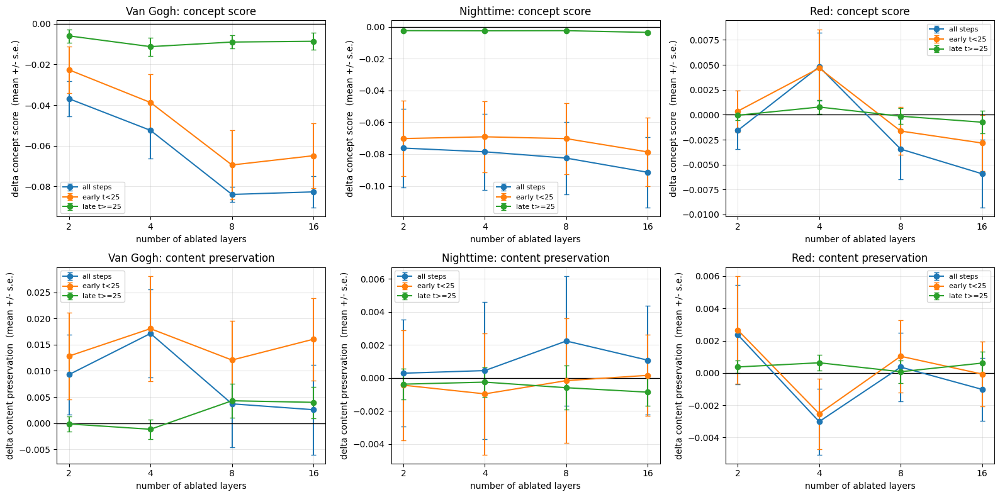


Done in 12.6 min.


In [ ]:
# ============================================================
# 8  DIRECTIONAL ABLATION, WITH SEEDS AND A SIGNIFICANCE TEST
#
# This is the thesis's strongest single result, so it gets the most care.
#
# The test: delete the component of the activation that lies along the
# concept direction,  a' = a - (a . u) u,  and see whether the concept goes
# with it. Nothing is added and no alpha needs tuning, so unlike inverse
# steering this cannot be confused with overshooting into the opposite
# concept. Content preservation is scored alongside, so an ablation that
# wrecks the image is not mistaken for erasure.
#
# Changes from v1:
#   - 4 seeds instead of 2 (8 samples per condition instead of 4).
#   - An exact sign-flip permutation test on the paired deltas. With 8
#     paired samples all 2^8 = 256 sign assignments are enumerated, so the
#     p-value is exact rather than sampled. This is the first significance
#     test in the notebook and it answers the "single-seed experiments"
#     weakness head on.
#   - A between-concept permutation test: is the Nighttime ablation effect
#     really larger than the Red one, or is that seed noise?
#
# Cost: ~290 generations, ~12 min on an A100.
# ============================================================

from itertools import product

ABL_LAYER_COUNTS = [2, 4, 8, 16]
ABL_WINDOWS = [("all steps", 0, NUM_STEPS),
               ("early t<25", 0, 25),
               ("late t>=25", 25, NUM_STEPS)]
ABL_SEEDS = [0, 1, 2, 3]
ABL_PROMPT_IDX = [0, 2]

N3_CONCEPTS = {
    "Van Gogh":  dict(dirs=vg_dirs,    matrix=vg_matrix,    scorer=vg_score),
    "Nighttime": dict(dirs=night_dirs, matrix=night_matrix, scorer=night_score),
    "Red":       dict(dirs=red_dirs,   matrix=red_matrix,   scorer=red_score),
}

CONTENT_NOUN = {
    "a van gogh painting of a cat":            "a cat",
    "a van gogh painting of a house":          "a house",
    "a photograph of a city street at night":  "a city street",
    "a photograph of a bridge at night":       "a bridge",
    "a photograph of a red car":               "a car",
    "a photograph of a red box":               "a box",
}


@torch.no_grad()
def clip_similarity(image, text):
    inputs = clip_proc(text=[text], images=[image],
                       return_tensors="pt", padding=True).to(DEVICE)
    out = clip_model(**inputs)
    i = F.normalize(out.image_embeds, dim=-1)
    t = F.normalize(out.text_embeds, dim=-1)
    return float((i @ t.T).item())


def project_out_patch(cache, dirs, layer_idxs, min_step, max_step,
                      strength=1.0):
    patch = {}
    for l_idx in layer_idxs:
        l_name = layer_names_all[l_idx]
        for t_step in range(min_step, max_step):
            key = (t_step, l_name, "out")
            a = cache[key].float()
            d = dirs[(t_step, l_name)].to(DEVICE).float()
            u = d / (d.norm() + 1e-8)
            patch[key] = (a - strength * (a * u).sum() * u).to(DTYPE)
    return patch


def signflip_p(samples, alternative="less"):
    """Exact one-sample sign-flip permutation test on paired deltas.

    H0: the sign of each delta is arbitrary. Enumerates all 2^n sign
    assignments when n <= 20, otherwise samples 20000 of them.
    """
    x = np.asarray([v for v in samples if np.isfinite(v)], dtype=np.float64)
    n = x.size
    if n == 0:
        return float("nan")
    obs = x.mean()
    if n <= 20:
        signs = np.array(list(product([1, -1], repeat=n)), dtype=np.float64)
    else:
        rng = np.random.default_rng(0)
        signs = rng.choice([1.0, -1.0], size=(20000, n))
    null = (signs * x).mean(axis=1)
    if alternative == "less":
        return float((null <= obs + 1e-12).mean())
    return float((null >= obs - 1e-12).mean())


def label_perm_p(a, b, n_perm=20000):
    """Two-sample permutation test on the difference of means."""
    a = np.asarray([v for v in a if np.isfinite(v)], dtype=np.float64)
    b = np.asarray([v for v in b if np.isfinite(v)], dtype=np.float64)
    obs = a.mean() - b.mean()
    pooled = np.concatenate([a, b])
    rng = np.random.default_rng(0)
    null = np.empty(n_perm)
    for i in range(n_perm):
        p = rng.permutation(pooled)
        null[i] = p[:a.size].mean() - p[a.size:].mean()
    return float((np.abs(null) >= abs(obs) - 1e-12).mean()), float(obs)


print("=" * 70)
print("8.3A (v2) — directional ablation with significance")
print("=" * 70)
t0 = time.time()

abl_results = {}

for cname, cfg in N3_CONCEPTS.items():
    prompts = [ERASE_PROMPTS[cname][i] for i in ABL_PROMPT_IDX]
    layer_order = [int(x) for x in np.argsort(cfg["matrix"].sum(axis=1))[::-1]]
    arr = np.zeros((len(ABL_LAYER_COUNTS), len(ABL_WINDOWS),
                    len(prompts), len(ABL_SEEDS), 2), dtype=np.float32)
    print(f"\n[{cname}]  layer order by diff norm: {layer_order[:8]}")

    for ip, prompt in enumerate(prompts):
        noun = CONTENT_NOUN.get(prompt, prompt)
        for is_, seed in enumerate(ABL_SEEDS):
            clean_img, cache = pipeline.run_and_cache(prompt, seed=seed)
            base_concept = cfg["scorer"](clean_img)
            base_content = clip_similarity(clean_img, noun)
            for ic, n_layers in enumerate(ABL_LAYER_COUNTS):
                layer_idxs = layer_order[:n_layers]
                for iw, (wname, lo, hi) in enumerate(ABL_WINDOWS):
                    patch = project_out_patch(cache, cfg["dirs"], layer_idxs,
                                              lo, hi)
                    img = pipeline.run_with_patch(patch, seed=seed,
                                                  prompt=prompt)
                    arr[ic, iw, ip, is_, 0] = cfg["scorer"](img) - base_concept
                    arr[ic, iw, ip, is_, 1] = (clip_similarity(img, noun)
                                               - base_content)
                    del patch
            del cache
            torch.cuda.empty_cache()
            print(f"  '{prompt[:36]}' seed {seed} done ({time.time()-t0:.0f}s)")

    abl_results[cname] = arr

    print(f"\n  {cname}: mean over {len(prompts)} prompts x "
          f"{len(ABL_SEEDS)} seeds (n = {len(prompts)*len(ABL_SEEDS)})")
    print(f"    {'layers':>7s} {'window':<12s} {'concept':>9s} {'p':>7s} "
          f"{'content':>9s}")
    for ic, n_layers in enumerate(ABL_LAYER_COUNTS):
        for iw, (wname, _, _) in enumerate(ABL_WINDOWS):
            conc = arr[ic, iw, :, :, 0].ravel()
            cont = arr[ic, iw, :, :, 1].ravel()
            p = signflip_p(conc, "less")
            print(f"    {n_layers:>7d} {wname:<12s} {conc.mean():>+9.4f} "
                  f"{p:>7.3f} {cont.mean():>+9.4f}")

np.save(f"{DRIVE_DIR}/new3a_v2_ablation.npy", abl_results, allow_pickle=True)

# ---- between-concept comparison, best condition per concept ----------------
print("\n" + "=" * 70)
print("Between-concept comparison (2 layers, all steps)")
print("=" * 70)
best = {c: abl_results[c][0, 0, :, :, 0].ravel() for c in N3_CONCEPTS}
names = list(N3_CONCEPTS.keys())
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        p, diff = label_perm_p(best[names[i]], best[names[j]])
        print(f"  {names[i]:<10s} vs {names[j]:<10s}: "
              f"difference {diff:+.4f}, permutation p = {p:.4f}")

print("\nThe claim to write: an ablation whose concept delta is negative with")
print("a small p AND whose content delta is ~0 shows the direction is")
print("NECESSARY. A concept delta indistinguishable from zero shows the")
print("direction is only a lever - the concept is stored elsewhere.")

# ---- plot ------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col, (cname, arr) in enumerate(abl_results.items()):
    for row, (lab, idx) in enumerate([("concept score", 0),
                                      ("content preservation", 1)]):
        ax = axes[row, col]
        for iw, (wname, _, _) in enumerate(ABL_WINDOWS):
            ys = arr[:, iw, :, :, idx].mean(axis=(1, 2))
            n = arr.shape[2] * arr.shape[3]
            es = arr[:, iw, :, :, idx].std(axis=(1, 2)) / np.sqrt(n)
            ax.errorbar(ABL_LAYER_COUNTS, ys, yerr=es, fmt="o-", capsize=3,
                        label=wname)
        ax.axhline(0, color="k", lw=1)
        ax.set_xscale("log", base=2)
        ax.set_xticks(ABL_LAYER_COUNTS)
        ax.set_xticklabels([str(c) for c in ABL_LAYER_COUNTS])
        ax.set_xlabel("number of ablated layers")
        ax.set_ylabel(f"delta {lab}  (mean +/- s.e.)")
        ax.set_title(f"{cname}: {lab}")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_new3a_v2_ablation.png", dpi=140,
            bbox_inches="tight")
plt.show()
print(f"\nDone in {(time.time()-t0)/60:.1f} min.")

## 9. Smallest set of layers (thesis 6.9)

NEW EXPERIMENT 3B (v2) — minimal sufficient set

[Van Gogh] pool (top 8 by diff norm): [8, 6, 4, 7, 5, 15, 11, 3]
  all-16-layer effect = +0.1032
  round 1: add L4  -> [4]  effect +0.0573   [45s]
  round 2: add L5  -> [4, 5]  effect +0.0689   [75s]
  round 3: add L8  -> [4, 5, 8]  effect +0.0963   [102s]
  round 4: add L11 -> [4, 5, 8, 11]  effect +0.1151   [124s]
  peak effect +0.1151 at 4 layer(s); |S*| = 4 layers [4, 5, 8, 11] (>= 90% of peak)
  all-16 / peak = 0.90   <- adding layers HURTS
  diff-norm vs single-layer steering effect: Spearman rho = +0.48 (p = 0.233, n = 8)
  strongest single layer = L4 (+0.0573); map's top layer = L8 (+0.0299)

[Nighttime] pool (top 8 by diff norm): [5, 4, 15, 6, 8, 2, 0, 7]
  all-16-layer effect = +0.0511
  round 1: add L5  -> [5]  effect +0.1195   [169s]
  round 2: add L7  -> [5, 7]  effect +0.1273   [200s]
  round 3: add L0  -> [5, 7, 0]  effect +0.1200   [227s]
  round 4: add L2  -> [5, 7, 0, 2]  effect +0.1100   [249s]
  peak effect +0.1273 at

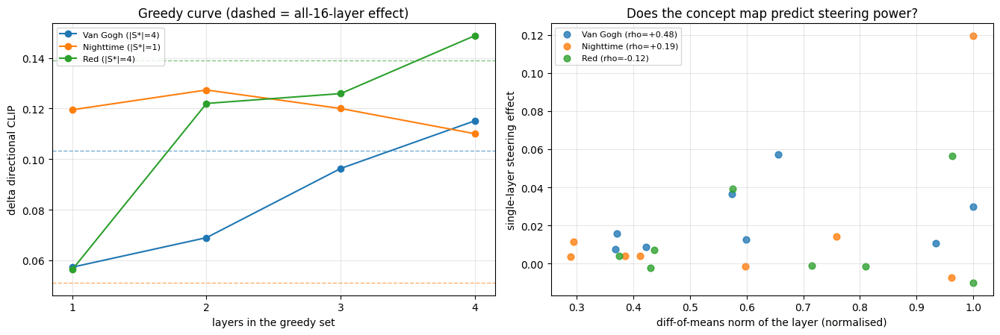


Done in 6.3 min.

SUMMARY TO QUOTE IN THE THESIS
  Van Gogh  : |S*| = 4 of 16 [4, 5, 8, 11], peak +0.1151 at 4 layers, all-layer/peak = 0.90, map-vs-effect rho = +0.48
  Nighttime : |S*| = 1 of 16 [5], peak +0.1273 at 2 layers, all-layer/peak = 0.40, map-vs-effect rho = +0.19
  Red       : |S*| = 4 of 16 [4, 11, 8, 5], peak +0.1487 at 4 layers, all-layer/peak = 0.94, map-vs-effect rho = -0.12


In [ ]:
# ============================================================
# 9  MINIMAL SUFFICIENT SET, FIXED REFERENCE
#
# What went wrong in v1: |S*| was defined as the smallest set recovering 90%
# of the ALL-16-LAYER effect. For Nighttime a single layer scored 231% of
# that, which means steering all 16 layers is WORSE than steering one - the
# layers partly cancel. An all-layer run is therefore not an upper bound and
# makes a nonsense denominator.
#
# v2 changes three things:
#   1. The reference is the PEAK of the greedy curve, not the all-layer run.
#      |S*| = smallest prefix reaching TARGET x peak.
#   2. All rounds always run - no early stop - so the curve's peak and the
#      point where adding layers starts to HURT are both visible.
#   3. Round 1 already scores every candidate layer on its own, so those
#      numbers are kept and correlated against the diff-of-means ranking.
#      That tests directly whether the concept map predicts which layers
#      actually steer - in v1 the greedy picked L4 for Van Gogh and never
#      picked L15 for Red, both of which contradict the map.
#
# Self-contained: only needs cells 2, 4, 6, 8, 10, 19.
# Cost: ~160 generations, ~7 min on an A100.
# ============================================================

from scipy.stats import spearmanr

G2_ALPHA   = 3.0
G2_WINDOW  = 25            # inject at t < G2_WINDOW
G2_SEEDS   = [0, 1]
G2_POOL    = 8             # candidate layers, ranked by diff norm
G2_ROUNDS  = 4
G2_TARGET  = 0.90
G2_PROMPT  = "a photograph of a house"

G2_CONCEPTS = {
    "Van Gogh":  (vg_dirs,    vg_matrix,    vg_score),
    "Nighttime": (night_dirs, night_matrix, night_score),
    "Red":       (red_dirs,   red_matrix,   red_score),
}

print("=" * 70)
print("NEW EXPERIMENT 3B (v2) — minimal sufficient set")
print("=" * 70)
t0 = time.time()

greedy2 = {}

for cname, (dirs, matrix, scorer) in G2_CONCEPTS.items():
    per_layer = matrix.sum(axis=1)
    pool = [int(x) for x in np.argsort(per_layer)[::-1][:G2_POOL]]

    cleans, baselines = {}, {}
    for seed in G2_SEEDS:
        img, cache = pipeline.run_and_cache(G2_PROMPT, seed=seed)
        cleans[seed] = (img, cache)
        baselines[seed] = scorer(img)

    def eval_set(layer_idxs):
        if not layer_idxs:
            return 0.0
        vals = []
        for seed in G2_SEEDS:
            _, cache = cleans[seed]
            patch = {}
            for l_idx in layer_idxs:
                l_name = layer_names_all[l_idx]
                for t_step in range(min(G2_WINDOW, NUM_STEPS)):
                    key = (t_step, l_name, "out")
                    patch[key] = (cache[key].float()
                                  + G2_ALPHA
                                  * dirs[(t_step, l_name)].to(DEVICE)).to(DTYPE)
            img = pipeline.run_with_patch(patch, seed=seed, prompt=G2_PROMPT)
            vals.append(scorer(img) - baselines[seed])
        return float(np.mean(vals))

    full = eval_set(list(range(N_LAYERS)))
    print(f"\n[{cname}] pool (top {G2_POOL} by diff norm): {pool}")
    print(f"  all-{N_LAYERS}-layer effect = {full:+.4f}")

    # ---- greedy, no early stop --------------------------------------------
    singles = {}
    chosen, curve, remaining = [], [], list(pool)
    for rnd in range(min(G2_ROUNDS, len(pool))):
        scored = []
        for l in remaining:
            v = eval_set(chosen + [l])
            scored.append((v, l))
            if rnd == 0:
                singles[l] = v
        best_val, best_layer = max(scored)
        chosen.append(best_layer)
        remaining.remove(best_layer)
        curve.append((list(chosen), best_val))
        print(f"  round {rnd+1}: add L{best_layer:<2d} -> {chosen}  "
              f"effect {best_val:+.4f}   [{time.time()-t0:.0f}s]")

    vals = [v for _, v in curve]
    peak = max(vals)
    peak_k = int(np.argmax(vals)) + 1
    target = G2_TARGET * peak
    s_star_k = next(i + 1 for i, v in enumerate(vals) if v >= target)
    s_star = curve[s_star_k - 1][0]
    interference = full / peak if abs(peak) > 1e-9 else float("nan")

    # ---- does the diff-norm map predict single-layer steering power? -------
    pool_norms = [float(per_layer[l]) for l in pool]
    pool_effect = [singles[l] for l in pool]
    rho, pval = spearmanr(pool_norms, pool_effect)

    greedy2[cname] = dict(pool=pool, full=full, curve=curve, peak=peak,
                          peak_k=peak_k, s_star=s_star, s_star_k=s_star_k,
                          interference=interference, singles=singles,
                          spearman=float(rho), pvalue=float(pval))

    print(f"  peak effect {peak:+.4f} at {peak_k} layer(s); "
          f"|S*| = {s_star_k} layers {s_star} "
          f"(>= {G2_TARGET:.0%} of peak)")
    print(f"  all-{N_LAYERS} / peak = {interference:.2f}"
          + ("   <- adding layers HURTS" if interference < 0.95 else ""))
    print(f"  diff-norm vs single-layer steering effect: "
          f"Spearman rho = {rho:+.2f} (p = {pval:.3f}, n = {len(pool)})")
    best_single = max(singles, key=singles.get)
    print(f"  strongest single layer = L{best_single} "
          f"({singles[best_single]:+.4f}); "
          f"map's top layer = L{pool[0]} ({singles[pool[0]]:+.4f})")

    del cleans
    torch.cuda.empty_cache()

np.save(f"{DRIVE_DIR}/new3bv2_minimal_sets.npy", greedy2, allow_pickle=True)

# ---- plots -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

ax = axes[0]
for cname, out in greedy2.items():
    xs = list(range(1, len(out["curve"]) + 1))
    ys = [v for _, v in out["curve"]]
    line, = ax.plot(xs, ys, "o-", label=f"{cname} (|S*|={out['s_star_k']})")
    ax.axhline(out["full"], ls="--", lw=1, alpha=0.6, color=line.get_color())
ax.set_xlabel("layers in the greedy set")
ax.set_ylabel("delta directional CLIP")
ax.set_title("Greedy curve (dashed = all-16-layer effect)")
ax.set_xticks(range(1, G2_ROUNDS + 1))
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
for cname, out in greedy2.items():
    norms = [float(G2_CONCEPTS[cname][1].sum(axis=1)[l]) for l in out["pool"]]
    effs = [out["singles"][l] for l in out["pool"]]
    norms = np.array(norms) / (max(norms) + 1e-9)
    ax.scatter(norms, effs, s=40, alpha=0.8,
               label=f"{cname} (rho={out['spearman']:+.2f})")
ax.set_xlabel("diff-of-means norm of the layer (normalised)")
ax.set_ylabel("single-layer steering effect")
ax.set_title("Does the concept map predict steering power?")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_new3bv2_minimal_set.png", dpi=140,
            bbox_inches="tight")
plt.show()

print(f"\nDone in {(time.time()-t0)/60:.1f} min.")
print("\nSUMMARY TO QUOTE IN THE THESIS")
for cname, out in greedy2.items():
    print(f"  {cname:<10s}: |S*| = {out['s_star_k']} of {N_LAYERS} "
          f"{out['s_star']}, peak {out['peak']:+.4f} at {out['peak_k']} "
          f"layers, all-layer/peak = {out['interference']:.2f}, "
          f"map-vs-effect rho = {out['spearman']:+.2f}")

## 10. Two concepts together (thesis 6.10)

NEW EXPERIMENT 1 — composition and linearity
  prompt = 'a photograph of a house'
  layers per concept: Van Gogh=[8, 6], Nighttime=[5, 4], Red=[15, 4]
  seed 0 done (111s)
  seed 1 done (221s)
  seed 2 done (332s)

[crosstalk] rows = steered concept, cols = measured concept (alpha=2.0)
  Van Gogh   -> Van G:+0.0887  Night:+0.0297  Red:+0.0082
  Nighttime  -> Van G:+0.0350  Night:+0.1537  Red:+0.0538
  Red        -> Van G:+0.0227  Night:+0.0050  Red:+0.0593
  mean |diagonal| = 0.1006   mean |off-diagonal| = 0.0257   ratio = 0.26

[pairs] solo vs joint effect (mean over seeds)
  vg     x night   solo A=+0.1210  solo B=+0.1231  joint A=+0.1228  joint B=+0.0727
  vg     x red     solo A=+0.1210  solo B=+0.0594  joint A=+0.1148  joint B=+0.0284
  night  x red     solo A=+0.1231  solo B=+0.0594  joint A=+0.0982  joint B=+0.0119

[additivity] slope(measured ~ predicted) = 0.726, R^2 against y=x = 0.465  (n=90)
  slope ~ 1 and high R^2 => composition is linear in this regime;
  slope < 1 => th

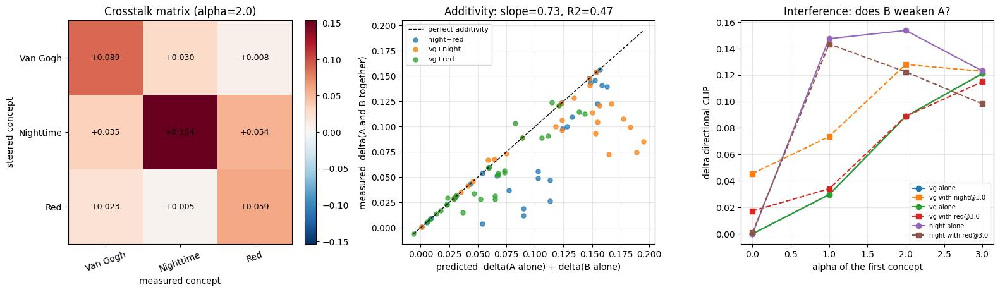

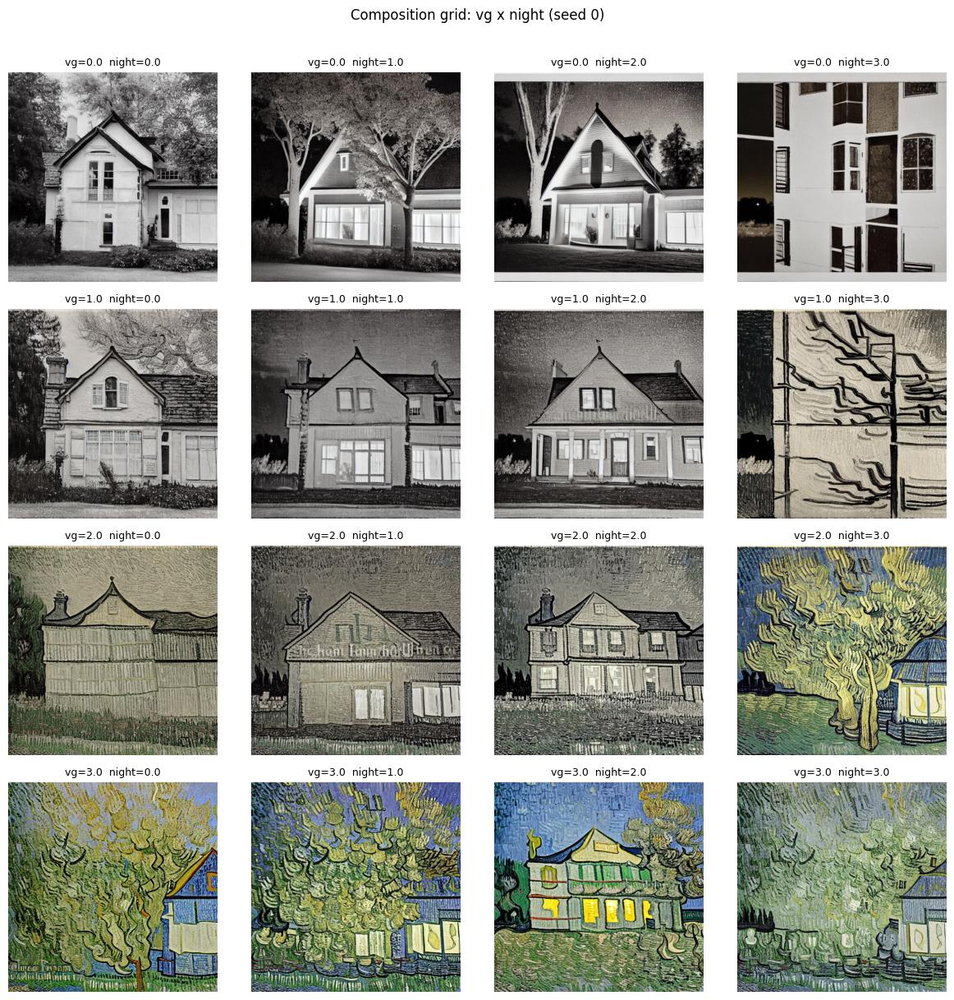


Done in 5.6 min. Saved crosstalk + pair grids to Drive.


In [ ]:
# ============================================================
# 10  CONCEPT COMPOSITION AND LINEARITY
#
# Every result so far uses ONE direction at a time. That establishes each
# direction is causal, but says nothing about the structure of the space
# they live in. This cell asks three questions:
#
#   A. CROSSTALK. Steering with direction A at a fixed alpha, how much do
#      the scores of concepts B and C move? A near-diagonal matrix means
#      the three directions are close to orthogonal in effect.
#
#   B. INTERFERENCE. Does concept A still land when B is applied at the
#      same time? For each pair we sweep a 3x3 grid of (alpha_A, alpha_B)
#      and read both scores off every image.
#
#   C. ADDITIVITY. Is  delta_A(alpha_A, alpha_B)  equal to
#      delta_A(alpha_A, 0) + delta_A(0, alpha_B)? If the scatter of
#      measured vs predicted lies on y = x, concept space behaves linearly
#      under composition and the "directions are coordinates" reading of
#      the whole thesis is justified. If it saturates, the linear picture
#      only holds locally.
#
# Design notes:
#   - Steering uses each concept's OWN top-2 layers (from section 4), all
#     50 steps, so the intervention sets overlap only where two concepts
#     happen to share a layer. Overlaps are summed, not overwritten.
#   - One neutral prompt that all three concepts can plausibly modify.
#   - Alphas stay inside each concept's usable range: at alpha 4 a single
#     concept already collapses the image into texture, so any measured
#     sub-additivity there is saturation, not competition.
#   - 3 seeds; every delta is relative to that seed's own clean image.
#   - The loop is seed-outer so only ONE activation cache is resident at a
#     time (a full cache is ~2 GB of GPU memory).
#
# Cost: ~130 generations, ~6 min on an A100.
# ============================================================

N1_PROMPT   = "a photograph of a house"
ALPHAS_N1   = [0.0, 1.0, 2.0, 3.0]
ALPHA_XTALK = 2.0
SEEDS_N1    = [0, 1, 2]

N1_CONCEPTS = {
    "vg":    dict(name="Van Gogh",  dirs=vg_dirs,
                  layers=vg_top_layers,    scorer=vg_score),
    "night": dict(name="Nighttime", dirs=night_dirs,
                  layers=night_top_layers, scorer=night_score),
    "red":   dict(name="Red",       dirs=red_dirs,
                  layers=red_top_layers,   scorer=red_score),
}
N1_KEYS = list(N1_CONCEPTS.keys())
PAIRS_N1 = [("vg", "night"), ("vg", "red"), ("night", "red")]


def build_composite_patch(clean_cache, specs):
    """Sum several steered directions into one patch dict.

    specs : list of (dirs, layer_idxs, alpha). Cells touched by more than
            one concept accumulate both contributions, which is exactly the
            composition we want to test.
    """
    acc = {}
    for dirs, layer_idxs, alpha in specs:
        if alpha == 0.0:
            continue
        for l_idx in layer_idxs:
            l_name = layer_names_all[l_idx]
            for t_step in range(NUM_STEPS):
                key = (t_step, l_name, "out")
                if key not in acc:
                    acc[key] = clean_cache[key].float()
                acc[key] = acc[key] + alpha * dirs[(t_step, l_name)].to(DEVICE)
    return {k: v.to(DTYPE) for k, v in acc.items()}


def run_composite(clean_img, clean_cache, specs, seed):
    """Generate one image under a (possibly multi-concept) steering spec."""
    patch = build_composite_patch(clean_cache, specs)
    if not patch:
        return clean_img
    return pipeline.run_with_patch(patch, seed=seed, prompt=N1_PROMPT)


print("=" * 70)
print("NEW EXPERIMENT 1 — composition and linearity")
print("=" * 70)
print(f"  prompt = '{N1_PROMPT}'")
print("  layers per concept: " + ", ".join(
    f"{N1_CONCEPTS[k]['name']}={N1_CONCEPTS[k]['layers']}" for k in N1_KEYS))

t0 = time.time()

# results[(seed)] filled in the seed-outer loop below
xtalk_raw = np.zeros((len(SEEDS_N1), len(N1_KEYS), len(N1_KEYS)),
                     dtype=np.float32)
pair_raw = {p: np.zeros((len(ALPHAS_N1), len(ALPHAS_N1), len(SEEDS_N1), 2),
                        dtype=np.float32) for p in PAIRS_N1}
pair_images = {p: {} for p in PAIRS_N1}

for is_, seed in enumerate(SEEDS_N1):
    clean_img, clean_cache = pipeline.run_and_cache(N1_PROMPT, seed=seed)
    base = {k: N1_CONCEPTS[k]["scorer"](clean_img) for k in N1_KEYS}

    # ---- Part A: crosstalk ------------------------------------------------
    for i, steered in enumerate(N1_KEYS):
        c = N1_CONCEPTS[steered]
        img = run_composite(clean_img, clean_cache,
                            [(c["dirs"], c["layers"], ALPHA_XTALK)], seed)
        for j, measured in enumerate(N1_KEYS):
            xtalk_raw[is_, i, j] = (N1_CONCEPTS[measured]["scorer"](img)
                                    - base[measured])

    # ---- Part B: pairwise grids -------------------------------------------
    for a_key, b_key in PAIRS_N1:
        ca, cb = N1_CONCEPTS[a_key], N1_CONCEPTS[b_key]
        for ia, alpha_a in enumerate(ALPHAS_N1):
            for ib, alpha_b in enumerate(ALPHAS_N1):
                img = run_composite(
                    clean_img, clean_cache,
                    [(ca["dirs"], ca["layers"], alpha_a),
                     (cb["dirs"], cb["layers"], alpha_b)], seed)
                pair_raw[(a_key, b_key)][ia, ib, is_, 0] = (
                    ca["scorer"](img) - base[a_key])
                pair_raw[(a_key, b_key)][ia, ib, is_, 1] = (
                    cb["scorer"](img) - base[b_key])
                if seed == SEEDS_N1[0]:
                    pair_images[(a_key, b_key)][(alpha_a, alpha_b)] = img

    del clean_cache
    torch.cuda.empty_cache()
    print(f"  seed {seed} done ({time.time()-t0:.0f}s)")

xtalk = xtalk_raw.mean(axis=0)

print("\n[crosstalk] rows = steered concept, cols = measured concept "
      f"(alpha={ALPHA_XTALK})")
for i, steered in enumerate(N1_KEYS):
    print(f"  {N1_CONCEPTS[steered]['name']:<10s} -> " + "  ".join(
        f"{N1_CONCEPTS[m]['name'][:5]}:{xtalk[i, j]:+.4f}"
        for j, m in enumerate(N1_KEYS)))
diag = float(np.mean(np.abs(np.diag(xtalk))))
off = float((np.abs(xtalk).sum() - np.abs(np.diag(xtalk)).sum())
            / (xtalk.size - len(N1_KEYS)))
print(f"  mean |diagonal| = {diag:.4f}   mean |off-diagonal| = {off:.4f}   "
      f"ratio = {off / (diag + 1e-9):.2f}")

print("\n[pairs] solo vs joint effect (mean over seeds)")
for (a_key, b_key), arr in pair_raw.items():
    m = arr.mean(axis=2)
    print(f"  {a_key:<6s} x {b_key:<6s}  solo A={m[-1, 0, 0]:+.4f}  "
          f"solo B={m[0, -1, 1]:+.4f}  joint A={m[-1, -1, 0]:+.4f}  "
          f"joint B={m[-1, -1, 1]:+.4f}")

# ============================================================
# PART C — additivity
# ============================================================
pred, meas, labels = [], [], []
for (a_key, b_key), arr in pair_raw.items():
    m = arr.mean(axis=2)                       # (alphas, alphas, 2)
    for ia, alpha_a in enumerate(ALPHAS_N1):
        for ib, alpha_b in enumerate(ALPHAS_N1):
            if alpha_a == 0.0 and alpha_b == 0.0:
                continue
            for which in (0, 1):
                pred.append(m[ia, 0, which] + m[0, ib, which])
                meas.append(m[ia, ib, which])
                labels.append(f"{a_key}+{b_key}")
pred = np.array(pred)
meas = np.array(meas)
slope = float(np.polyfit(pred, meas, 1)[0])
ss_res = float(((meas - pred) ** 2).sum())
ss_tot = float(((meas - meas.mean()) ** 2).sum())
r2_identity = 1.0 - ss_res / (ss_tot + 1e-12)

print(f"\n[additivity] slope(measured ~ predicted) = {slope:.3f}, "
      f"R^2 against y=x = {r2_identity:.3f}  (n={len(pred)})")
print("  slope ~ 1 and high R^2 => composition is linear in this regime;")
print("  slope < 1 => the concepts saturate or compete when combined.")

# ============================================================
# Plots
# ============================================================
fig = plt.figure(figsize=(16, 4.6))

ax = fig.add_subplot(1, 3, 1)
im = ax.imshow(xtalk, cmap="RdBu_r",
               vmin=-np.abs(xtalk).max(), vmax=np.abs(xtalk).max())
ax.set_xticks(range(len(N1_KEYS)))
ax.set_xticklabels([N1_CONCEPTS[k]["name"] for k in N1_KEYS], rotation=20)
ax.set_yticks(range(len(N1_KEYS)))
ax.set_yticklabels([N1_CONCEPTS[k]["name"] for k in N1_KEYS])
ax.set_xlabel("measured concept")
ax.set_ylabel("steered concept")
ax.set_title(f"Crosstalk matrix (alpha={ALPHA_XTALK})")
for i in range(len(N1_KEYS)):
    for j in range(len(N1_KEYS)):
        ax.text(j, i, f"{xtalk[i, j]:+.3f}", ha="center", va="center",
                fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)

ax = fig.add_subplot(1, 3, 2)
lims = [float(min(pred.min(), meas.min())), float(max(pred.max(), meas.max()))]
ax.plot(lims, lims, "k--", lw=1, label="perfect additivity")
for lab in sorted(set(labels)):
    sel = [i for i, l in enumerate(labels) if l == lab]
    ax.scatter(pred[sel], meas[sel], s=26, alpha=0.75, label=lab)
ax.set_xlabel("predicted  delta(A alone) + delta(B alone)")
ax.set_ylabel("measured  delta(A and B together)")
ax.set_title(f"Additivity: slope={slope:.2f}, R2={r2_identity:.2f}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = fig.add_subplot(1, 3, 3)
for (a_key, b_key), arr in pair_raw.items():
    m = arr.mean(axis=2)
    solo = [m[ia, 0, 0] for ia in range(len(ALPHAS_N1))]
    withb = [m[ia, -1, 0] for ia in range(len(ALPHAS_N1))]
    ax.plot(ALPHAS_N1, solo, "o-", label=f"{a_key} alone")
    ax.plot(ALPHAS_N1, withb, "s--",
            label=f"{a_key} with {b_key}@{ALPHAS_N1[-1]}")
ax.set_xlabel("alpha of the first concept")
ax.set_ylabel("delta directional CLIP")
ax.set_title("Interference: does B weaken A?")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_new1_composition.png", dpi=140,
            bbox_inches="tight")
plt.show()

# --- image grid for one pair, first seed ------------------------------------
show_pair = PAIRS_N1[0]
imgs = pair_images[show_pair]
fig, axes = plt.subplots(len(ALPHAS_N1), len(ALPHAS_N1),
                         figsize=(3 * len(ALPHAS_N1), 3 * len(ALPHAS_N1)))
for ia, alpha_a in enumerate(ALPHAS_N1):
    for ib, alpha_b in enumerate(ALPHAS_N1):
        ax = axes[ia, ib]
        ax.imshow(imgs[(alpha_a, alpha_b)])
        ax.set_title(f"{show_pair[0]}={alpha_a}  {show_pair[1]}={alpha_b}",
                     fontsize=9)
        ax.axis("off")
plt.suptitle(f"Composition grid: {show_pair[0]} x {show_pair[1]} "
             f"(seed {SEEDS_N1[0]})", y=1.01)
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/fig_new1_grid_{show_pair[0]}_{show_pair[1]}.png",
            dpi=130, bbox_inches="tight")
plt.show()

np.save(f"{DRIVE_DIR}/new1_crosstalk.npy", xtalk)
np.save(f"{DRIVE_DIR}/new1_pairs.npy",
        {f"{a}+{b}": v for (a, b), v in pair_raw.items()}, allow_pickle=True)
print(f"\nDone in {(time.time()-t0)/60:.1f} min. "
      f"Saved crosstalk + pair grids to Drive.")

## 11. Attacks on the erasure (thesis 6.11)

Paraphrase of the prompt, and the direction added back at other layers.

In [ ]:
# ============================================================
# 11.1  ATTACKS ON THE ERASURE, ALPHA = -3, TWO BEST LAYERS
#
# The erasure is applied at alpha = -3 (a larger strength destroys the image,
# so an attack could not be judged). Five conditions per prompt and seed; the
# "paraphrase" condition (no erasure) shows whether the paraphrase produces
# the concept at all.
#
# Conditions:  base | erased | paraphrase | paraphrase+erased | erased+routing
#
# Saves: <DRIVE_DIR>/erasure_attacks_a3.npy
#        <DRIVE_DIR>/attacks_rerun/attacks_seed<k>.jpg  (labelled grids)
# Cost: 3 concepts x 2 prompts x 3 seeds x 5 = 90 generations, ~6 min.
# ============================================================

RAB2_ALPHA_ERASE  = -3.0
RAB2_ALPHA_ATTACK = 3.0
RAB2_SEEDS = [0, 1, 2]
RAB2_DIR = f"{DRIVE_DIR}/attacks_rerun"
os.makedirs(RAB2_DIR, exist_ok=True)

RAB2_SPECS = {
    "Van Gogh": dict(
        dirs=vg_dirs, layers=vg_top_layers, scorer=vg_score, matrix=vg_matrix,
        literal=["a van gogh painting of a cat",
                 "a van gogh painting of a house"],
        paraphrase=[
            "a painting of a cat with thick swirling impasto brushstrokes "
            "in cobalt blue and chrome yellow",
            "a painting of a house with restless spiralling strokes and "
            "heavy ridges of yellow and blue oil paint"]),
    "Nighttime": dict(
        dirs=night_dirs, layers=night_top_layers, scorer=night_score,
        matrix=night_matrix,
        literal=["a photograph of a city street at night",
                 "a photograph of a bridge at night"],
        paraphrase=[
            "a photograph of a city street lit only by street lamps under a "
            "black sky",
            "a photograph of a bridge under a moonless sky with lit windows "
            "in the distance"]),
    "Red": dict(
        dirs=red_dirs, layers=red_top_layers, scorer=red_score,
        matrix=red_matrix,
        literal=["a photograph of a red car",
                 "a photograph of a red box"],
        paraphrase=[
            "a photograph of a crimson scarlet car the colour of fresh blood",
            "a photograph of a box in a deep vermilion shade like a ripe "
            "tomato"]),
}
CONDS2 = ["base", "erased", "paraphrase", "paraphrase+erased", "routing"]
COL2 = ["Original prompt", "Erased", "Paraphrase", "Paraphrase + erased",
        "Erased + re-injected"]


def gen2(prompt, seed, dirs, erase_layers, erase=True, attack_layers=None):
    clean, cache = pipeline.run_and_cache(prompt, seed=seed)
    if not erase and not attack_layers:
        del cache
        torch.cuda.empty_cache()
        return clean
    patch = steer_patch(cache, dirs, erase_layers, RAB2_ALPHA_ERASE) if erase else {}
    for l_idx in (attack_layers or []):
        l_name = layer_names_all[l_idx]
        for t_step in range(NUM_STEPS):
            key = (t_step, l_name, "out")
            b = patch.get(key, cache[key]).float()
            patch[key] = (b + RAB2_ALPHA_ATTACK
                          * dirs[(t_step, l_name)].to(DEVICE)).to(DTYPE)
    img = pipeline.run_with_patch(patch, seed=seed, prompt=prompt)
    del cache, patch
    torch.cuda.empty_cache()
    return img


t0 = time.time()
rab2 = {c: np.full((len(CONDS2), 2, len(RAB2_SEEDS)), np.nan, np.float32)
        for c in RAB2_SPECS}
rab2_imgs = {}

for cname, sp in RAB2_SPECS.items():
    er = list(sp["layers"])
    ranked = [int(x) for x in np.argsort(sp["matrix"].sum(axis=1))[::-1]]
    att = [l for l in ranked if l not in er][:len(er)]
    print(f"[{cname}] erased layers {er}, attack re-injects at {att}")
    for p in range(2):
        lit, par = sp["literal"][p], sp["paraphrase"][p]
        for i_s, seed in enumerate(RAB2_SEEDS):
            imgs = {
                "base":              gen2(lit, seed, sp["dirs"], er, erase=False),
                "erased":            gen2(lit, seed, sp["dirs"], er),
                "paraphrase":        gen2(par, seed, sp["dirs"], er, erase=False),
                "paraphrase+erased": gen2(par, seed, sp["dirs"], er),
                "routing":           gen2(lit, seed, sp["dirs"], er,
                                          attack_layers=att),
            }
            for ic, c in enumerate(CONDS2):
                rab2[cname][ic, p, i_s] = sp["scorer"](imgs[c])
            if p == 0:
                rab2_imgs[(cname, seed)] = imgs
    print(f"  done ({time.time()-t0:.0f}s)")

np.save(f"{RAB2_DIR}/erasure_attacks_a3.npy", rab2, allow_pickle=True)

# ---- labelled grid per seed (first prompt of each concept) -----------------
for seed in RAB2_SEEDS:
    rows, caps = [], []
    for cname in RAB2_SPECS:
        imgs = rab2_imgs[(cname, seed)]
        base = RAB2_SPECS[cname]["scorer"](imgs["base"])
        rows.append([imgs[c] for c in CONDS2])
        caps.append([""] + [f"Δ = {RAB2_SPECS[cname]['scorer'](imgs[c]) - base:+.3f}"
                            for c in CONDS2[1:]])
    labeled_grid(rows, COL2,
                 list(RAB2_SPECS), captions=caps, size=300, fs=24,
                 left=200).save(f"{RAB2_DIR}/attacks_seed{seed}.jpg", quality=90)

# ---- table ------------------------------------------------------------------
print(f"\nAttacks at erase alpha={RAB2_ALPHA_ERASE}, mean concept score "
      f"(2 prompts x 3 seeds); recovery = share of the erased amount that "
      f"comes back")
print(f"  {'concept':<10s}" + "".join(f"{c:>19s}" for c in CONDS2))
for cname in RAB2_SPECS:
    m = np.nanmean(rab2[cname], axis=(1, 2))
    span = m[0] - m[1]
    print(f"  {cname:<10s}" + "".join(f"{v:>+19.4f}" for v in m))
    rec_par = (m[3] - m[1]) / span if abs(span) > 1e-9 else np.nan
    rec_rt  = (m[4] - m[1]) / span if abs(span) > 1e-9 else np.nan
    note = "   (erasure itself is small, recovery is unreliable)" if span < 0.03 else ""
    print(f"  {'':<10s} erased by {span:+.4f}; paraphrase+erased recovers "
          f"{rec_par:.0%}, routing recovers {rec_rt:.0%}{note}")
print(f"\nImages: {RAB2_DIR}/attacks_seed0.jpg .. attacks_seed2.jpg   "
      f"({(time.time()-t0)/60:.1f} min)")

[Van Gogh] erased layers [8, 6], attack re-injects at [4, 7]
  done (107s)
[Nighttime] erased layers [5, 4], attack re-injects at [15, 6]
  done (214s)
[Red] erased layers [15, 4], attack re-injects at [5, 6]
  done (320s)

Attacks at erase alpha=-3.0, mean concept score (2 prompts x 3 seeds); recovery = share of the erased amount that comes back
  concept                  base             erased         paraphrase  paraphrase+erased            routing
  Van Gogh              +0.0743            +0.0104            -0.0078            -0.0307            -0.0328
             erased by +0.0639; paraphrase+erased recovers -64%, routing recovers -68%
  Nighttime             +0.0504            -0.1010            +0.0575            -0.0732            -0.0839
             erased by +0.1513; paraphrase+erased recovers 18%, routing recovers 11%
  Red                   +0.0592            +0.0412            +0.0579            +0.0166            +0.0418
             erased by +0.0180; paraphrase+eras

In [60]:
# ============================================================
# 11.2  ATTACKS ON THE RED ERASURE WITH 8 LAYERS, ALPHA = -3
#
# With the two best layers red is barely erased at alpha = -3, so there is
# nothing for an attack to bring back. Section 7 shows that with the top-8
# layers red is erased at -3 and the image stays intact. Same
# attacks, red only, erasure on the top-8 layers; the routing attack
# re-injects the direction at the 8 layers that are left open.
#
# Saves: <DRIVE_DIR>/attacks_rerun/erasure_attacks_red8_a3.npy
#        <DRIVE_DIR>/attacks_rerun/attacks_red8_seed<k>.jpg
# Needs the cell above (prompts and helper). Cost: 2 prompts x 3 seeds x 5 = 30 generations, ~2 min.
# ============================================================

sp = RAB2_SPECS["Red"]
ranked = [int(x) for x in np.argsort(sp["matrix"].sum(axis=1))[::-1]]
er8, att8 = ranked[:8], ranked[8:]
print(f"[Red] erased layers {er8}, attack re-injects at {att8}")

t0 = time.time()
rab_red8 = np.full((len(CONDS2), 2, len(RAB2_SEEDS)), np.nan, np.float32)
red8_imgs = {}
for p in range(2):
    lit, par = sp["literal"][p], sp["paraphrase"][p]
    for i_s, seed in enumerate(RAB2_SEEDS):
        imgs = {
            "base":              gen2(lit, seed, sp["dirs"], er8, erase=False),
            "erased":            gen2(lit, seed, sp["dirs"], er8),
            "paraphrase":        gen2(par, seed, sp["dirs"], er8, erase=False),
            "paraphrase+erased": gen2(par, seed, sp["dirs"], er8),
            "routing":           gen2(lit, seed, sp["dirs"], er8,
                                      attack_layers=att8),
        }
        for ic, c in enumerate(CONDS2):
            rab_red8[ic, p, i_s] = sp["scorer"](imgs[c])
        red8_imgs[(p, seed)] = imgs
np.save(f"{RAB2_DIR}/erasure_attacks_red8_a3.npy", rab_red8)

for seed in RAB2_SEEDS:
    rows, caps = [], []
    for p in range(2):
        imgs = red8_imgs[(p, seed)]
        base = sp["scorer"](imgs["base"])
        rows.append([imgs[c] for c in CONDS2])
        caps.append([""] + [f"Δ = {sp['scorer'](imgs[c]) - base:+.3f}"
                            for c in CONDS2[1:]])
    labeled_grid(rows, COL2, ["Red: car", "Red: box"], captions=caps,
                 size=300, fs=24, left=200).save(
        f"{RAB2_DIR}/attacks_red8_seed{seed}.jpg", quality=90)

m = np.nanmean(rab_red8, axis=(1, 2))
span = m[0] - m[1]
print(f"\nRed, 8 erased layers, alpha={RAB2_ALPHA_ERASE}:")
print("  " + "".join(f"{c:>19s}" for c in CONDS2))
print("  " + "".join(f"{v:>+19.4f}" for v in m))
print(f"  erased by {span:+.4f}; paraphrase+erased recovers "
      f"{(m[3]-m[1])/span:.0%}, routing recovers {(m[4]-m[1])/span:.0%}")
print(f"\nImages: {RAB2_DIR}/attacks_red8_seed0.jpg .. seed2.jpg  "
      f"({(time.time()-t0)/60:.1f} min)")

[Red] erased layers [15, 4, 5, 6, 8, 11, 7, 0], attack re-injects at [2, 10, 12, 13, 1, 14, 3, 9]

Red, 8 erased layers, alpha=-3.0:
                 base             erased         paraphrase  paraphrase+erased            routing
              +0.0592            -0.0691            +0.0579            -0.0453            -0.0610
  erased by +0.1283; paraphrase+erased recovers 19%, routing recovers 6%

Images: /content/drive/MyDrive/thesis_public_run/attacks_rerun/attacks_red8_seed0.jpg .. seed2.jpg  (1.9 min)


In [ ]:
# ============================================================
# 11.3  ATTACKS ON THE VAN GOGH ERASURE, MILDER STRENGTHS, 6 SEEDS
#
# With erase -3 and attack +3 the Van Gogh images under attack turned into
# texture, so nothing could be read from them. Here: erasure at alpha = -2
# (where the Van Gogh erasure is already full) and the routing
# attack at +1.5, six seeds, so a seed with clean images can be chosen.
# Needs only sections 0 and 1. Result: almost every attacked
# image breaks down, so this is not counted as a result in the thesis.
#
# Saves: <DRIVE_DIR>/attacks_rerun/erasure_attacks_vg_mild.npy
#        <DRIVE_DIR>/attacks_rerun/attacks_vg_mild_seed<k>.jpg
# Cost: 2 prompts x 6 seeds x 5 = 60 generations, ~3 min.
# ============================================================

VGM_ALPHA_ERASE  = -2.0
VGM_ALPHA_ATTACK = 1.5
VGM_SEEDS = [0, 1, 2, 3, 4, 5]
VGM_DIR = f"{DRIVE_DIR}/attacks_rerun"
os.makedirs(VGM_DIR, exist_ok=True)

VGM_LIT = ["a van gogh painting of a cat", "a van gogh painting of a house"]
VGM_PAR = ["a painting of a cat with thick swirling impasto brushstrokes "
           "in cobalt blue and chrome yellow",
           "a painting of a house with restless spiralling strokes and "
           "heavy ridges of yellow and blue oil paint"]
VGM_CONDS = ["base", "erased", "paraphrase", "paraphrase+erased", "routing"]
VGM_COLS = ["Original prompt", "Erased", "Paraphrase", "Paraphrase + erased",
            "Erased + re-injected"]

er = list(vg_top_layers)
ranked = [int(x) for x in np.argsort(vg_matrix.sum(axis=1))[::-1]]
att = [l for l in ranked if l not in er][:len(er)]
print(f"[Van Gogh] erased layers {er} at {VGM_ALPHA_ERASE}, "
      f"attack re-injects at {att} with {VGM_ALPHA_ATTACK}")


def gen_vgm(prompt, seed, erase=True, attack=False):
    clean, cache = pipeline.run_and_cache(prompt, seed=seed)
    if not erase and not attack:
        del cache
        torch.cuda.empty_cache()
        return clean
    patch = steer_patch(cache, vg_dirs, er, VGM_ALPHA_ERASE) if erase else {}
    if attack:
        for l_idx in att:
            l_name = layer_names_all[l_idx]
            for t_step in range(NUM_STEPS):
                key = (t_step, l_name, "out")
                b = patch.get(key, cache[key]).float()
                patch[key] = (b + VGM_ALPHA_ATTACK
                              * vg_dirs[(t_step, l_name)].to(DEVICE)).to(DTYPE)
    img = pipeline.run_with_patch(patch, seed=seed, prompt=prompt)
    del cache, patch
    torch.cuda.empty_cache()
    return img


t0 = time.time()
vgm = np.full((len(VGM_CONDS), 2, len(VGM_SEEDS)), np.nan, np.float32)
vgm_imgs = {}
for p in range(2):
    for i_s, seed in enumerate(VGM_SEEDS):
        imgs = {
            "base":              gen_vgm(VGM_LIT[p], seed, erase=False),
            "erased":            gen_vgm(VGM_LIT[p], seed),
            "paraphrase":        gen_vgm(VGM_PAR[p], seed, erase=False),
            "paraphrase+erased": gen_vgm(VGM_PAR[p], seed),
            "routing":           gen_vgm(VGM_LIT[p], seed, attack=True),
        }
        for ic, c in enumerate(VGM_CONDS):
            vgm[ic, p, i_s] = vg_score(imgs[c])
        vgm_imgs[(p, seed)] = imgs
    print(f"  prompt {p} done ({time.time()-t0:.0f}s)")
np.save(f"{VGM_DIR}/erasure_attacks_vg_mild.npy", vgm)

for seed in VGM_SEEDS:
    rows, caps = [], []
    for p in range(2):
        imgs = vgm_imgs[(p, seed)]
        base = vg_score(imgs["base"])
        rows.append([imgs[c] for c in VGM_CONDS])
        caps.append([""] + [f"Δ = {vg_score(imgs[c]) - base:+.3f}"
                            for c in VGM_CONDS[1:]])
    labeled_grid(rows, VGM_COLS, ["Van Gogh: cat", "Van Gogh: house"],
                 captions=caps, size=300, fs=24, left=230).save(
        f"{VGM_DIR}/attacks_vg_mild_seed{seed}.jpg", quality=90)

m = np.nanmean(vgm, axis=(1, 2))
span = m[0] - m[1]
print(f"\nVan Gogh, erase {VGM_ALPHA_ERASE}, attack {VGM_ALPHA_ATTACK}, "
      f"mean over 2 prompts x {len(VGM_SEEDS)} seeds:")
print("  " + "".join(f"{c:>19s}" for c in VGM_CONDS))
print("  " + "".join(f"{v:>+19.4f}" for v in m))
print(f"  erased by {span:+.4f}; paraphrase+erased recovers "
      f"{(m[3]-m[1])/span:.0%}, routing recovers {(m[4]-m[1])/span:.0%}")
print("\nper seed (mean of the 2 prompts):")
for i_s, seed in enumerate(VGM_SEEDS):
    print(f"  seed {seed}: " + "  ".join(
        f"{c}={vgm[ic, :, i_s].mean():+.3f}" for ic, c in enumerate(VGM_CONDS)))
print(f"\nImages: {VGM_DIR}/attacks_vg_mild_seed0..5.jpg  "
      f"({(time.time()-t0)/60:.1f} min)")

[Van Gogh] erased layers [8, 6] at -2.0, attack re-injects at [4, 7] with 1.5
  prompt 0 done (107s)
  prompt 1 done (213s)

Van Gogh, erase -2.0, attack 1.5, mean over 2 prompts x 6 seeds:
                 base             erased         paraphrase  paraphrase+erased            routing
              +0.0767            +0.0074            -0.0044            -0.0309            +0.0004
  erased by +0.0693; paraphrase+erased recovers -55%, routing recovers -10%

per seed (mean of the 2 prompts):
  seed 0: base=+0.070  erased=+0.005  paraphrase=-0.022  paraphrase+erased=-0.046  routing=+0.003
  seed 1: base=+0.063  erased=-0.000  paraphrase=+0.011  paraphrase+erased=-0.037  routing=-0.004
  seed 2: base=+0.090  erased=-0.010  paraphrase=-0.013  paraphrase+erased=-0.041  routing=-0.006
  seed 3: base=+0.061  erased=+0.029  paraphrase=-0.014  paraphrase+erased=-0.018  routing=-0.025
  seed 4: base=+0.078  erased=+0.040  paraphrase=+0.006  paraphrase+erased=-0.029  routing=+0.021
  seed 5: bas

## Appendix: snapshot patching (thesis 6.4)

In [ ]:
# ============================================================
# NEW EXPERIMENT — TOP-K ACTIVATION-DIFFERENCE PATCHING, PER CONCEPT, 3 SEEDS
#
# Mirrors the original single-pair, single-seed top-K cell from thesis.ipynb
# (source: 'a young man' / patch: 'a man') but generalized:
#   - one sweep per concept (Van Gogh, Nighttime, Red)
#   - 3 seeds per concept
#   - ranking comes from the precomputed concept matrix (vg_matrix, ...),
#     which is the summed diff-of-means norm averaged over 20 pairs × 5 seeds.
#     This is much more robust than the single-pair L2 diff used in the
#     original cell.
#
# Patching mode (same as the original cell):
#   For each cell (t, l) in the top-K, replace patch_cache[(t,l,"out")]
#   with source_cache[(t,l,"out")] from the same seed.
#
# Scoring: each concept's existing CLIP scorer (vg_score / night_score /
# red_score) from cell 3.
# ============================================================

TOPK_VALUES = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
SEEDS_TOPK  = [0, 1, 2]


def run_topk_actdiff_3seeds(concept_name, save_prefix,
                            ranking_matrix, source_prompt, patch_prompt,
                            scorer, topk_values=TOPK_VALUES,
                            seeds=SEEDS_TOPK):
    """Top-K activation-difference patching for one concept × 3 seeds.

    Ranking
    -------
    Cells are ranked by `ranking_matrix[l_idx, t_step]`, which is the
    concept's precomputed summed diff-of-means norm (shape (N_LAYERS,
    NUM_STEPS)). This is the same matrix used to pick top-2 layers in
    the previous experiment.

    Procedure (per seed)
    --------------------
    1. Cache `source_prompt` and `patch_prompt` runs.
    2. Score the unpatched patch run -> baseline.
    3. For each K in `topk_values`: copy source activations into the
       patch-prompt run for the top-K ranked cells, score, store image.
    4. Also score the full source image as the "upper bound".

    Returns
    -------
    results : dict {seed: {K: delta_score}}
    images  : dict {seed: {K: PIL.Image}}
    extras  : dict {seed: (baseline_img, source_img, baseline_score,
                           source_delta)}
    """
    print(f"\n{'='*72}\n[{concept_name}] top-K activation-diff patching, 3 seeds")
    print(f"  source='{source_prompt}'  patch='{patch_prompt}'")
    print(f"  K values = {topk_values}")
    print(f"  seeds    = {seeds}\n{'='*72}")

    # --- Rank cells (deterministic, doesn't depend on seed) ---
    flat = []
    for l_idx in range(N_LAYERS):
        for t in range(NUM_STEPS):
            flat.append((float(ranking_matrix[l_idx, t]), l_idx, t))
    flat.sort(reverse=True)

    print(f"  Top-10 cells by summed diff-norm:")
    print(f"    {'Rank':>4}  {'Layer':>6}  {'Step':>4}  {'score':>10}")
    for i, (d, l_idx, t) in enumerate(flat[:10]):
        print(f"    {i+1:4d}  L{l_idx:<5d}  {t:4d}  {d:10.4f}")

    results = {seed: {} for seed in seeds}
    images  = {seed: {} for seed in seeds}
    extras  = {}

    t0 = time.time()
    for seed in seeds:
        print(f"\n  --- seed {seed} ---")
        # Cache both prompts at this seed
        source_img, source_cache = pipeline.run_and_cache(source_prompt, seed=seed)
        patch_img,  patch_cache  = pipeline.run_and_cache(patch_prompt,  seed=seed)

        # Baseline = unpatched patch run; rerun to keep parity with the
        # original cell (uses run_with_patch({}) rather than the cached image).
        baseline_img = pipeline.run_with_patch({}, seed=seed, prompt=patch_prompt)
        baseline_score = scorer(baseline_img)
        source_delta   = scorer(source_img) - baseline_score
        extras[seed] = (baseline_img, source_img, baseline_score, source_delta)
        print(f"    baseline score = {baseline_score:+.4f}")
        print(f"    source upper bound delta = {source_delta:+.4f}")

        for K in topk_values:
            if K > len(flat):
                break
            patch = {}
            for _, l_idx, t in flat[:K]:
                l_name = layer_names_all[l_idx]
                key = (t, l_name, "out")
                patch[key] = source_cache[key]
            img = pipeline.run_with_patch(patch, seed=seed, prompt=patch_prompt)
            s = scorer(img) - baseline_score
            results[seed][K] = s
            images[seed][K]  = img
            pct = K / (N_LAYERS * NUM_STEPS) * 100
            print(f"    top-{K:>3d} ({pct:>5.1f}% of cells)  delta={s:+.4f}  "
                  f"({time.time()-t0:.1f}s)")

        # Free caches between seeds
        del source_cache, patch_cache
        torch.cuda.empty_cache()

    np.save(f"{DRIVE_DIR}/{save_prefix}_topk_actdiff_3seed_results.npy",
            results, allow_pickle=True)
    print(f"\n  Saved {save_prefix}_topk_actdiff_3seed_results.npy "
          f"in {(time.time()-t0)/60:.1f} min")

    # ============================================================
    # PLOTS
    # ============================================================
    # --- Figure 1: Ranking heatmap (the concept matrix itself) ---
    fig, ax = plt.subplots(figsize=(12, 5))
    im = ax.imshow(ranking_matrix, aspect="auto", cmap="hot_r")
    ax.set_xticks(range(0, NUM_STEPS, 5))
    ax.set_xticklabels(range(0, NUM_STEPS, 5))
    ax.set_yticks(range(N_LAYERS))
    ax.set_yticklabels([f"L{i}" for i in range(N_LAYERS)])
    ax.set_xlabel("denoising step")
    ax.set_ylabel("xattn layer index")
    ax.set_title(f"{concept_name}: summed diff-norm ranking matrix "
                 f"(concept dirs from 5-seed diff-of-means)")
    plt.colorbar(im, ax=ax, label="summed diff-norm")
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/{save_prefix}_topk_ranking_heatmap.png", dpi=120)
    plt.show()

    # --- Figure 2: Top-K curves, one line per seed ---
    fig, ax = plt.subplots(figsize=(9, 5))
    cmap = plt.cm.viridis(np.linspace(0.1, 0.85, len(seeds)))
    ks_sorted = sorted({k for s in seeds for k in results[s].keys()})
    for c, seed in zip(cmap, seeds):
        xs = [k for k in ks_sorted if k in results[seed]]
        ys = [results[seed][k] for k in xs]
        ax.plot(xs, ys, "o-", color=c, linewidth=2, label=f"seed {seed}")
        ax.axhline(extras[seed][3], color=c, linestyle="--", linewidth=1,
                   alpha=0.7,
                   label=f"seed {seed} source upper bound "
                         f"({extras[seed][3]:+.3f})")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlabel("number of top cells patched (ranked by summed diff-norm)")
    ax.set_ylabel("delta directional CLIP score")
    ax.set_title(f"{concept_name}: top-K activation-diff patching, 3 seeds\n"
                 f"'{patch_prompt}' + top-K source activations from '{source_prompt}'")
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/{save_prefix}_topk_curves_3seed.png", dpi=120)
    plt.show()

    # --- Figure 3: Where are the top cells? (same across seeds) ---
    fig, axes = plt.subplots(2, 3, figsize=(18, 8))
    highlight_ks = [5, 10, 25, 50, 100, 200]
    for ax, K in zip(axes.flat, highlight_ks):
        if K > len(flat):
            ax.set_visible(False)
            continue
        overlay = np.zeros((N_LAYERS, NUM_STEPS), dtype=np.float32)
        for _, l_idx, t in flat[:K]:
            overlay[l_idx, t] = 1.0
        ax.imshow(ranking_matrix, aspect="auto", cmap="Greys", alpha=0.3)
        ax.imshow(overlay, aspect="auto", cmap="Reds", alpha=0.6,
                  vmin=0, vmax=1)
        ax.set_xticks(range(0, NUM_STEPS, 10))
        ax.set_xticklabels(range(0, NUM_STEPS, 10), fontsize=8)
        ax.set_yticks(range(N_LAYERS))
        ax.set_yticklabels([f"L{i}" for i in range(N_LAYERS)], fontsize=8)
        # mean delta across seeds for this K
        per_seed = [results[s].get(K) for s in seeds]
        per_seed = [v for v in per_seed if v is not None]
        meanstr = (f"mean delta={np.mean(per_seed):+.3f}" if per_seed else "")
        ax.set_title(f"Top-{K} cells  {meanstr}", fontsize=10)
    plt.suptitle(f"{concept_name}: which cells are patched at each K "
                 f"(ranking is deterministic)", fontsize=12)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/{save_prefix}_topk_locations.png", dpi=120)
    plt.show()

    # --- Figure 4: Image grid — rows = seeds, cols = (baseline | K... | source) ---
    show_ks = [k for k in [1, 5, 10, 50, 100, 200] if k in topk_values]
    n_cols = len(show_ks) + 2
    fig, axes = plt.subplots(len(seeds), n_cols,
                             figsize=(2.6 * n_cols, 2.6 * len(seeds)))
    if len(seeds) == 1:
        axes = np.array([axes])
    for r, seed in enumerate(seeds):
        baseline_img, source_img, _, source_delta = extras[seed]
        axes[r, 0].imshow(baseline_img)
        axes[r, 0].set_title(f"seed {seed}\nbaseline\n('{patch_prompt}')",
                             fontsize=7)
        axes[r, 0].axis("off")
        for c, K in enumerate(show_ks, start=1):
            if K in images[seed]:
                axes[r, c].imshow(images[seed][K])
                axes[r, c].set_title(f"top-{K}\ndelta={results[seed][K]:+.3f}",
                                     fontsize=7)
            axes[r, c].axis("off")
        axes[r, -1].imshow(source_img)
        axes[r, -1].set_title(f"source\n('{source_prompt}')\n"
                              f"upper={source_delta:+.3f}", fontsize=7)
        axes[r, -1].axis("off")
    plt.suptitle(f"{concept_name}: baseline -> top-K patching -> source  (3 seeds)",
                 fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{DRIVE_DIR}/{save_prefix}_topk_images_3seed.png", dpi=120)
    plt.show()

    print(f"  Saved 4 figures to {DRIVE_DIR} with prefix '{save_prefix}_topk_'")
    return results, images, extras


[Van Gogh] top-K activation-diff patching, 3 seeds
  source='a van gogh painting of a cat'  patch='a photograph of a cat'
  K values = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
  seeds    = [0, 1, 2]
  Top-10 cells by summed diff-norm:
    Rank   Layer  Step       score
       1  L8         1    314.1472
       2  L8         2    312.6432
       3  L8         0    309.9136
       4  L8         3    306.3893
       5  L8         4    296.0053
       6  L6         2    288.7446
       7  L6         1    288.3114
       8  L8         5    286.6003
       9  L6         0    285.0916
      10  L6         3    283.9990

  --- seed 0 ---
    baseline score = -0.0385
    source upper bound delta = +0.0949
    top-  1 (  0.1% of cells)  delta=+0.0013  (8.8s)
    top-  3 (  0.4% of cells)  delta=+0.0008  (11.0s)
    top-  5 (  0.6% of cells)  delta=+0.0044  (13.2s)
    top- 10 (  1.2% of cells)  delta=+0.0069  (15.4s)
    top- 15 (  1.9% of cells)  delta=+0.0124  (17.5s)
    to

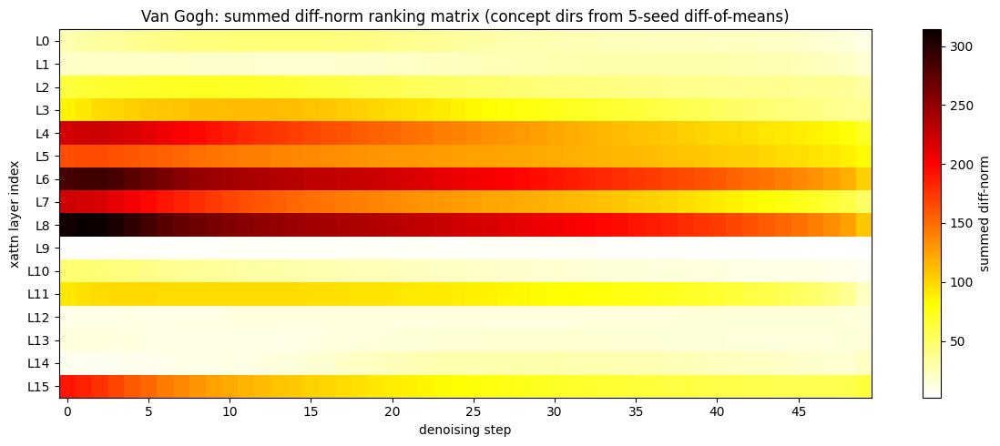

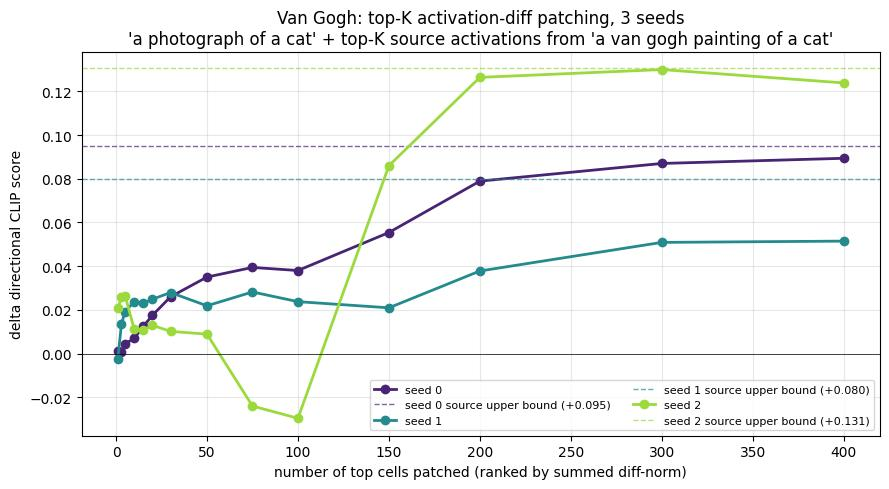

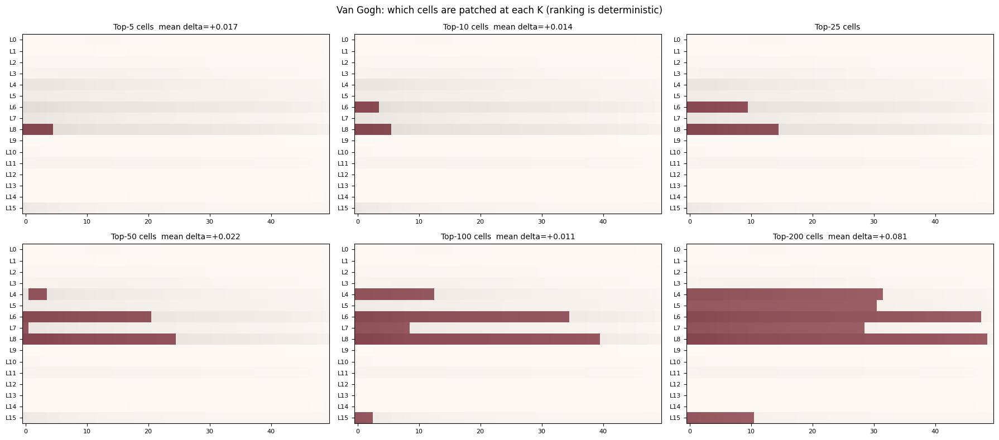

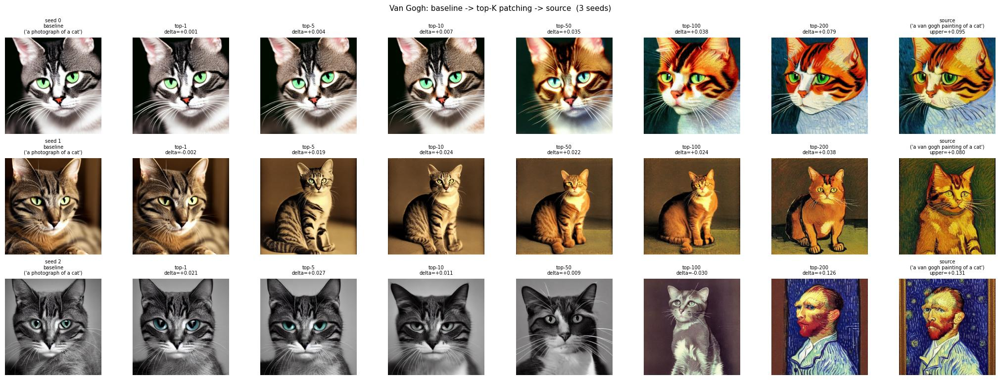

  Saved 4 figures to /content/drive/MyDrive/thesis_public_run with prefix 'vg_topk_'


In [61]:
# ============================================================
# Top-K activation-diff patching — VAN GOGH (3 seeds)
# ============================================================
vg_topk_results, vg_topk_images, vg_topk_extras = run_topk_actdiff_3seeds(
    concept_name    = "Van Gogh",
    save_prefix     = "vg",
    ranking_matrix  = vg_matrix,
    source_prompt   = "a van gogh painting of a cat",
    patch_prompt    = "a photograph of a cat",
    scorer          = vg_score,
)


[Nighttime] top-K activation-diff patching, 3 seeds
  source='a photograph of a city street at night'  patch='a photograph of a city street during the day'
  K values = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
  seeds    = [0, 1, 2]
  Top-10 cells by summed diff-norm:
    Rank   Layer  Step       score
       1  L5         0    147.3719
       2  L5         1    141.9797
       3  L5         2    134.8823
       4  L4         0    134.0814
       5  L4         1    131.2103
       6  L4         2    127.2732
       7  L5         3    127.0889
       8  L4         3    121.8615
       9  L5         4    119.0792
      10  L4         4    115.7791

  --- seed 0 ---
    baseline score = -0.0861
    source upper bound delta = +0.1455
    top-  1 (  0.1% of cells)  delta=+0.0007  (8.9s)
    top-  3 (  0.4% of cells)  delta=-0.0010  (11.1s)
    top-  5 (  0.6% of cells)  delta=-0.0023  (13.2s)
    top- 10 (  1.2% of cells)  delta=-0.0046  (15.4s)
    top- 15 (  1.9% of cel

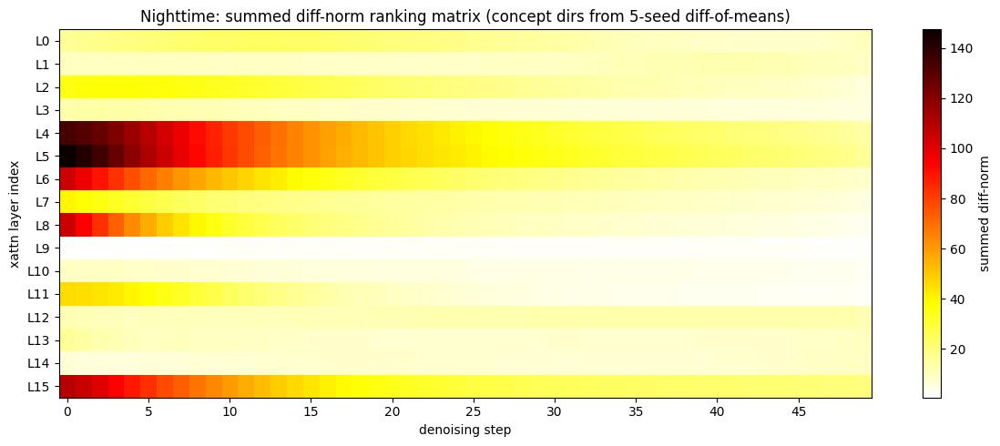

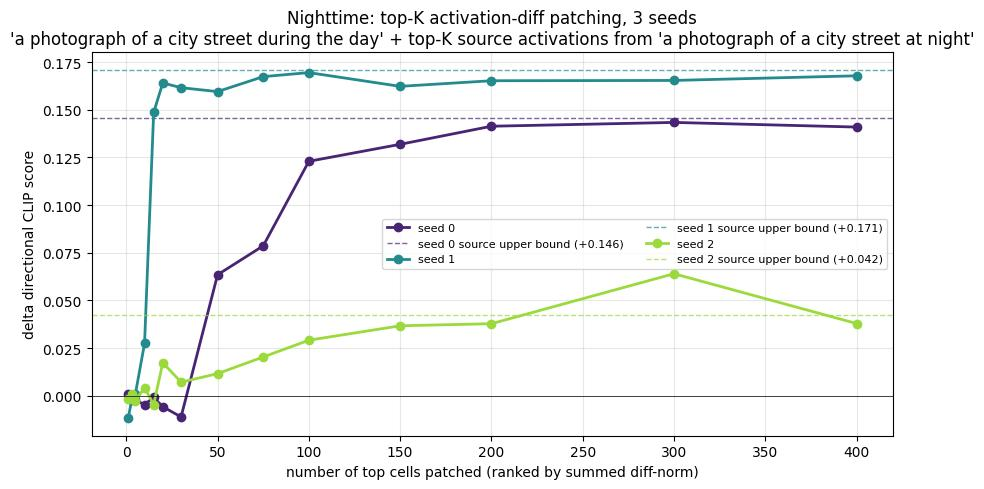

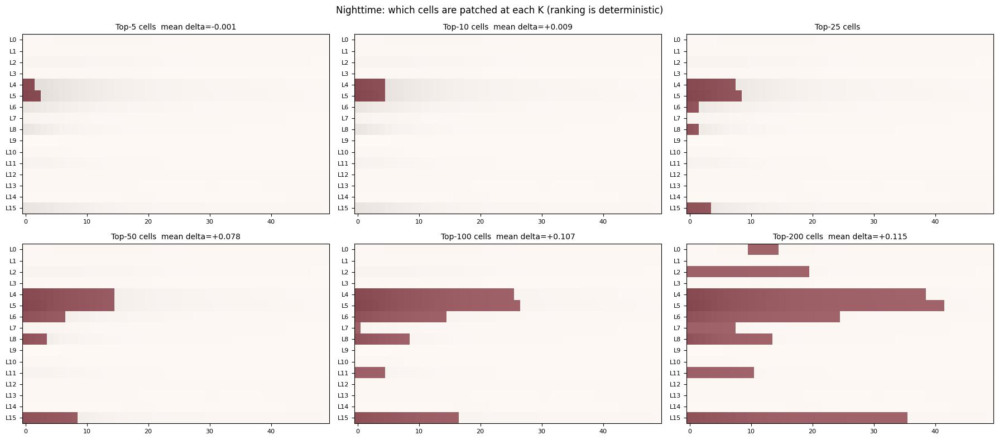

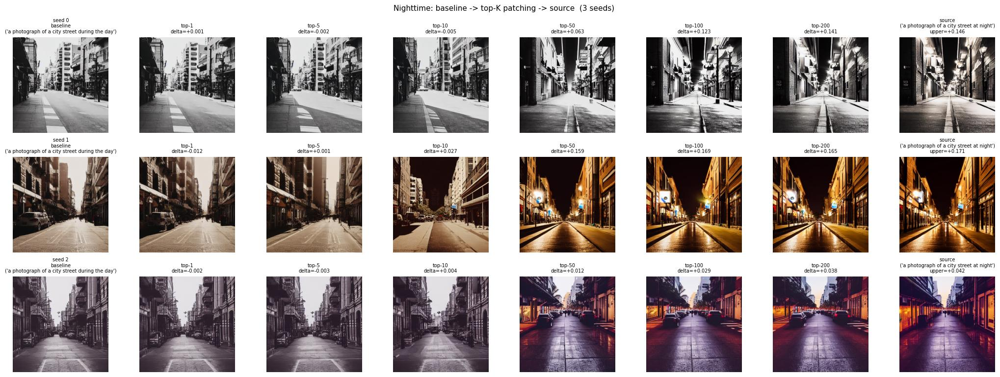

  Saved 4 figures to /content/drive/MyDrive/thesis_public_run with prefix 'night_topk_'


In [62]:
# ============================================================
# Top-K activation-diff patching — NIGHTTIME (3 seeds)
# ============================================================
night_topk_results, night_topk_images, night_topk_extras = run_topk_actdiff_3seeds(
    concept_name    = "Nighttime",
    save_prefix     = "night",
    ranking_matrix  = night_matrix,
    source_prompt   = "a photograph of a city street at night",
    patch_prompt    = "a photograph of a city street during the day",
    scorer          = night_score,
)


[Red] top-K activation-diff patching, 3 seeds
  source='a photograph of a red car'  patch='a photograph of a car'
  K values = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400]
  seeds    = [0, 1, 2]
  Top-10 cells by summed diff-norm:
    Rank   Layer  Step       score
       1  L8         0    103.8213
       2  L8         1     92.0026
       3  L4         1     83.3095
       4  L4         0     82.9254
       5  L4         2     81.0812
       6  L8         2     79.4904
       7  L15        0     77.2160
       8  L4         3     76.2734
       9  L15        1     76.1031
      10  L15        2     75.3854

  --- seed 0 ---
    baseline score = -0.0777
    source upper bound delta = +0.1484
    top-  1 (  0.1% of cells)  delta=+0.0087  (8.8s)
    top-  3 (  0.4% of cells)  delta=+0.0133  (11.0s)
    top-  5 (  0.6% of cells)  delta=+0.0136  (13.2s)
    top- 10 (  1.2% of cells)  delta=+0.1135  (15.4s)
    top- 15 (  1.9% of cells)  delta=+0.1166  (17.6s)
    top- 20 ( 

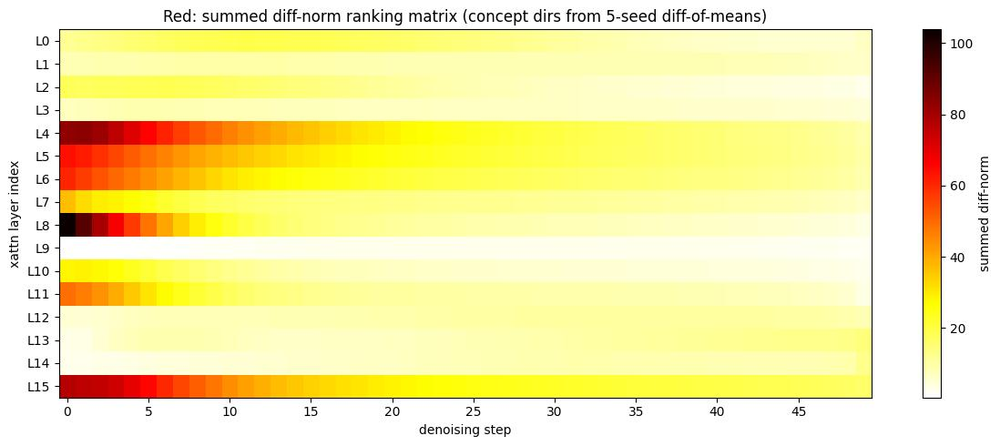

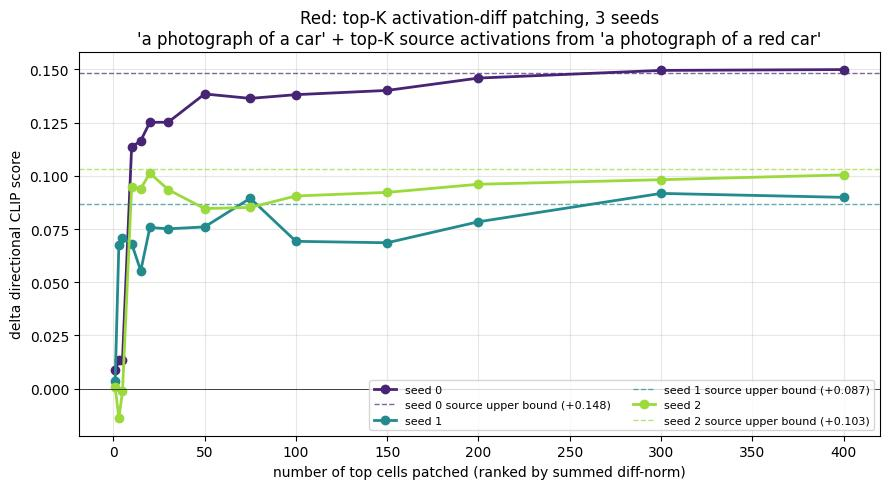

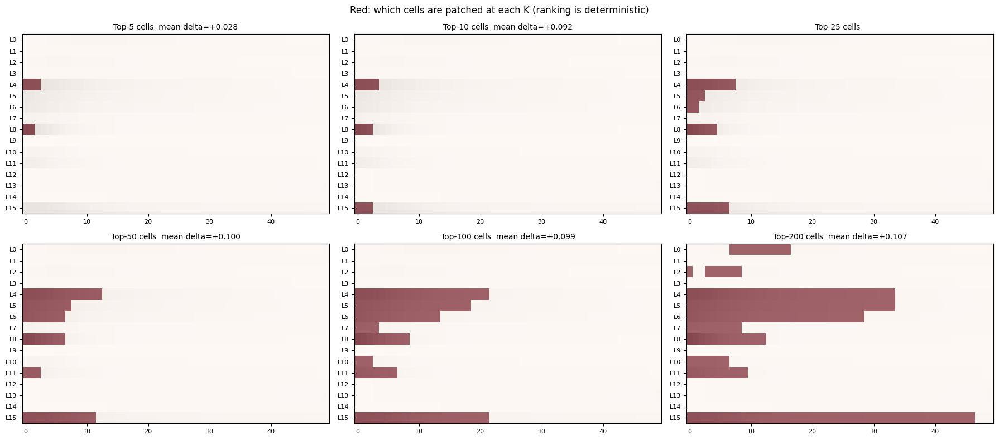

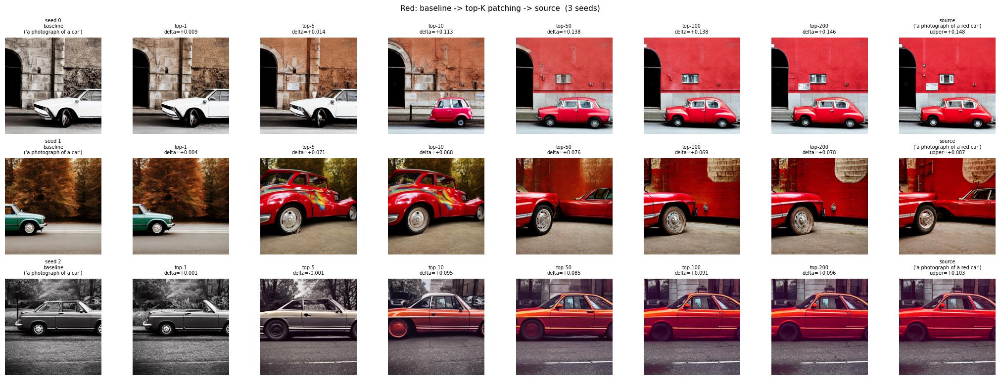

  Saved 4 figures to /content/drive/MyDrive/thesis_public_run with prefix 'red_topk_'


In [ ]:
# ============================================================
# Top-K activation-diff patching — RED (3 seeds)
# ============================================================
red_topk_results, red_topk_images, red_topk_extras = run_topk_actdiff_3seeds(
    concept_name    = "Red",
    save_prefix     = "red",
    ranking_matrix  = red_matrix,
    source_prompt   = "a photograph of a red car",
    patch_prompt    = "a photograph of a car",
    scorer          = red_score,
)

The first experiments of the thesis (Appendix A) were run in an earlier
notebook and are not repeated here.